# Trabalho de Conclusão de Disciplina — Introdução à Ciência de Dados

## Predição de Cargas de Aquecimento e Resfriamento de Edificações Residenciais utilizando Machine Learning

**Instituição:** FAT - Faculdade de Tecnologia UERJ - Resende

**Curso:** Pós-graduação - Especialização em Engenharia Industrial

**Disciplina:** Introdução à Ciência de Dados (ICD)

**Professor:** Vahid Nikoofard

**Aluno:** Neilson Martins de Oliveira

**Data:** Outubro de 2026

---

### 1 - Projeto TCC - Building Energy Efficiency

**Especificação inicial**

Utilizar a base pública Energy Efficiency, disponibilizada pelo UC Irvine Machine Learning Repository, para realizar o tratamento de dados, a análise exploratória (EDA), a modelagem e a interpretação dos resultados.

**1. Problema de pesquisa**

É possível prever as cargas de aquecimento (Heating Load) e resfriamento (Cooling Load) de uma edificação a partir de suas características arquitetônicas utilizando algoritmos de aprendizado supervisionado?

**2. Objetivo geral**

Desenvolver e comparar modelos de regressão capazes de estimar as cargas de aquecimento e resfriamento de edificações com base em suas características arquitetônicas.

**3. Abordagem**

Aprendizado supervisionado — regressão, utilizando métricas de erro e de qualidade preditiva para comparar os modelos.

**4. Metodologia**

Serão desenvolvidos modelos de regressão supervisionada para prever separadamente as Cargas de Aquecimento e Resfriamento das edificações, utilizando suas características arquitetônicas como variáveis explicativas.

Para cada variável-alvo, serão avaliados os algoritmos de Regressão Linear Múltipla e Random Forest Regressor, por meio de treinamento, teste e validação cruzada, utilizando as métricas MAE, RMSE e R² para comparar o desempenho preditivo.

### 2 - Importação das bibliotecas Python.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline


### 3 - Carga dos Dados

Neste projeto, será utilizado o conjunto de dados público *Energy Efficiency*, disponibilizado pelo **UCI Machine Learning Repository**, por meio do arquivo `ENB2012_data.xlsx`, disponível em:

https://archive.ics.uci.edu/dataset/242/energy+efficiency

A base de dados contém **768 observações e 10 variáveis**, sendo oito variáveis de entrada (X1 a X8), que representam características arquitetônicas das edificações residenciais, e duas variáveis de saída (Y1 e Y2), correspondentes às **Cargas de Aquecimento (Heating Load)** e **Resfriamento (Cooling Load)**.

Não existem valores ausentes no conjunto de dados.

É importante destacar que os dados foram obtidos por meio de simulações computacionais envolvendo **12 configurações geométricas distintas de edificações residenciais**, utilizando o software *Ecotect Analysis*, desenvolvido pela Autodesk. Portanto, as observações representam modelos computacionais de edificações, e não medições realizadas em construções reais.

Por se tratar de dados provenientes de simulações de edificações residenciais, os resultados dos modelos preditivos devem ser interpretados dentro das condições e limitações estabelecidas pelo estudo original, não sendo possível garantir sua generalização para outras tipologias de edificações sem validação adicional.

**Observação sobre a base de dados e o trabalho científico associado**

O conjunto de dados *Energy Efficiency* está associado ao estudo científico de **Tsanas e Xifara (2012)**, intitulado *Accurate quantitative estimation of energy performance of residential buildings using statistical machine learning tools*, publicado na revista *Energy and Buildings*.

Embora o referido estudo também aborde a previsão das cargas de aquecimento e resfriamento de edificações residenciais, a análise exploratória dos dados, a implementação dos modelos de aprendizado de máquina, a avaliação dos resultados e as conclusões apresentadas neste notebook foram desenvolvidas de forma independente, com o objetivo de aplicar e demonstrar os conhecimentos adquiridos na disciplina de Introdução à Ciência de Dados.

A referência ao artigo científico tem como finalidade contextualizar a origem e a utilização acadêmica do conjunto de dados, não significando que a metodologia ou os resultados deste projeto tenham sido reproduzidos a partir daquele estudo.

In [2]:
#Carga do Data Set
#Leia o arquivo ENB2012_data.xlsx como um DataFrame chamado de energy_efficiency.

from pathlib import Path

arquivo = Path("Dados") / "energy+efficiency" / "ENB2012_data.xlsx"

energy_efficiency = pd.read_excel(
    arquivo,
    engine="openpyxl"
)

### 4 - Preparação Inicial do DataFrame

Nesta etapa, o conjunto de dados é atribuído ao DataFrame `df`, e as colunas originais são renomeadas para facilitar a identificação e interpretação ao longo da análise.

In [3]:
# Atribuição do DataFrame e renomeação das colunas
df = energy_efficiency.rename(columns={
    "X1": "Compacidade Relativa",
    "X2": "Área de Superfície",
    "X3": "Área de Parede",
    "X4": "Área de Telhado",
    "X5": "Altura Total",
    "X6": "Orientação",
    "X7": "Área de Envidraçamento",
    "X8": "Distribuição da Área Envidraçada",
    "Y1": "Carga de Aquecimento",
    "Y2": "Carga de Resfriamento"
})

### 5 - Inspeção Inicial e Qualidade dos Dados

Nesta etapa, são examinadas as dimensões do DataFrame, a organização das variáveis, os tipos de dados e a existência de valores ausentes, registros duplicados ou combinações arquitetônicas repetidas, com o objetivo de avaliar a integridade inicial da base de dados.

In [4]:

# Dimensões do DataFrame
linhas, colunas = df.shape

print(f"Linhas: {linhas}")
print(f"Colunas: {colunas}")


Linhas: 768
Colunas: 10


In [5]:

df.head()

,Compacidade Relativa,Área de Superfície,Área de Parede,Área de Telhado,Altura Total,Orientação,Área de Envidraçamento,Distribuição da Área Envidraçada,Carga de Aquecimento,Carga de Resfriamento
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28


In [6]:

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 10 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Compacidade Relativa              768 non-null    float64
 1   Área de Superfície                768 non-null    float64
 2   Área de Parede                    768 non-null    float64
 3   Área de Telhado                   768 non-null    float64
 4   Altura Total                      768 non-null    float64
 5   Orientação                        768 non-null    int64  
 6   Área de Envidraçamento            768 non-null    float64
 7   Distribuição da Área Envidraçada  768 non-null    int64  
 8   Carga de Aquecimento              768 non-null    float64
 9   Carga de Resfriamento             768 non-null    float64
dtypes: float64(8), int64(2)
memory usage: 60.1 KB


In [7]:

df.isnull().sum()


Compacidade Relativa                0
Área de Superfície                  0
Área de Parede                      0
Área de Telhado                     0
Altura Total                        0
Orientação                          0
Área de Envidraçamento              0
Distribuição da Área Envidraçada    0
Carga de Aquecimento                0
Carga de Resfriamento               0
dtype: int64

In [8]:

# Quantidade de registros duplicados
df.duplicated().sum()

np.int64(0)

In [9]:

# Seleção das oito características arquitetônicas
caracteristicas = df.columns.drop([
    "Carga de Aquecimento",
    "Carga de Resfriamento"
])

# Verificação de combinações arquitetônicas repetidas
combinacoes_repetidas = df.duplicated(
    subset=caracteristicas
).sum()

print(f"Combinações arquitetônicas repetidas: {combinacoes_repetidas}")


Combinações arquitetônicas repetidas: 0


**Conclusão da inspeção inicial**

A base de dados apresenta 768 observações e 10 variáveis, sendo oito características arquitetônicas e duas cargas energéticas.

As verificações realizadas não identificaram valores ausentes, registros integralmente duplicados ou combinações arquitetônicas repetidas.

Dessa forma, não foi identificada necessidade de tratamento de valores ausentes ou exclusão de registros duplicados antes das etapas seguintes da análise.

### 6 - Estatística Descritiva do DataFrame

A estatística descritiva permite examinar as principais características das distribuições das variáveis, incluindo medidas de tendência central, dispersão e valores mínimos e máximos.

In [10]:

df.describe().T

,count,mean,std,min,25%,50%,75%,max
Compacidade Relativa,768.0,0.764167,0.105777,0.62,0.6825,0.75,0.8300,0.98
Área de Superfície,768.0,671.708333,88.086116,514.50,606.3750,673.75,741.1250,808.50
Área de Parede,768.0,318.500000,43.626481,245.00,294.0000,318.50,343.0000,416.50
Área de Telhado,768.0,176.604167,45.165950,110.25,140.8750,183.75,220.5000,220.50
Altura Total,768.0,5.250000,1.751140,3.50,3.5000,5.25,7.0000,7.00
Orientação,768.0,3.500000,1.118763,2.00,2.7500,3.50,4.2500,5.00
Área de Envidraçamento,768.0,0.234375,0.133221,0.00,0.1000,0.25,0.4000,0.40
Distribuição da Área Envidraçada,768.0,2.812500,1.550960,0.00,1.7500,3.00,4.0000,5.00
Carga de Aquecimento,768.0,22.307195,10.090204,6.01,12.9925,18.95,31.6675,43.10
Carga de Resfriamento,768.0,24.587760,9.513306,10.90,15.6200,22.08,33.1325,48.03


### 7 - Análise da Distribuição das Variáveis por Histogramas

Os histogramas permitem visualizar a distribuição de frequência dos valores das variáveis, auxiliando na identificação de concentrações, dispersões e padrões presentes na base de dados.

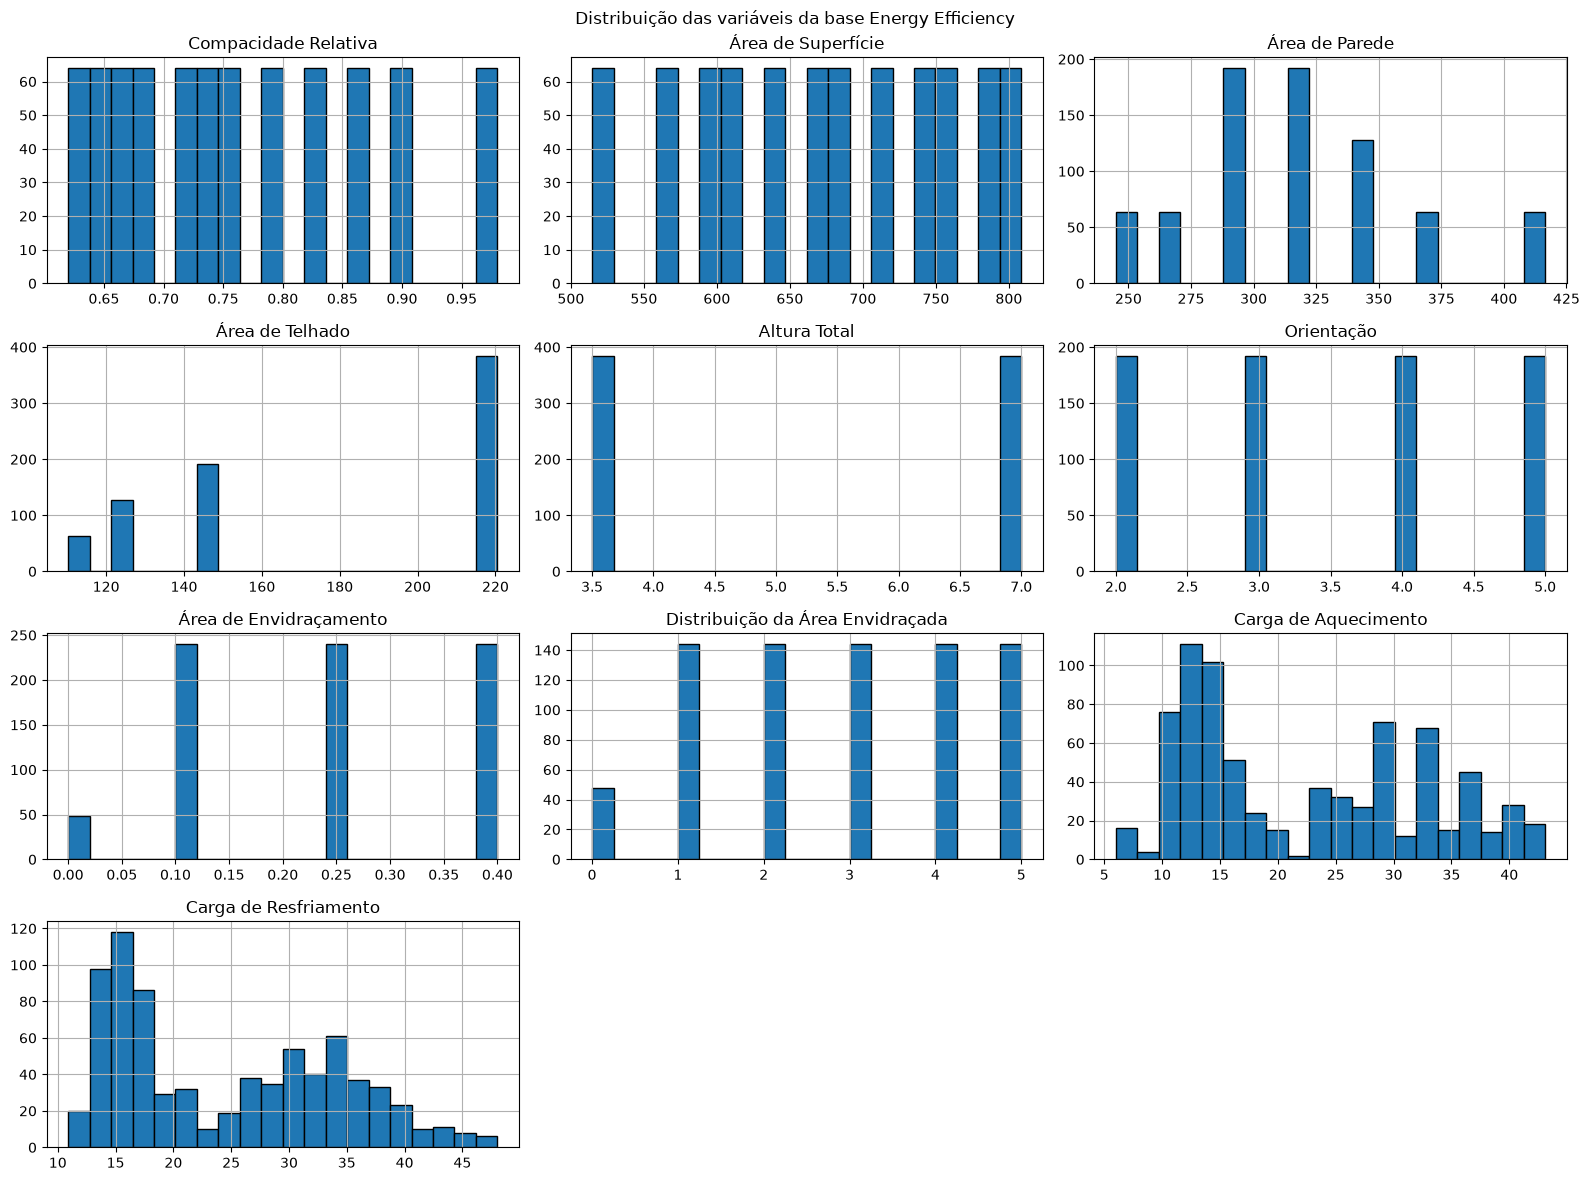

In [11]:

# Histogramas das variáveis do DataFrame

variaveis = df.select_dtypes(include="number").columns

df[variaveis].hist(
    bins=20,
    figsize=(16, 12),
    edgecolor="black"
)

plt.suptitle("Distribuição das variáveis da base Energy Efficiency")
plt.tight_layout()
plt.show()


**Interpretação geral dos histogramas**

Os histogramas evidenciam diferentes padrões de distribuição entre as variáveis da base *Energy Efficiency*. Algumas características arquitetônicas apresentam valores concentrados em níveis específicos, como a Altura Total, enquanto outras apresentam maior diversidade de valores. As variáveis Orientação e Distribuição da Área Envidraçada representam categorias codificadas numericamente, cuja distribuição será examinada na análise de frequências. As Cargas de Aquecimento e Resfriamento apresentam valores distribuídos ao longo de diferentes intervalos, permitindo observar a diversidade das demandas energéticas nas configurações simuladas.

Os histogramas das variáveis categóricas codificadas numericamente devem ser interpretados como distribuições de frequência de categorias, e não como distribuições contínuas.

### 8 - Análise de Frequência das Variáveis Discretas

A análise de frequências permite identificar a quantidade de ocorrências de cada valor nas variáveis discretas da base de dados, complementando a visualização das distribuições apresentada nos histogramas.

In [12]:

# Variáveis discretas e categóricas que serão analisadas
variaveis_discretas = [
    "Altura Total",
    "Orientação",
    "Distribuição da Área Envidraçada"
]

# Tabelas de frequência absoluta e relativa
for coluna in variaveis_discretas:
    frequencia = df[coluna].value_counts().sort_index()
    
    tabela_frequencia = pd.DataFrame({
        "Frequência absoluta": frequencia,
        "Frequência relativa (%)": (frequencia / len(df) * 100).round(2)
    })
    
    print(f"\nFrequência da variável: {coluna}")
    display(tabela_frequencia)



Frequência da variável: Altura Total


,Frequência absoluta,Frequência relativa (%)
Altura Total,,
3.5,384,50.0
7.0,384,50.0



Frequência da variável: Orientação


,Frequência absoluta,Frequência relativa (%)
Orientação,,
2,192,25.0
3,192,25.0
4,192,25.0
5,192,25.0



Frequência da variável: Distribuição da Área Envidraçada


,Frequência absoluta,Frequência relativa (%)
Distribuição da Área Envidraçada,,
0,48,6.25
1,144,18.75
2,144,18.75
3,144,18.75
4,144,18.75
5,144,18.75


**Interpretação da análise de frequências**

As tabelas de frequências permitem observar como as configurações arquitetônicas estão distribuídas entre os valores das variáveis discretas. Destacam-se a Altura Total, que apresenta apenas dois valores possíveis, e as variáveis Orientação e Distribuição da Área Envidraçada, cujos valores representam categorias. Essa análise complementa os histogramas e contribui para a compreensão da composição da base de dados, sem indicar, isoladamente, relações dessas características com as cargas energéticas.

### 9 - Verificação de valores atípicos (Outliers)

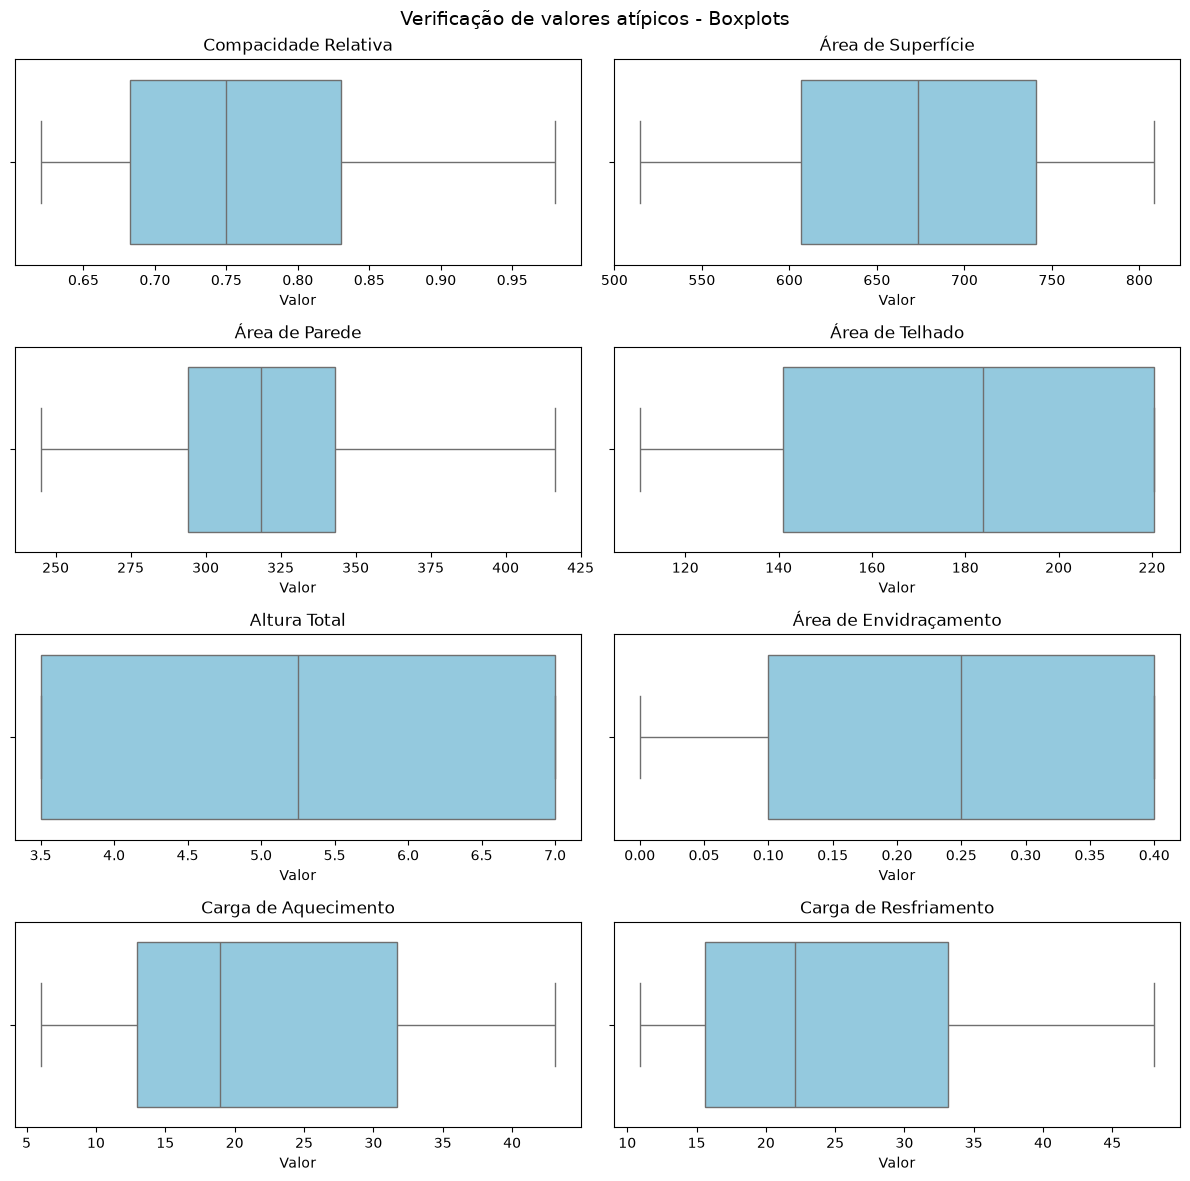

In [13]:

# Seleção das variáveis quantitativas
variaveis_quantitativas = [
    coluna for coluna in df.columns
    if coluna not in [
        "Orientação",
        "Distribuição da Área Envidraçada"
    ]
]

# Boxplots das variáveis quantitativas
fig, axes = plt.subplots(
    nrows=4,
    ncols=2,
    figsize=(12, 12)
)

axes = axes.flatten()

for i, coluna in enumerate(variaveis_quantitativas):
    sns.boxplot(
        x=df[coluna],
        whis=1.5,
        color="skyblue",
        ax=axes[i]
    )

    axes[i].set_title(coluna)
    axes[i].set_xlabel("Valor")

plt.suptitle(
    "Verificação de valores atípicos - Boxplots",
    fontsize=14
)

plt.tight_layout()
plt.show()


In [14]:

# Verificação numérica de outliers pelo método IQR
resultado_outliers = []

for coluna in variaveis_quantitativas:
    Q1 = df[coluna].quantile(0.25)
    Q3 = df[coluna].quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    quantidade = (
        (df[coluna] < limite_inferior) |
        (df[coluna] > limite_superior)
    ).sum()

    resultado_outliers.append({
        "Variável": coluna,
        "Outliers": int(quantidade)
    })

tabela_outliers = pd.DataFrame(resultado_outliers)

tabela_outliers


,Variável,Outliers
0,Compacidade Relativa,0
1,Área de Superfície,0
2,Área de Parede,0
3,Área de Telhado,0
4,Altura Total,0
5,Área de Envidraçamento,0
6,Carga de Aquecimento,0
7,Carga de Resfriamento,0


**Conclusão da verificação de valores atípicos**

A identificação de possíveis valores atípicos foi realizada por meio de boxplots e do método do Intervalo Interquartil (IQR), utilizando o critério de 1,5 × IQR.

Foram excluídas dessa verificação as variáveis Orientação e Distribuição da Área Envidraçada, por representarem categorias codificadas numericamente.

Não foram identificados valores atípicos nas variáveis quantitativas analisadas segundo o critério adotado. Portanto, não foi identificada necessidade de exclusão de observações por esse motivo.

### 10 - Identificação das variáveis independentes

In [15]:
#Identificando as variáveis independentes (x = Características arquitetônicas)

x = df[
    [
        "Compacidade Relativa",
        "Área de Superfície",
        "Área de Parede",
        "Área de Telhado",
        "Altura Total",
        "Orientação",
        "Área de Envidraçamento",
        "Distribuição da Área Envidraçada"
    ]
]

### 11 - Identificação das variáveis dependentes

In [16]:
#Identificando as variáveis dependentes (y = Cargas energéticas que queremos prever)

y = df[
    [
        "Carga de Aquecimento",
        "Carga de Resfriamento"
    ]
]

### 12 - Análise de Correlação

A análise de correlação de Pearson foi utilizada para investigar a intensidade e a direção das associações lineares entre as variáveis da base de dados.

Foram analisadas a correlação entre as Cargas de Aquecimento e Resfriamento e as correlações entre as características arquitetônicas e cada uma das cargas energéticas.

### 13 - Correlação entre as Cargas de Aquecimento e Resfriamento

In [17]:

# Correlação de Pearson entre as cargas energéticas
correlacao_cargas = df[
    "Carga de Aquecimento"
].corr(df["Carga de Resfriamento"])

print(f"Correlação entre Aquecimento e Resfriamento: {correlacao_cargas:.4f}")


Correlação entre Aquecimento e Resfriamento: 0.9759


**Conclusão da correlação entre as cargas energéticas**

O coeficiente de Pearson (r = 0,9759) indica uma correlação linear positiva muito forte entre as Cargas de Aquecimento e Resfriamento.

Isso significa que, nas configurações simuladas, edificações com maiores cargas de aquecimento tendem também a apresentar maiores cargas de resfriamento. Entretanto, essa associação não implica uma relação de causalidade entre as duas variáveis.

### 14 - Correlação entre as Características Arquitetônicas e as Cargas Energéticas

Os coeficientes de correlação de Pearson foram calculados entre as oito características arquitetônicas e as duas cargas energéticas. Os resultados são apresentados em gráficos de barras horizontais para facilitar a comparação.

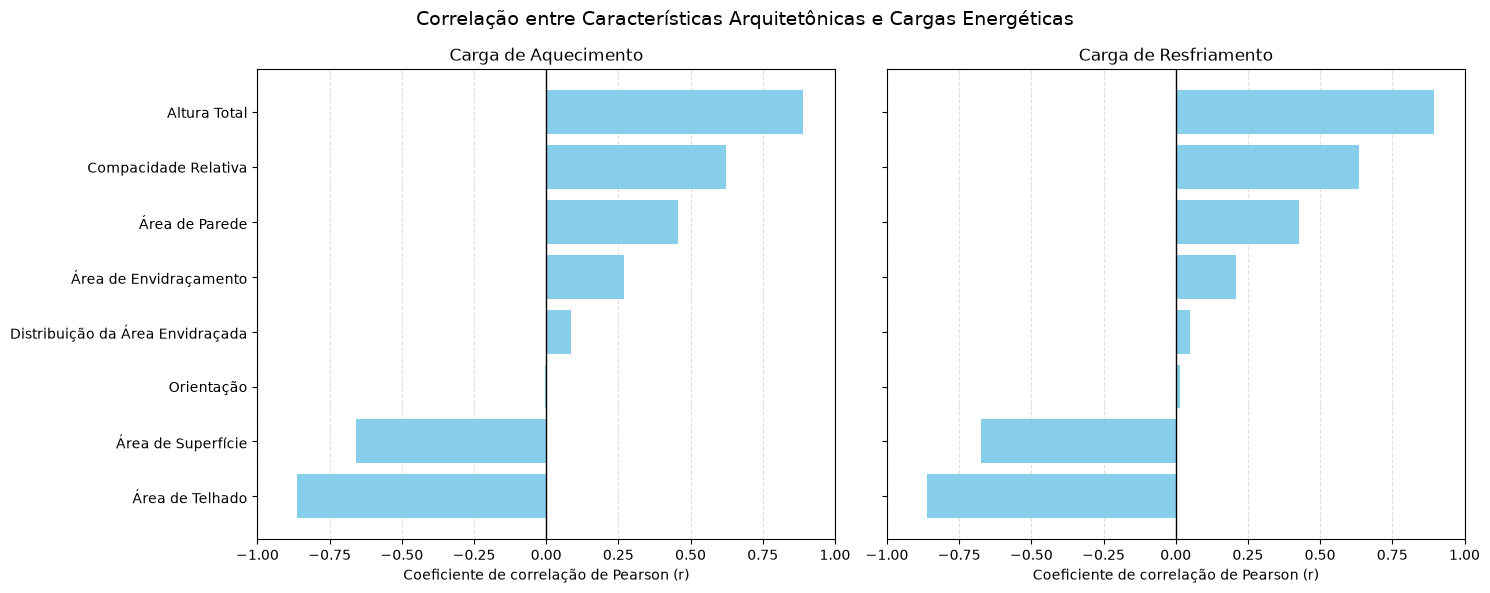

In [18]:

# Correlação entre as características arquitetônicas e as cargas
correlacao_xy = df.corr().loc[x.columns, y.columns]

# Ordenar as variáveis pela correlação com a Carga de Aquecimento
ordem_variaveis = (
    correlacao_xy["Carga de Aquecimento"]
    .sort_values()
    .index
)

# Gráficos comparativos
fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 6),
    sharey=True
)

for eixo, carga in zip(axes, y.columns):
    valores = correlacao_xy.loc[ordem_variaveis, carga]

    eixo.barh(
        valores.index,
        valores.values,
        color="skyblue"
    )

    eixo.axvline(0, color="black", linewidth=1)

    eixo.set_title(carga)
    eixo.set_xlabel("Coeficiente de correlação de Pearson (r)")
    eixo.set_xlim(-1, 1)
    eixo.grid(axis="x", linestyle="--", alpha=0.4)
    eixo.set_axisbelow(True)

fig.suptitle(
    "Correlação entre Características Arquitetônicas e Cargas Energéticas",
    fontsize=14
)

plt.tight_layout()
plt.show()


**Conclusão da correlação entre características arquitetônicas e cargas energéticas**

Os gráficos demonstram padrões semelhantes de correlação linear para as Cargas de Aquecimento e Resfriamento.

A **Altura Total** apresentou as maiores correlações positivas (r = 0,889 e r = 0,896), enquanto a **Área de Telhado** apresentou as maiores correlações negativas em magnitude (r = −0,862 e r = −0,863), respectivamente.

A Compacidade Relativa e a Área de Superfície também apresentaram associações relevantes com ambas as cargas. Por outro lado, Orientação e Distribuição da Área Envidraçada apresentaram coeficientes próximos de zero.

Como estas duas últimas variáveis representam categorias codificadas numericamente, seus coeficientes de Pearson devem ser interpretados com cautela.

Os resultados representam associações lineares, não relações de causalidade ou medidas diretas de importância preditiva.

## 15 - Conclusão da Análise Exploratória de Dados (EDA)

A análise exploratória da base *Energy Efficiency*, composta por 768 observações, oito características arquitetônicas e duas variáveis-alvo, permitiu examinar a estrutura, a qualidade e as principais características dos dados.

As verificações realizadas não identificaram valores ausentes, registros duplicados ou valores atípicos segundo o critério do Intervalo Interquartil (IQR), não sendo necessária a exclusão de observações por esses motivos.

A análise de correlação de Pearson revelou uma associação linear positiva muito forte entre as Cargas de Aquecimento e Resfriamento (r = 0,9759), indicando que ambas tendem a apresentar comportamentos semelhantes nas configurações simuladas.

Entre as características arquitetônicas, a Altura Total apresentou a maior correlação positiva com as cargas energéticas, enquanto a Área de Telhado apresentou a maior correlação negativa em magnitude.

As variáveis Orientação e Distribuição da Área Envidraçada apresentaram coeficientes de correlação próximos de zero. Entretanto, esses resultados devem ser interpretados com cautela, pois se trata de variáveis categóricas codificadas numericamente.

De modo geral, a análise exploratória identificou padrões relevantes de associação entre as características arquitetônicas e as cargas energéticas. Esses resultados fornecem uma base para a etapa seguinte, na qual serão desenvolvidos e comparados modelos de Regressão Linear Múltipla e Random Forest Regressor, com o objetivo de avaliar sua capacidade de previsão.

## 16 - Preparação dos dados para a modelagem preditiva

A modelagem preditiva utilizará técnicas de aprendizado supervisionado, com algoritmos de regressão, para estimar as cargas de aquecimento e resfriamento a partir das características arquitetônicas das edificações.

Serão desenvolvidos dois experimentos independentes:

- **Experimento 1:** previsão da Carga de Aquecimento.
- **Experimento 2:** previsão da Carga de Resfriamento.

Ambos utilizarão as mesmas oito variáveis independentes, previamente identificadas na análise exploratória.

Nesta etapa, serão definidos os conjuntos de dados para cada experimento, realizada a separação entre treinamento e teste e preparado o tratamento das variáveis categóricas.

Os modelos serão posteriormente treinados, avaliados e comparados por meio de métricas de desempenho preditivo.

In [19]:

# Aproveitar as variáveis independentes definidas na seção 10
X = x.copy()

# Separar as duas variáveis-alvo definidas na seção 11
y_aquecimento = y["Carga de Aquecimento"].copy()
y_resfriamento = y["Carga de Resfriamento"].copy()

# Conferir as dimensões dos dados
print("Dimensões de X:", X.shape)
print("Dimensões de y_aquecimento:", y_aquecimento.shape)
print("Dimensões de y_resfriamento:", y_resfriamento.shape)


Dimensões de X: (768, 8)
Dimensões de y_aquecimento: (768,)
Dimensões de y_resfriamento: (768,)


### 16.1 - Separação dos dados em treinamento e teste

Para avaliar a capacidade de generalização dos modelos preditivos, o conjunto de dados será dividido em duas partes:

- **Conjunto de treinamento (80%):** utilizado para ajustar os parâmetros dos algoritmos de aprendizado supervisionado.
- **Conjunto de teste (20%):** reservado para avaliar o desempenho dos modelos em observações não utilizadas durante o treinamento.

A separação será realizada utilizando a função `train_test_split` da biblioteca Scikit-learn.

Será utilizado o parâmetro `random_state=42` para garantir a reprodutibilidade da divisão.

Os dois experimentos, Carga de Aquecimento e Carga de Resfriamento, utilizarão a mesma divisão de observações, permitindo uma comparação metodologicamente consistente dos resultados.

O conjunto de teste será preservado até a avaliação final dos modelos. As decisões de pré-processamento e seleção de modelos deverão ser realizadas utilizando exclusivamente os dados de treinamento e os procedimentos de validação apropriados.

In [20]:

from sklearn.model_selection import train_test_split

# Separação simultânea de X e das duas variáveis-alvo
X_treino, X_teste, y_aq_treino, y_aq_teste, y_res_treino, y_res_teste = train_test_split(
    X,
    y_aquecimento,
    y_resfriamento,
    test_size=0.20,
    random_state=42
)

# Conferência das dimensões
print("X_treino:", X_treino.shape)
print("X_teste:", X_teste.shape)

print("y_aq_treino:", y_aq_treino.shape)
print("y_aq_teste:", y_aq_teste.shape)

print("y_res_treino:", y_res_treino.shape)
print("y_res_teste:", y_res_teste.shape)


X_treino: (614, 8)
X_teste: (154, 8)
y_aq_treino: (614,)
y_aq_teste: (154,)
y_res_treino: (614,)
y_res_teste: (154,)


**Confirmando a separação dos dados,**

Agora temos 614 observações para treinamento e 154 observações para teste, mantendo as mesmas observações nos dois experimentos: Carga de Aquecimento e Carga de Resfriamento.

### 16.2 - Identificação e tratamento das variáveis categóricas

O conjunto de dados contém variáveis numéricas contínuas e variáveis categóricas representadas por códigos inteiros.

As variáveis Orientação e Distribuição da Área Envidraçada representam categorias e, portanto, não devem ser interpretadas diretamente como grandezas quantitativas contínuas.

Para permitir sua utilização nos algoritmos de regressão, será aplicado o método One-Hot Encoding, que transforma cada categoria em uma variável indicadora binária.

As demais características arquitetônicas serão inicialmente tratadas como variáveis numéricas.

O pré-processamento será ajustado exclusivamente com os dados de treinamento e posteriormente aplicado aos dados de teste, evitando vazamento de informações.

In [21]:

# Identificação das variáveis categóricas
variaveis_categoricas = [
    "Orientação",
    "Distribuição da Área Envidraçada"
]

# Identificação das demais variáveis numéricas
variaveis_numericas_modelo = [
    coluna for coluna in X_treino.columns
    if coluna not in variaveis_categoricas
]

print("Variáveis categóricas:")
print(variaveis_categoricas)

print("\nVariáveis numéricas:")
print(variaveis_numericas_modelo)

print("\nQuantidade de variáveis categóricas:", len(variaveis_categoricas))
print("Quantidade de variáveis numéricas:", len(variaveis_numericas_modelo))


Variáveis categóricas:
['Orientação', 'Distribuição da Área Envidraçada']

Variáveis numéricas:
['Compacidade Relativa', 'Área de Superfície', 'Área de Parede', 'Área de Telhado', 'Altura Total', 'Área de Envidraçamento']

Quantidade de variáveis categóricas: 2
Quantidade de variáveis numéricas: 6


**Confirmando,**

No conjunto de dados de teste e treino, foram identificadas as 2 variáveis categóricas e as 6 variáveis numéricas que serão utilizadas na modelagem.

### 16.3 - Construção do pré-processamento dos dados

Nesta etapa, será construído um procedimento de pré-processamento utilizando a classe `ColumnTransformer` da biblioteca Scikit-learn.

Serão aplicadas duas transformações:

- **StandardScaler:** padronização das seis variáveis numéricas, utilizando a média e o desvio-padrão calculados exclusivamente a partir do conjunto de treinamento.
- **OneHotEncoder:** transformação das duas variáveis categóricas em colunas indicadoras binárias, evitando que seus códigos sejam interpretados como grandezas quantitativas.

O `ColumnTransformer` permitirá aplicar cada transformação somente às colunas correspondentes.

O pré-processamento será posteriormente incorporado a um `Pipeline`, integrando as transformações ao treinamento dos modelos e evitando vazamento de informações entre os conjuntos de treinamento e teste.

In [22]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Construção do pré-processamento
preprocessador = ColumnTransformer(
    transformers=[
        (
            "numericas",
            StandardScaler(),
            variaveis_numericas_modelo
        ),
        (
            "categoricas",
            OneHotEncoder(handle_unknown="ignore"),
            variaveis_categoricas
        )
    ]
)

print(preprocessador)


ColumnTransformer(transformers=[('numericas', StandardScaler(),
                                 ['Compacidade Relativa', 'Área de Superfície',
                                  'Área de Parede', 'Área de Telhado',
                                  'Altura Total', 'Área de Envidraçamento']),
                                ('categoricas',
                                 OneHotEncoder(handle_unknown='ignore'),
                                 ['Orientação',
                                  'Distribuição da Área Envidraçada'])])


**Acima temos o objeto pre-processador, que fará o ajuste de escala e transformação dos dados categóricos.**

# Construção e treinamento dos modelo preditivos

## 17 - Regressão Linear Múltipla - Carga de Aquecimento

### 17.1 - Construção e treinamento

O primeiro modelo preditivo será desenvolvido utilizando o algoritmo de Regressão Linear Múltipla, disponibilizado pela biblioteca Scikit-learn.

O objetivo é estimar a Carga de Aquecimento das edificações a partir das oito características arquitetônicas.

Será utilizado um `Pipeline` composto por duas etapas:

1. **Pré-processamento:** padronização das variáveis numéricas e codificação das variáveis categóricas.
2. **Regressão Linear:** ajuste dos coeficientes do modelo com base nas observações de treinamento.

O treinamento será realizado utilizando exclusivamente o conjunto de treinamento, composto por 614 observações.

O conjunto de teste permanecerá reservado para a avaliação final do desempenho preditivo.

In [23]:

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

# Construção do Pipeline para Carga de Aquecimento
modelo_linear_aquecimento = Pipeline(
    steps=[
        ("preprocessamento", preprocessador),
        ("regressao", LinearRegression())
    ]
)

# Treinamento do modelo
modelo_linear_aquecimento.fit(X_treino, y_aq_treino)

print("Modelo de Regressão Linear para Carga de Aquecimento treinado com sucesso!")


Modelo de Regressão Linear para Carga de Aquecimento treinado com sucesso!


### 17.2 - Previsão da Carga de Aquecimento com os Dados de Teste

Após o treinamento, o modelo de Regressão Linear Múltipla será utilizado para estimar a Carga de Aquecimento das 154 observações do conjunto de teste. Os valores previstos serão utilizados no cálculo das métricas de desempenho e na análise gráfica dos resultados.

In [24]:

# Realizar previsões da Carga de Aquecimento
y_aq_previsto = modelo_linear_aquecimento.predict(X_teste)

# Construir tabela para comparar valores reais e previstos
comparacao_aquecimento = pd.DataFrame({
    "Valor Real": y_aq_teste,
    "Valor Previsto": y_aq_previsto
})

# Calcular o erro de cada previsão
comparacao_aquecimento["Erro"] = (
    comparacao_aquecimento["Valor Real"]
    - comparacao_aquecimento["Valor Previsto"]
)

# Classificar as previsões
erro = comparacao_aquecimento["Erro"]

condicoes = [
    (erro > -1) & (erro < 0),
    erro <= -1,
    (erro > 0) & (erro < 1),
    erro >= 1
]

classificacoes = [
    "Superestimativa pequena",
    "Superestimativa",
    "Subestimativa pequena",
    "Subestimativa"
]

comparacao_aquecimento["Avaliação da Previsão"] = np.select(
    condicoes,
    classificacoes,
    default="Exata"
)

# Exibir as primeiras 10 previsões
comparacao_aquecimento.head(10).round(2)


,Valor Real,Valor Previsto,Erro,Avaliação da Previsão
668,16.47,18.68,-2.21,Superestimativa
324,13.17,14.75,-1.58,Superestimativa
624,32.82,31.14,1.68,Subestimativa
690,41.32,35.20,6.12,Subestimativa
473,16.69,14.97,1.72,Subestimativa
204,23.80,28.79,-4.99,Superestimativa
97,24.31,25.98,-1.67,Superestimativa
336,28.67,28.67,-0.00,Superestimativa pequena
568,19.52,18.01,1.51,Subestimativa
148,28.07,28.30,-0.23,Superestimativa pequena


### 17.3 - Avaliação do modelo de Regressão Linear — Carga de Aquecimento

O desempenho preditivo do modelo será avaliado utilizando as 154 observações do conjunto de teste.

Serão calculadas três métricas:

- **MAE (Mean Absolute Error):** erro absoluto médio das previsões.
- **RMSE (Root Mean Squared Error):** raiz do erro quadrático médio, que atribui maior penalização aos erros elevados.
- **R² (Coeficiente de Determinação):** medida da capacidade do modelo de explicar a variabilidade dos valores reais, em comparação com a previsão baseada na média.

As métricas permitirão quantificar o desempenho da Regressão Linear e estabelecer uma referência inicial para a comparação posterior com outros algoritmos.

Valores menores de MAE e RMSE indicam melhor desempenho, enquanto valores de R² mais próximos de 1 indicam maior capacidade explicativa no conjunto avaliado.

In [25]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Cálculo das métricas de avaliação
mae_aquecimento = mean_absolute_error(
    y_aq_teste, y_aq_previsto
)

rmse_aquecimento = np.sqrt(
    mean_squared_error(y_aq_teste, y_aq_previsto)
)

r2_aquecimento = r2_score(
    y_aq_teste, y_aq_previsto
)

# Exibição dos resultados
print(f"MAE:  {mae_aquecimento:.4f}")
print(f"RMSE: {rmse_aquecimento:.4f}")
print(f"R²:   {r2_aquecimento:.4f}")


MAE:  2.0590
RMSE: 2.8723
R²:   0.9209


**Análise dos resultados da Regressão Linear — Carga de Aquecimento**

O modelo de Regressão Linear Múltipla apresentou os seguintes resultados no conjunto de teste:

- **MAE = 2,0590:** as previsões apresentaram um erro absoluto médio de aproximadamente 2,06 unidades de carga de aquecimento.
- **RMSE = 2,8723:** a diferença entre RMSE e MAE indica a maior influência dos erros de maior magnitude sobre o erro quadrático médio.
- **R² = 0,9209:** o modelo explicou aproximadamente 92,09% da variabilidade da Carga de Aquecimento no conjunto de teste, em comparação com a previsão baseada na média.

Os resultados indicam um desempenho preditivo inicial favorável, demonstrando que a Regressão Linear Múltipla consegue representar uma parcela significativa das relações entre as características arquitetônicas e a Carga de Aquecimento.

Entretanto, a existência de erros individuais relativamente elevados demonstra que o modelo ainda apresenta limitações.

Esses resultados constituem uma avaliação exploratória inicial. A comparação e a seleção dos algoritmos serão realizadas utilizando procedimentos de validação nos dados de treinamento, preservando a avaliação final do conjunto de teste.

### 17.4 - Gráfico de dispersão dos valores reais e previstos — Carga de Aquecimento

O gráfico de dispersão será utilizado para avaliar visualmente o desempenho do modelo de Regressão Linear Múltipla, comparando os valores reais e os valores previstos da Carga de Aquecimento.

O gráfico apresentará:

- **Eixo X:** valores reais da Carga de Aquecimento.
- **Eixo Y:** valores previstos pelo modelo.
- **Linha diagonal de referência:** representa a condição ideal em que o valor previsto é igual ao valor real.

Quanto mais próximos os pontos estiverem da linha diagonal, menores serão os erros de previsão.

Pontos acima da diagonal representam superestimativas, enquanto pontos abaixo representam subestimativas.

A dispersão dos pontos em relação à linha de referência permitirá identificar visualmente a qualidade das previsões e possíveis padrões de erro do modelo.

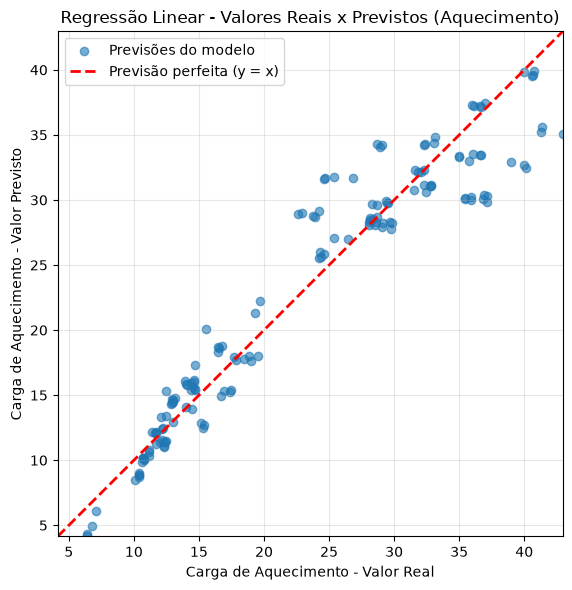

In [26]:

import matplotlib.pyplot as plt

# Definir os limites dos eixos
valor_minimo = min(y_aq_teste.min(), y_aq_previsto.min())
valor_maximo = max(y_aq_teste.max(), y_aq_previsto.max())

# Criar o gráfico
plt.figure(figsize=(8, 6))

# Pontos: valores reais x valores previstos
plt.scatter(
    y_aq_teste,
    y_aq_previsto,
    alpha=0.6,
    label="Previsões do modelo"
)

# Linha diagonal de referência (previsão perfeita)
plt.plot(
    [valor_minimo, valor_maximo],
    [valor_minimo, valor_maximo],
    "r--",
    linewidth=2,
    label="Previsão perfeita (y = x)"
)

# Identificação dos eixos e título
plt.xlabel("Carga de Aquecimento - Valor Real")
plt.ylabel("Carga de Aquecimento - Valor Previsto")
plt.title("Regressão Linear - Valores Reais x Previstos (Aquecimento)")

# Utilizar a mesma escala nos dois eixos
plt.xlim(valor_minimo, valor_maximo)
plt.ylim(valor_minimo, valor_maximo)
plt.gca().set_aspect("equal", adjustable="box")

# Exibir legenda e grade
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


**Análise do gráfico de dispersão — Valores Reais x Previstos (Carga de Aquecimento)**

O gráfico de dispersão apresenta uma concentração significativa de observações próximas da linha diagonal de referência, indicando uma boa correspondência geral entre os valores reais e os valores previstos da Carga de Aquecimento.

Esse comportamento é consistente com o coeficiente de determinação obtido pelo modelo (R² = 0,9209), que indica uma elevada capacidade de explicar a variabilidade dos dados no conjunto de teste.

Entretanto, observa-se que a dispersão dos pontos não é uniforme em todas as faixas de carga energética. Algumas observações, especialmente nas faixas intermediárias e elevadas, apresentam desvios mais acentuados em relação à linha de previsão perfeita.

Também são identificadas situações de superestimação e subestimação, demonstrando que o modelo não apresenta previsões igualmente precisas para todas as configurações arquitetônicas.

**Conclusão:** a Regressão Linear Múltipla apresentou desempenho preditivo inicial favorável, mas a dispersão observada sugere a necessidade de investigar os resíduos e avaliar possíveis padrões sistemáticos de erro.

A análise dos resíduos permitirá complementar a avaliação e identificar limitações que não são completamente evidentes nas métricas MAE, RMSE e R².

### 17.5 - Análise dos resíduos da Regressão Linear — Carga de Aquecimento

Os resíduos representam as diferenças entre os valores reais e os valores previstos pelo modelo de Regressão Linear Múltipla.

A análise dos resíduos permite investigar possíveis padrões sistemáticos de erro e complementar a avaliação realizada por meio das métricas MAE, RMSE e R².

Será construído um gráfico de dispersão contendo:

- **Eixo X:** valores previstos da Carga de Aquecimento.
- **Eixo Y:** resíduos, calculados pela diferença entre os valores reais e previstos.
- **Linha horizontal em zero:** representa a condição de previsão sem erro.

Uma distribuição aproximadamente aleatória dos resíduos em torno de zero é desejável, enquanto padrões sistemáticos, curvaturas ou alterações na dispersão podem indicar limitações do modelo.

O gráfico será utilizado para avaliar visualmente o comportamento dos erros nas diferentes faixas de carga energética.

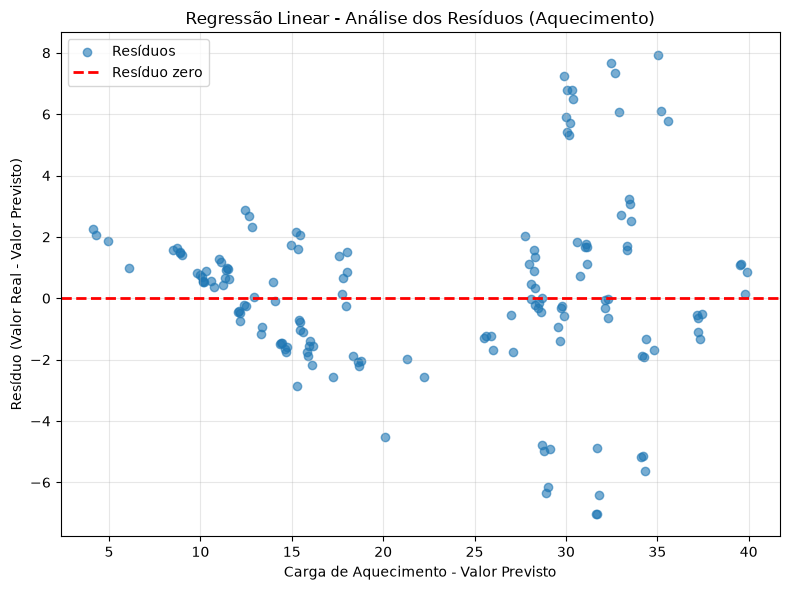

In [27]:

# Calcular os resíduos do modelo
residuos_aquecimento = y_aq_teste.to_numpy() - y_aq_previsto

# Criar o gráfico de dispersão dos resíduos
plt.figure(figsize=(8, 6))

plt.scatter(
    y_aq_previsto,
    residuos_aquecimento,
    alpha=0.6,
    label="Resíduos"
)

# Linha horizontal de referência (resíduo igual a zero)
plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Resíduo zero"
)

# Identificação dos eixos e título
plt.xlabel("Carga de Aquecimento - Valor Previsto")
plt.ylabel("Resíduo (Valor Real - Valor Previsto)")
plt.title("Regressão Linear - Análise dos Resíduos (Aquecimento)")

# Legenda e grade
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


**Análise e interpretação do gráfico dos resíduos**

O gráfico dos resíduos da Regressão Linear Múltipla apresenta valores positivos e negativos, demonstrando que o modelo realiza tanto subestimativas quanto superestimativas da Carga de Aquecimento.

Entretanto, a distribuição dos resíduos não se apresenta completamente aleatória ou uniforme. São observados agrupamentos de pontos e diferenças na amplitude dos erros entre determinadas faixas de carga energética prevista.

Nas faixas de valores previstos mais elevados, especialmente entre aproximadamente 28 e 35, observa-se uma dispersão mais acentuada dos resíduos, com valores positivos e negativos de maior magnitude.

Esse comportamento sugere a possibilidade de heterocedasticidade, caracterizada pela variação da dispersão dos erros ao longo dos valores previstos. Contudo, essa hipótese não pode ser confirmada apenas pela inspeção visual do gráfico.

Os agrupamentos observados também podem estar relacionados às características discretas das configurações arquitetônicas simuladas ou à existência de relações não lineares não representadas adequadamente pelo modelo.

**Conclusão:** embora a Regressão Linear Múltipla tenha apresentado um coeficiente de determinação elevado (R² = 0,9209), a análise dos resíduos evidencia possíveis limitações na representação das relações entre as características arquitetônicas e a Carga de Aquecimento.

Essas observações justificam a investigação posterior de algoritmos de regressão capazes de representar relações não lineares, utilizando procedimentos adequados de validação para comparar seus desempenhos.

### 17.6 - Histograma dos resíduos da Regressão Linear — Carga de Aquecimento

Para complementar a avaliação do modelo de Regressão Linear Múltipla, será construído um histograma dos resíduos obtidos no conjunto de teste.

O histograma permitirá analisar a distribuição de frequência dos erros de previsão, identificando sua concentração, simetria e possíveis valores extremos.

O gráfico apresentará:

- **Eixo X:** resíduos, calculados pela diferença entre os valores reais e os previstos.
- **Eixo Y:** frequência absoluta das observações em cada intervalo de resíduos.
- **Linha vertical em zero:** referência correspondente à ausência de erro.

Uma concentração de resíduos próximos de zero indica que muitas previsões apresentam erros de pequena magnitude.

A análise também permitirá investigar se a distribuição apresenta assimetria, múltiplos picos ou caudas extensas.

A inspeção visual do histograma será utilizada como avaliação exploratória, não sendo suficiente, isoladamente, para confirmar a normalidade dos resíduos.

Adicionalmente, será sobreposta ao histograma uma curva de distribuição normal (Gaussiana), ajustada utilizando a média e o desvio-padrão dos resíduos observados.

Essa representação permitirá comparar visualmente a distribuição empírica dos erros com uma distribuição normal teórica, contribuindo para a identificação de possíveis assimetrias, concentrações distintas e diferenças nas caudas da distribuição.

A comparação será utilizada como ferramenta exploratória e não como comprovação estatística de normalidade.

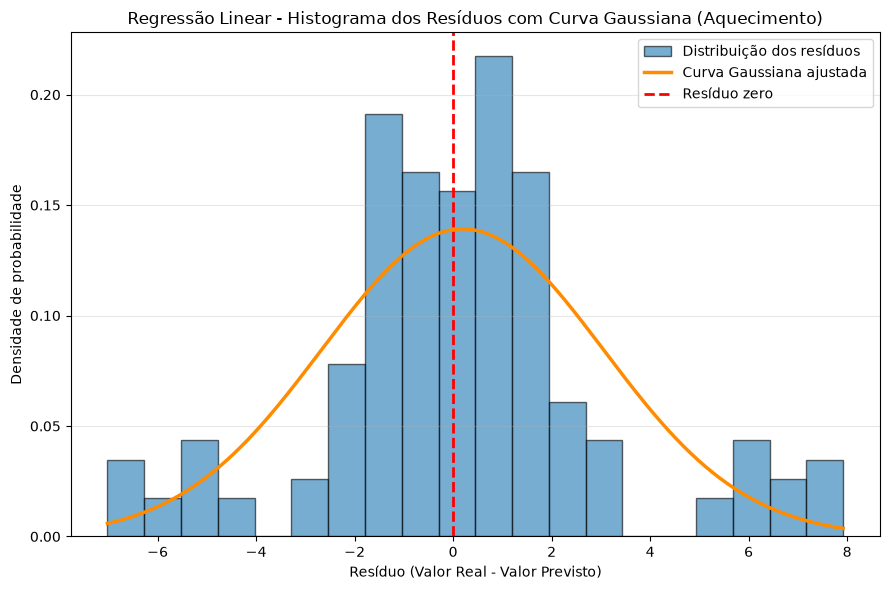

Média dos resíduos: 0.1906
Desvio-padrão dos resíduos: 2.8659


In [28]:

import numpy as np
from scipy.stats import norm

# Calcular a média e o desvio-padrão dos resíduos
media_residuos = np.mean(residuos_aquecimento)
desvio_residuos = np.std(residuos_aquecimento)

# Criar o gráfico
plt.figure(figsize=(9, 6))

# Histograma normalizado para densidade
plt.hist(
    residuos_aquecimento,
    bins=20,
    density=True,
    edgecolor="black",
    alpha=0.6,
    label="Distribuição dos resíduos"
)

# Valores do eixo X para construir a curva Gaussiana
x_gauss = np.linspace(
    residuos_aquecimento.min(),
    residuos_aquecimento.max(),
    300
)

# Calcular a densidade da distribuição normal ajustada
y_gauss = norm.pdf(
    x_gauss,
    loc=media_residuos,
    scale=desvio_residuos
)

# Desenhar a curva Gaussiana
plt.plot(
    x_gauss,
    y_gauss,
    color="darkorange",
    linewidth=2.5,
    label="Curva Gaussiana ajustada"
)

# Linha vertical de referência (resíduo zero)
plt.axvline(
    x=0,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Resíduo zero"
)

# Identificação dos eixos e título
plt.xlabel("Resíduo (Valor Real - Valor Previsto)")
plt.ylabel("Densidade de probabilidade")
plt.title("Regressão Linear - Histograma dos Resíduos com Curva Gaussiana (Aquecimento)")

# Legenda e grade
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# Exibir os parâmetros da curva
print(f"Média dos resíduos: {media_residuos:.4f}")
print(f"Desvio-padrão dos resíduos: {desvio_residuos:.4f}")


**Análise e interpretação do histograma dos resíduos com curva Gaussiana**

O histograma dos resíduos da Regressão Linear Múltipla apresenta uma concentração predominante de erros próximos de zero, especialmente no intervalo aproximado entre -2 e +2 unidades de Carga de Aquecimento.

A sobreposição da curva Gaussiana, ajustada a partir da média e do desvio-padrão dos resíduos, permite observar diferenças entre a distribuição empírica dos erros e uma distribuição normal teórica.

Na região central, algumas barras apresentam densidades superiores às da curva Gaussiana, indicando uma concentração expressiva de resíduos de pequena magnitude.

Entretanto, também são observados grupos de resíduos nas extremidades da distribuição, aproximadamente entre -7 e -4 e entre +5 e +8, correspondentes a superestimativas e subestimativas relativamente elevadas.

Esses grupos contribuem para o aumento do RMSE (2,8723) em relação ao MAE (2,0590), devido à maior penalização dos erros elevados no cálculo do RMSE.

A distribuição observada não acompanha completamente o formato suave e simétrico da curva Gaussiana, apresentando concentrações distintas e regiões com baixa frequência. Essas características sugerem possíveis desvios da normalidade, embora a análise visual não seja suficiente para confirmá-los estatisticamente.

**Conclusão:** o modelo de Regressão Linear Múltipla apresenta uma concentração significativa de previsões com erros pequenos, mas também produz erros relativamente elevados para determinadas observações.

A comparação com a curva Gaussiana reforça a necessidade de uma análise crítica da distribuição dos resíduos e complementa os resultados obtidos pelas métricas MAE, RMSE e R².

Em conjunto com os gráficos anteriores, esses resultados sugerem que a Regressão Linear pode não representar integralmente determinadas relações entre as características arquitetônicas e a Carga de Aquecimento, justificando a comparação posterior com algoritmos capazes de modelar relações não lineares.

## 18 - Regressão Linear Múltipla para a Carga de Resfriamento

### 18.1 - Construção e treinamento do modelo preditivo

Regressão Linear Múltipla para estimar a Carga de Resfriamento das edificações, utilizando as oito características arquitetônicas disponíveis no conjunto de dados Energy Efficiency.

Será adotada a mesma metodologia utilizada anteriormente para a previsão da Carga de Aquecimento, permitindo uma comparação consistente entre os resultados.

O modelo será construído por meio de um `Pipeline` composto por duas etapas:

1. **Pré-processamento:** padronização das variáveis numéricas com `StandardScaler` e codificação das variáveis categóricas com `OneHotEncoder`.
2. **Regressão Linear:** treinamento do algoritmo `LinearRegression` utilizando as observações de treinamento.

Serão utilizadas as mesmas 614 observações de treinamento definidas na seção 16.1, tendo como variável-alvo a Carga de Resfriamento.

O conjunto de teste, composto por 154 observações, será mantido separado do treinamento.

Após o ajuste do modelo, serão realizadas previsões e análises de desempenho, seguindo os mesmos critérios adotados para a Carga de Aquecimento.

In [29]:

# Construção do Pipeline para Carga de Resfriamento
modelo_linear_resfriamento = Pipeline(
    steps=[
        ("preprocessamento", preprocessador),
        ("regressao", LinearRegression())
    ]
)

# Treinamento do modelo
modelo_linear_resfriamento.fit(X_treino, y_res_treino)

print("Modelo de Regressão Linear para Carga de Resfriamento treinado com sucesso!")


Modelo de Regressão Linear para Carga de Resfriamento treinado com sucesso!


### 18.2 - Previsão da Carga de Resfriamento com os dados de teste

Após o treinamento do modelo de Regressão Linear Múltipla, serão realizadas previsões utilizando as 154 observações reservadas para teste.

O método `predict()` será utilizado para estimar os valores da Carga de Resfriamento a partir das características arquitetônicas contidas em `X_teste`.

Os valores previstos serão comparados com os valores reais armazenados em `y_res_teste`.

Também serão calculados os resíduos, definidos como a diferença entre os valores reais e previstos, permitindo identificar situações de superestimação e subestimação.

Essa comparação constitui a primeira etapa da avaliação preditiva do modelo de resfriamento.

In [30]:

# Realizar previsões para as observações de teste
y_res_previsto = modelo_linear_resfriamento.predict(X_teste)

# Construir tabela para comparar valores reais e previstos
comparacao_resfriamento = pd.DataFrame({
    "Valor Real": y_res_teste,
    "Valor Previsto": y_res_previsto
})

# Calcular o erro de cada previsão
comparacao_resfriamento["Erro"] = (
    comparacao_resfriamento["Valor Real"]
    - comparacao_resfriamento["Valor Previsto"]
)

# Classificar as previsões de acordo com o sinal e a magnitude do erro
erro = comparacao_resfriamento["Erro"]

condicoes = [
    (erro > -1) & (erro < 0),
    erro <= -1,
    (erro > 0) & (erro < 1),
    erro >= 1
]

classificacoes = [
    "Superestimativa pequena",
    "Superestimativa",
    "Subestimativa pequena",
    "Subestimativa"
]

comparacao_resfriamento["Avaliação da Previsão"] = np.select(
    condicoes,
    classificacoes,
    default="Exata"
)

# Exibir as primeiras 10 previsões
comparacao_resfriamento.head(10).round(2)


,Valor Real,Valor Previsto,Erro,Avaliação da Previsão
668,16.90,19.97,-3.07,Superestimativa
324,16.39,17.31,-0.92,Superestimativa pequena
624,32.78,32.21,0.57,Subestimativa pequena
690,46.23,36.38,9.85,Subestimativa
473,19.76,16.92,2.84,Subestimativa
204,24.61,31.58,-6.97,Superestimativa
97,25.63,27.74,-2.11,Superestimativa
336,29.62,30.36,-0.74,Superestimativa pequena
568,22.72,19.69,3.03,Subestimativa
148,34.14,30.51,3.63,Subestimativa


### 18.3 - Avaliação do modelo de Regressão Linear — Carga de Resfriamento

O desempenho preditivo do modelo de Regressão Linear Múltipla para a Carga de Resfriamento será avaliado utilizando as 154 observações do conjunto de teste.

Serão calculadas as mesmas métricas utilizadas anteriormente para a Carga de Aquecimento:

- **MAE (Mean Absolute Error):** erro absoluto médio das previsões.
- **RMSE (Root Mean Squared Error):** raiz do erro quadrático médio, que atribui maior penalização aos erros elevados.
- **R² (Coeficiente de Determinação):** medida da variabilidade explicada pelo modelo em comparação com uma previsão baseada na média dos valores reais.

A utilização das mesmas métricas permitirá uma comparação consistente entre os desempenhos dos modelos de aquecimento e resfriamento.

Os resultados serão interpretados considerando tanto a magnitude dos erros quanto a capacidade do modelo de representar a variabilidade da Carga de Resfriamento.

In [31]:

# Cálculo das métricas de avaliação - Carga de Resfriamento

mae_resfriamento = mean_absolute_error(
    y_res_teste, y_res_previsto
)

rmse_resfriamento = np.sqrt(
    mean_squared_error(y_res_teste, y_res_previsto)
)

r2_resfriamento = r2_score(
    y_res_teste, y_res_previsto
)

# Exibição dos resultados
print(f"MAE:  {mae_resfriamento:.4f}")
print(f"RMSE: {rmse_resfriamento:.4f}")
print(f"R²:   {r2_resfriamento:.4f}")


MAE:  2.1805
RMSE: 3.1198
R²:   0.8950


**Análise dos resultados da Regressão Linear — Carga de Resfriamento**

O modelo de Regressão Linear Múltipla apresentou os seguintes resultados no conjunto de teste:

- **MAE = 2,1805:** as previsões apresentaram um erro absoluto médio de aproximadamente 2,18 unidades de Carga de Resfriamento.
- **RMSE = 3,1198:** o erro quadrático médio, após a aplicação da raiz quadrada, foi de aproximadamente 3,12 unidades, indicando maior influência dos erros de maior magnitude.
- **R² = 0,8950:** o modelo explicou aproximadamente 89,50% da variabilidade da Carga de Resfriamento no conjunto de teste, em comparação com a previsão baseada na média.

Comparando esses resultados com os obtidos para a Carga de Aquecimento (MAE = 2,0590; RMSE = 2,8723; R² = 0,9209), observa-se que o modelo de resfriamento apresentou erros absolutos e quadráticos ligeiramente maiores, além de um coeficiente de determinação inferior.

Apesar dessas diferenças, ambos os modelos apresentaram desempenho preditivo inicial favorável.

**Conclusão:** a Regressão Linear Múltipla demonstrou capacidade de representar uma parcela significativa da variabilidade das duas cargas energéticas. Entretanto, o desempenho foi ligeiramente inferior para a Carga de Resfriamento, considerando as métricas calculadas nos respectivos conjuntos de teste.

A comparação constitui uma avaliação inicial, não sendo suficiente para estabelecer conclusões definitivas sobre a superioridade de um modelo ou a dificuldade relativa de previsão das duas variáveis-alvo.

### 18.4 - Gráfico de dispersão dos valores reais e previstos — Carga de Resfriamento

Para avaliar visualmente o desempenho da Regressão Linear Múltipla na previsão da Carga de Resfriamento, será construído um gráfico de dispersão comparando os valores reais e previstos das 154 observações do conjunto de teste.

O eixo horizontal representará os valores reais, enquanto o eixo vertical apresentará os valores previstos pelo modelo.

Será incluída uma linha diagonal de referência, correspondente à condição de previsão perfeita.

A proximidade dos pontos em relação à diagonal permitirá avaliar visualmente a correspondência entre as previsões e os valores reais, além de identificar possíveis padrões de superestimação ou subestimação.

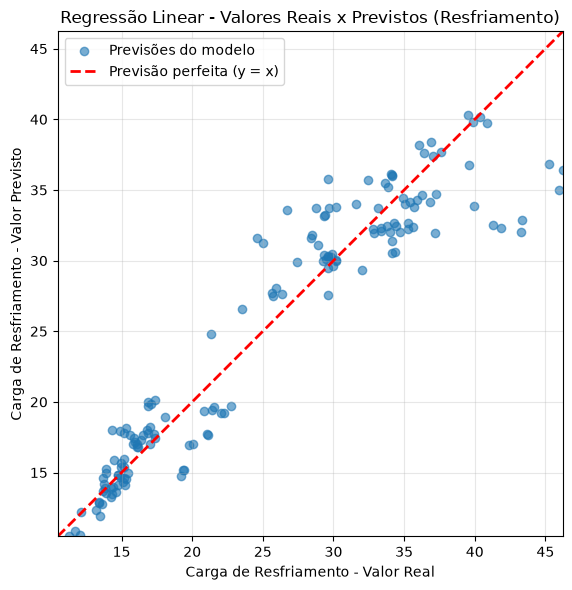

In [32]:

# Definir os limites dos eixos
valor_minimo_res = min(y_res_teste.min(), y_res_previsto.min())
valor_maximo_res = max(y_res_teste.max(), y_res_previsto.max())

# Criar o gráfico
plt.figure(figsize=(8, 6))

# Pontos: valores reais x valores previstos
plt.scatter(
    y_res_teste,
    y_res_previsto,
    alpha=0.6,
    label="Previsões do modelo"
)

# Linha diagonal de referência
plt.plot(
    [valor_minimo_res, valor_maximo_res],
    [valor_minimo_res, valor_maximo_res],
    "r--",
    linewidth=2,
    label="Previsão perfeita (y = x)"
)

# Identificação dos eixos e título
plt.xlabel("Carga de Resfriamento - Valor Real")
plt.ylabel("Carga de Resfriamento - Valor Previsto")
plt.title("Regressão Linear - Valores Reais x Previstos (Resfriamento)")

# Mesma escala nos dois eixos
plt.xlim(valor_minimo_res, valor_maximo_res)
plt.ylim(valor_minimo_res, valor_maximo_res)
plt.gca().set_aspect("equal", adjustable="box")

# Legenda e grade
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


**Análise do gráfico de dispersão — Valores Reais x Previstos (Carga de Resfriamento)**

O gráfico de dispersão apresenta uma correspondência geral satisfatória entre os valores reais e previstos da Carga de Resfriamento, com uma parcela significativa das observações relativamente próxima da linha de previsão perfeita.

Entretanto, observa-se que a dispersão dos pontos varia ao longo das diferentes faixas de carga energética.

Nas faixas de cargas mais baixas, os valores previstos apresentam, em geral, maior proximidade com os valores reais. Na região intermediária, aproximadamente entre 25 e 40, observa-se maior dispersão, indicando erros de previsão mais expressivos em determinadas observações.

Para algumas cargas reais superiores a 40, verifica-se uma tendência visual de subestimação, com valores previstos significativamente inferiores aos observados.

Esse comportamento sugere que o modelo linear pode apresentar limitações na representação de determinadas relações entre as características arquitetônicas e a Carga de Resfriamento, especialmente nas observações com cargas mais elevadas.

**Conclusão:** embora o modelo apresente boa capacidade preditiva global, conforme indicado pelo R² de 0,8950, o gráfico evidencia diferenças na precisão das previsões ao longo das faixas de carga. A análise dos resíduos permitirá investigar melhor esses padrões e possíveis limitações do modelo.

### 18.5 - Gráfico de dispersão dos resíduos — Carga de Resfriamento

A análise dos resíduos permite investigar o comportamento dos erros produzidos pelo modelo de Regressão Linear Múltipla.

Os resíduos serão calculados pela diferença entre os valores reais e previstos da Carga de Resfriamento.

Será construído um gráfico de dispersão relacionando os valores previstos, no eixo horizontal, aos resíduos, no eixo vertical.

A linha horizontal correspondente ao resíduo zero representará a condição de previsão perfeita.

A distribuição dos pontos permitirá verificar possíveis padrões de erro, mudanças na dispersão dos resíduos e tendências de superestimação ou subestimação em determinadas faixas de carga energética.

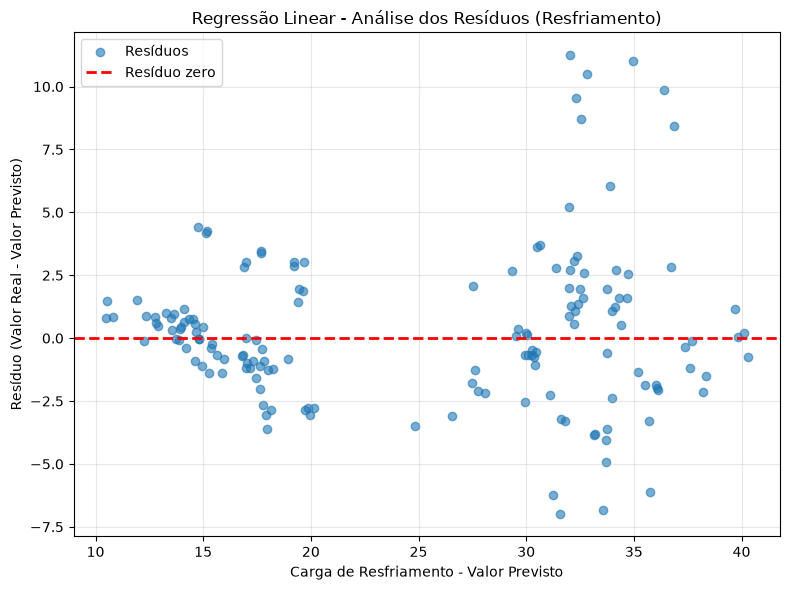

In [33]:

# Calcular os resíduos da Carga de Resfriamento
residuos_resfriamento = (
    y_res_teste.to_numpy() - y_res_previsto
)

# Criar o gráfico de dispersão dos resíduos
plt.figure(figsize=(8, 6))

plt.scatter(
    y_res_previsto,
    residuos_resfriamento,
    alpha=0.6,
    label="Resíduos"
)

# Linha horizontal correspondente ao resíduo zero
plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Resíduo zero"
)

plt.xlabel("Carga de Resfriamento - Valor Previsto")
plt.ylabel("Resíduo (Valor Real - Valor Previsto)")
plt.title("Regressão Linear - Análise dos Resíduos (Resfriamento)")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


**Análise do gráfico de dispersão dos resíduos — Carga de Resfriamento**

O gráfico de dispersão dos resíduos apresenta valores positivos e negativos em relação à linha horizontal correspondente ao resíduo zero, demonstrando a ocorrência de subestimativas e superestimativas pelo modelo de Regressão Linear Múltipla.

Entretanto, a distribuição dos resíduos não se apresenta completamente aleatória, sendo possível identificar agrupamentos e diferenças na dispersão dos erros entre as faixas de carga prevista.

Nas faixas de carga prevista mais baixas, aproximadamente entre 10 e 15, os resíduos encontram-se relativamente concentrados próximos de zero. Por outro lado, na região entre 30 e 37, observa-se uma dispersão significativamente maior, incluindo resíduos positivos próximos de +11 e negativos próximos de −7.

Esse comportamento sugere que a precisão das previsões varia conforme a faixa de carga energética, constituindo um possível indício de heterocedasticidade, embora sua confirmação exija testes estatísticos específicos.

Também são observados erros individuais elevados, demonstrando que, apesar do coeficiente de determinação de 0,8950, o modelo apresenta limitações na previsão de determinadas observações.

**Conclusão:** a análise dos resíduos indica que o modelo de Regressão Linear Múltipla apresenta desempenho global favorável, mas não representa todas as faixas de Carga de Resfriamento com a mesma precisão. A presença de agrupamentos e a variação da dispersão dos erros sugerem possíveis limitações da abordagem linear, justificando a avaliação posterior de algoritmos de aprendizado de máquina capazes de representar relações não lineares.

### 18.6 - Histograma dos resíduos com curva Gaussiana — Carga de Resfriamento

Para complementar a avaliação do modelo de Regressão Linear Múltipla, será analisada a distribuição dos resíduos da Carga de Resfriamento.

Será construído um histograma dos resíduos, acompanhado de uma curva de distribuição normal (Gaussiana) calculada a partir da média e do desvio-padrão dos erros observados.

A comparação visual permitirá identificar possíveis assimetrias, concentrações de resíduos e diferenças em relação ao formato esperado de uma distribuição normal.

Também serão calculadas a média e o desvio-padrão dos resíduos, fornecendo informações adicionais sobre o comportamento dos erros do modelo.

A análise será exploratória, não constituindo, isoladamente, um teste estatístico de normalidade.

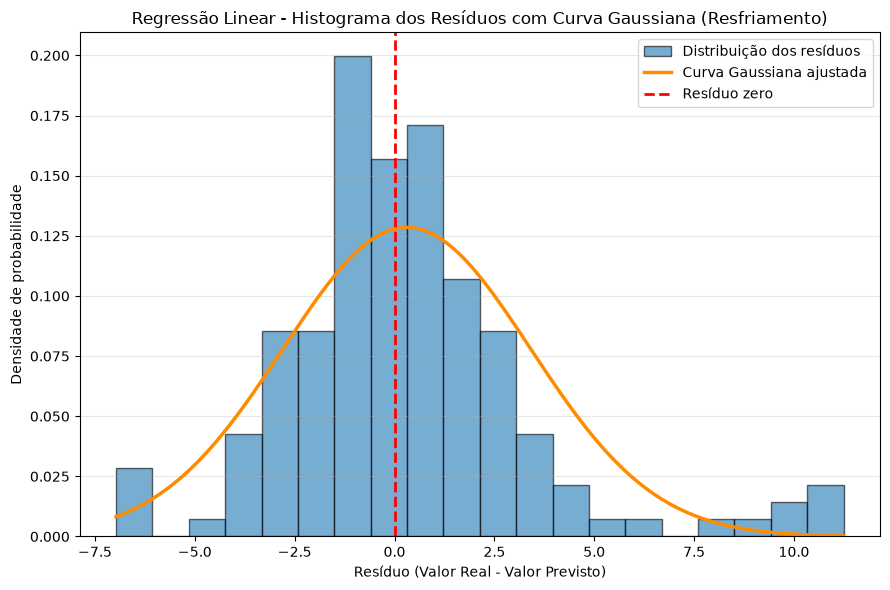

Média dos resíduos: 0.3080
Desvio-padrão dos resíduos: 3.1045


In [34]:

# Calcular a média e o desvio-padrão dos resíduos
media_residuos_res = np.mean(residuos_resfriamento)
desvio_residuos_res = np.std(residuos_resfriamento)

# Criar o histograma
plt.figure(figsize=(9, 6))

plt.hist(
    residuos_resfriamento,
    bins=20,
    density=True,
    edgecolor="black",
    alpha=0.6,
    label="Distribuição dos resíduos"
)

# Gerar os pontos da curva Gaussiana
x_gauss_res = np.linspace(
    residuos_resfriamento.min(),
    residuos_resfriamento.max(),
    300
)

# Calcular a densidade da distribuição normal
y_gauss_res = norm.pdf(
    x_gauss_res,
    loc=media_residuos_res,
    scale=desvio_residuos_res
)

# Desenhar a curva Gaussiana
plt.plot(
    x_gauss_res,
    y_gauss_res,
    color="darkorange",
    linewidth=2.5,
    label="Curva Gaussiana ajustada"
)

# Linha de referência para resíduo zero
plt.axvline(
    x=0,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Resíduo zero"
)

plt.xlabel("Resíduo (Valor Real - Valor Previsto)")
plt.ylabel("Densidade de probabilidade")
plt.title(
    "Regressão Linear - Histograma dos Resíduos "
    "com Curva Gaussiana (Resfriamento)"
)

plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Exibir estatísticas dos resíduos
print(f"Média dos resíduos: {media_residuos_res:.4f}")
print(f"Desvio-padrão dos resíduos: {desvio_residuos_res:.4f}")


**Análise do histograma dos resíduos com curva Gaussiana — Carga de Resfriamento**

O histograma apresenta uma concentração significativa dos resíduos em torno de zero, indicando que grande parte das previsões do modelo de Regressão Linear Múltipla apresenta erros relativamente pequenos.

Entretanto, a comparação com a curva Gaussiana ajustada evidencia diferenças no formato da distribuição. Observa-se um pico central mais elevado do que o esperado pela distribuição normal de referência, além de possíveis assimetrias e resíduos extremos.

Destaca-se a presença de uma cauda positiva que ultrapassa +10 unidades, indicando situações em que o modelo subestimou consideravelmente a Carga de Resfriamento.

Essas observações são coerentes com os padrões identificados nos gráficos anteriores, especialmente a maior dispersão dos resíduos em determinadas faixas de carga prevista e a subestimação de algumas cargas elevadas.

**Conclusão:** a distribuição dos resíduos apresenta concentração central próxima de zero, mas também desvios visuais em relação à normalidade, incluindo possíveis assimetrias e valores extremos. Esses resultados sugerem limitações do modelo linear para determinadas observações e reforçam a importância de avaliar outros algoritmos de aprendizado de máquina.

A análise realizada é exploratória e não constitui um teste estatístico formal de normalidade.

## 19 - Comparação dos Resultados da Regressão Linear Múltipla

### Comparação dos Modelos de Regressão Linear Múltipla

Após o treinamento e a avaliação dos modelos de Regressão Linear Múltipla para as Cargas de Aquecimento e Resfriamento, será realizada uma comparação dos resultados obtidos no conjunto de teste.

A tabela a seguir reúne as métricas MAE, RMSE e R², além da média e do desvio-padrão dos resíduos, permitindo avaliar o desempenho preditivo e as diferenças entre os dois modelos.

In [35]:

# Construção da tabela comparativa dos modelos de Regressão Linear
tabela_comparativa_linear = pd.DataFrame({
    "Modelo": [
        "Regressão Linear - Aquecimento",
        "Regressão Linear - Resfriamento"
    ],
    "MAE": [
        mae_aquecimento,
        mae_resfriamento
    ],
    "RMSE": [
        rmse_aquecimento,
        rmse_resfriamento
    ],
    "R²": [
        r2_aquecimento,
        r2_resfriamento
    ],
    "Média dos Resíduos": [
        media_residuos,
        media_residuos_res
    ],
    "Desvio-padrão dos Resíduos": [
        desvio_residuos,
        desvio_residuos_res
    ]
})

# Exibir a tabela com quatro casas decimais
tabela_comparativa_linear.round(4)


,Modelo,MAE,RMSE,R²,Média dos Resíduos,Desvio-padrão dos Resíduos
0,Regressão Linear - Aquecimento,2.0590,2.8723,0.9209,0.1906,2.8659
1,Regressão Linear - Resfriamento,2.1805,3.1198,0.8950,0.3080,3.1045


**Conclusão da comparação dos modelos lineares**

Os modelos de Regressão Linear Múltipla apresentaram desempenho preditivo satisfatório para ambas as cargas energéticas, com coeficientes de determinação superiores a 0,89 no conjunto de teste.

O modelo de Aquecimento apresentou menores valores de MAE e RMSE e maior R² em comparação com o modelo de Resfriamento, indicando melhor desempenho nas métricas avaliadas.

Entretanto, as análises dos resíduos realizadas anteriormente evidenciaram diferenças na dispersão dos erros e limitações na previsão de determinadas observações.

Os resultados constituem uma referência inicial para a avaliação de algoritmos não lineares, como o Random Forest Regressor, que será investigado posteriormente.

## 20 - Validação Cruzada dos Modelos de Regressão Linear Múltipla

### 20.1 - Definição da estratégia de validação cruzada

Nas seções anteriores, os modelos de Regressão Linear Múltipla foram treinados utilizando 80% das observações do conjunto de dados e avaliados nos 20% restantes.

Nesta etapa, será aplicada a técnica de **validação cruzada K-Fold**, com cinco divisões (*5-fold cross-validation*), para obter uma avaliação mais robusta do desempenho preditivo dos modelos.

O procedimento utilizará exclusivamente as 614 observações do conjunto de treinamento, preservando as 154 observações do conjunto de teste.

Em cada uma das cinco rodadas, o modelo será treinado com aproximadamente quatro quintos das observações e validado com o quinto restante.

Serão calculadas as métricas MAE, RMSE e R² em cada rodada. Posteriormente, serão obtidas as médias e os desvios-padrão dessas métricas.

A validação cruzada será aplicada separadamente às Cargas de Aquecimento e Resfriamento, utilizando as mesmas divisões dos dados.

O objetivo é estabelecer uma referência metodologicamente consistente para a comparação posterior com outros algoritmos de aprendizado de máquina.

In [36]:

# Importar a classe para validação cruzada K-Fold
from sklearn.model_selection import KFold

# Definir a estratégia de validação cruzada
kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Validação cruzada K-Fold configurada com sucesso!")
print(f"Número de divisões: {kfold.n_splits}")


Validação cruzada K-Fold configurada com sucesso!
Número de divisões: 5


### 20.2 - Validação Cruzada da Regressão Linear — Carga de Aquecimento

Nesta etapa, será aplicada a validação cruzada K-Fold, com cinco divisões, ao modelo de Regressão Linear Múltipla utilizado para prever a Carga de Aquecimento.

Serão utilizadas exclusivamente as 614 observações do conjunto de treinamento, mantendo as 154 observações do conjunto de teste separadas.

Em cada rodada, o modelo será treinado com aproximadamente 80% das observações disponíveis para validação cruzada e avaliado com os 20% restantes.

O pré-processamento das variáveis será executado dentro do Pipeline, garantindo que os parâmetros de padronização e codificação sejam ajustados somente com os dados de treinamento de cada rodada.

Serão calculadas as métricas MAE, RMSE e R² para cada uma das cinco rodadas.

Os resultados permitirão avaliar tanto o desempenho médio do modelo quanto sua variação entre diferentes divisões dos dados.

In [37]:

# Importar a função de validação cruzada
from sklearn.model_selection import cross_validate

# Definir as métricas de avaliação
metricas_cv = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

# Executar a validação cruzada - Carga de Aquecimento
resultados_cv_aquecimento = cross_validate(
    estimator=modelo_linear_aquecimento,
    X=X_treino,
    y=y_aq_treino,
    cv=kfold,
    scoring=metricas_cv
)

# Organizar os resultados das cinco rodadas
tabela_cv_aquecimento = pd.DataFrame({
    "Rodada": range(1, 6),
    "MAE": -resultados_cv_aquecimento["test_MAE"],
    "RMSE": -resultados_cv_aquecimento["test_RMSE"],
    "R²": resultados_cv_aquecimento["test_R2"]
})

# Exibir os resultados
tabela_cv_aquecimento.round(4)


,Rodada,MAE,RMSE,R²
0,1,1.9130,2.7479,0.9306
1,2,2.1109,2.9990,0.9118
2,3,2.0717,2.8587,0.9173
3,4,1.9410,2.6406,0.9311
4,5,2.1202,2.8960,0.9075


### 20.3 - Cálculo das médias e dos desvios-padrão das métricas — Carga de Aquecimento

Após a execução da validação cruzada K-Fold com cinco divisões, foram obtidos cinco valores para cada uma das métricas MAE, RMSE e R².

Nesta etapa, serão calculadas a média e o desvio-padrão de cada métrica, permitindo avaliar o desempenho médio do modelo e a variabilidade dos resultados entre as rodadas.

A média representa o desempenho médio obtido nas cinco avaliações, enquanto o desvio-padrão indica quanto os resultados variaram em torno dessa média.

Valores relativamente pequenos de desvio-padrão sugerem que o desempenho do modelo foi semelhante nas diferentes divisões dos dados.

Esses indicadores serão utilizados posteriormente como referência para a comparação com outros algoritmos de aprendizado de máquina.

In [38]:

# Calcular as médias das métricas da validação cruzada
media_mae_cv_aq = tabela_cv_aquecimento["MAE"].mean()
media_rmse_cv_aq = tabela_cv_aquecimento["RMSE"].mean()
media_r2_cv_aq = tabela_cv_aquecimento["R²"].mean()

# Calcular os desvios-padrão das métricas
desvio_mae_cv_aq = tabela_cv_aquecimento["MAE"].std(ddof=0)
desvio_rmse_cv_aq = tabela_cv_aquecimento["RMSE"].std(ddof=0)
desvio_r2_cv_aq = tabela_cv_aquecimento["R²"].std(ddof=0)

# Exibir os resultados
print("Validação Cruzada - Regressão Linear - Aquecimento")
print("-" * 50)

print(f"MAE médio:  {media_mae_cv_aq:.4f} ± {desvio_mae_cv_aq:.4f}")
print(f"RMSE médio: {media_rmse_cv_aq:.4f} ± {desvio_rmse_cv_aq:.4f}")
print(f"R² médio:   {media_r2_cv_aq:.4f} ± {desvio_r2_cv_aq:.4f}")


Validação Cruzada - Regressão Linear - Aquecimento
--------------------------------------------------
MAE médio:  2.0313 ± 0.0872
RMSE médio: 2.8285 ± 0.1235
R² médio:   0.9196 ± 0.0096


**Análise da validação cruzada — Carga de Aquecimento**

A validação cruzada K-Fold, com cinco divisões, apresentou MAE médio de 2,0313 ± 0,0872, RMSE médio de 2,8285 ± 0,1235 e R² médio de 0,9196 ± 0,0096.

Os resultados indicam bom desempenho preditivo e pequena variabilidade das métricas entre as cinco rodadas. Além disso, os valores médios ficaram próximos daqueles obtidos anteriormente no conjunto de teste, sugerindo consistência entre as avaliações.

Esses resultados serão utilizados como referência para a comparação com o algoritmo Random Forest Regressor.

### 20.4 - Validação Cruzada da Regressão Linear — Carga de Resfriamento

Nesta etapa, será aplicada a validação cruzada K-Fold, com cinco divisões, ao modelo de Regressão Linear Múltipla utilizado para prever a Carga de Resfriamento.

Será utilizada a mesma estratégia de validação adotada para a Carga de Aquecimento, mantendo as mesmas divisões das 614 observações de treinamento.

Em cada rodada, o modelo será ajustado utilizando aproximadamente 80% dessas observações e avaliado com os 20% restantes.

Serão calculadas as métricas MAE, RMSE e R², permitindo avaliar o desempenho do modelo nas cinco rodadas.

A utilização da mesma estratégia facilitará a comparação dos resultados das duas variáveis-alvo e fornecerá uma referência para a avaliação posterior de outros algoritmos.

In [39]:

# Executar a validação cruzada - Carga de Resfriamento
resultados_cv_resfriamento = cross_validate(
    estimator=modelo_linear_resfriamento,
    X=X_treino,
    y=y_res_treino,
    cv=kfold,
    scoring=metricas_cv
)

# Organizar os resultados das cinco rodadas
tabela_cv_resfriamento = pd.DataFrame({
    "Rodada": range(1, 6),
    "MAE": -resultados_cv_resfriamento["test_MAE"],
    "RMSE": -resultados_cv_resfriamento["test_RMSE"],
    "R²": resultados_cv_resfriamento["test_R2"]
})

# Exibir os resultados
tabela_cv_resfriamento.round(4)


,Rodada,MAE,RMSE,R²
0,1,2.1640,3.0984,0.8967
1,2,2.1977,3.2026,0.8851
2,3,2.5298,3.5344,0.8624
3,4,2.4419,3.2503,0.8875
4,5,2.2234,3.0756,0.8794


### 20.5 - Cálculo das médias e dos desvios-padrão das métricas — Carga de Resfriamento

Após a execução da validação cruzada K-Fold com cinco divisões, foram obtidos cinco valores para cada uma das métricas MAE, RMSE e R² do modelo de Regressão Linear Múltipla para a Carga de Resfriamento.

Nesta etapa, serão calculadas as médias e os desvios-padrão dessas métricas.

As médias permitirão avaliar o desempenho preditivo médio do modelo, enquanto os desvios-padrão fornecerão informações sobre a variabilidade dos resultados entre as cinco rodadas.

Esses indicadores serão posteriormente comparados com os resultados da validação cruzada para a Carga de Aquecimento e utilizados como referência para a avaliação de outros algoritmos de aprendizado de máquina.

In [40]:

# Calcular as médias das métricas - Resfriamento
media_mae_cv_res = tabela_cv_resfriamento["MAE"].mean()
media_rmse_cv_res = tabela_cv_resfriamento["RMSE"].mean()
media_r2_cv_res = tabela_cv_resfriamento["R²"].mean()

# Calcular os desvios-padrão das métricas
desvio_mae_cv_res = tabela_cv_resfriamento["MAE"].std(ddof=0)
desvio_rmse_cv_res = tabela_cv_resfriamento["RMSE"].std(ddof=0)
desvio_r2_cv_res = tabela_cv_resfriamento["R²"].std(ddof=0)

# Exibir os resultados
print("Validação Cruzada - Regressão Linear - Resfriamento")
print("-" * 50)

print(f"MAE médio:  {media_mae_cv_res:.4f} ± {desvio_mae_cv_res:.4f}")
print(f"RMSE médio: {media_rmse_cv_res:.4f} ± {desvio_rmse_cv_res:.4f}")
print(f"R² médio:   {media_r2_cv_res:.4f} ± {desvio_r2_cv_res:.4f}")


Validação Cruzada - Regressão Linear - Resfriamento
--------------------------------------------------
MAE médio:  2.3114 ± 0.1464
RMSE médio: 3.2322 ± 0.1643
R² médio:   0.8822 ± 0.0114


**Análise da validação cruzada — Carga de Resfriamento**

A validação cruzada K-Fold, com cinco divisões, apresentou MAE médio de 2,3114 ± 0,1464, RMSE médio de 3,2322 ± 0,1643 e R² médio de 0,8822 ± 0,0114.

O modelo apresentou desempenho preditivo favorável, porém inferior ao observado para a Carga de Aquecimento. Os maiores valores de MAE e RMSE, associados ao menor R², indicam maior dificuldade na previsão da Carga de Resfriamento.

Os desvios-padrão também foram ligeiramente superiores aos obtidos para Aquecimento, indicando maior variabilidade das métricas entre as cinco rodadas.

### 20.6 - Comparação dos Resultados da Validação Cruzada

Nesta etapa, serão comparadas as médias e os desvios-padrão das métricas MAE, RMSE e R² obtidas na validação cruzada dos modelos de Regressão Linear Múltipla para as Cargas de Aquecimento e Resfriamento.

A comparação permitirá identificar diferenças no desempenho preditivo e na variabilidade das métricas entre os dois modelos.

Os resultados constituirão uma referência para a avaliação posterior de outros algoritmos de aprendizado de máquina, utilizando a mesma estratégia de validação cruzada.

In [41]:

# Criar tabela comparativa da validação cruzada
tabela_comparativa_cv = pd.DataFrame({
    "Modelo": [
        "Regressão Linear - Aquecimento",
        "Regressão Linear - Resfriamento"
    ],
    "MAE Médio": [
        media_mae_cv_aq,
        media_mae_cv_res
    ],
    "Desvio MAE": [
        desvio_mae_cv_aq,
        desvio_mae_cv_res
    ],
    "RMSE Médio": [
        media_rmse_cv_aq,
        media_rmse_cv_res
    ],
    "Desvio RMSE": [
        desvio_rmse_cv_aq,
        desvio_rmse_cv_res
    ],
    "R² Médio": [
        media_r2_cv_aq,
        media_r2_cv_res
    ],
    "Desvio R²": [
        desvio_r2_cv_aq,
        desvio_r2_cv_res
    ]
})

# Exibir a tabela
tabela_comparativa_cv.round(4)


,Modelo,MAE Médio,Desvio MAE,RMSE Médio,Desvio RMSE,R² Médio,Desvio R²
0,Regressão Linear - Aquecimento,2.0313,0.0872,2.8285,0.1235,0.9196,0.0096
1,Regressão Linear - Resfriamento,2.3114,0.1464,3.2322,0.1643,0.8822,0.0114


**Conclusão da Validação Cruzada dos Modelos de Regressão Linear Múltipla**

A validação cruzada K-Fold, com cinco divisões, demonstrou que os modelos de Regressão Linear Múltipla apresentaram desempenho preditivo favorável e relativa estabilidade entre as diferentes divisões do conjunto de treinamento.

O modelo de Aquecimento apresentou melhores resultados nas três métricas avaliadas, com menores valores médios de MAE e RMSE e maior R² médio, quando comparado ao modelo de Resfriamento.

Os desvios-padrão relativamente pequenos sugerem que os resultados não dependeram excessivamente de uma única divisão dos dados.

Dessa forma, a validação cruzada estabelece uma referência de desempenho para a comparação posterior com o algoritmo Random Forest Regressor, utilizando a mesma estratégia de avaliação.

## 21 - Modelagem Preditiva com Random Forest Regressor

### 21.1 - Introdução ao algoritmo Random Forest Regressor

Nesta etapa, será utilizado o algoritmo **Random Forest Regressor**, baseado na combinação de múltiplas árvores de decisão, para prever as Cargas de Aquecimento e Resfriamento a partir das características arquitetônicas das edificações.

Diferentemente da Regressão Linear Múltipla, o Random Forest permite representar relações não lineares e interações entre as variáveis explicativas sem exigir a especificação prévia dessas relações.

O algoritmo constrói diversas árvores de decisão e combina suas previsões por meio da média dos resultados individuais.

O objetivo desta etapa é investigar se a utilização de um modelo não linear permite melhorar o desempenho preditivo em comparação com a Regressão Linear Múltipla.

Para garantir a consistência metodológica, serão mantidos os mesmos conjuntos de treinamento e teste, bem como a estratégia de validação cruzada K-Fold com cinco divisões.

Os modelos serão avaliados utilizando as métricas MAE, RMSE e R².

In [42]:

# Importar o algoritmo Random Forest Regressor
from sklearn.ensemble import RandomForestRegressor

# Criar o modelo Random Forest para a Carga de Aquecimento
modelo_rf_aquecimento = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Exibir a configuração do modelo
modelo_rf_aquecimento


,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"m

**Random Forest Regressor para a Carga de aquecimento foi configurado corretamente.**

### 21.2 - Construção do Pipeline — Random Forest para Carga de Aquecimento

Nesta etapa, será construído um Pipeline contendo o pré-processamento das variáveis explicativas e o algoritmo Random Forest Regressor.

Será mantida a codificação One-Hot Encoding para as variáveis categóricas, garantindo sua representação numérica.

Embora o Random Forest não necessite da padronização das variáveis numéricas, será inicialmente utilizado o mesmo pré-processamento adotado na Regressão Linear Múltipla, permitindo manter uma estrutura consistente entre os modelos.

O Pipeline será posteriormente treinado utilizando exclusivamente as observações do conjunto de treinamento.

In [43]:

# Construir o Pipeline para o Random Forest - Aquecimento
pipeline_rf_aquecimento = Pipeline(
    steps=[
        ("preprocessamento", preprocessador),
        ("random_forest", modelo_rf_aquecimento)
    ]
)

# Exibir o Pipeline
pipeline_rf_aquecimento


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessamento', ...), ('random_forest', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numericas', ...), ('categoricas', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold

Pipeline Random Forest para a Carga de Aquecimento foi construído corretamente.

### 21.3 - Treinamento do Modelo Random Forest — Carga de Aquecimento

Nesta etapa, será realizado o treinamento do modelo Random Forest Regressor para prever a Carga de Aquecimento das edificações.

Serão utilizadas exclusivamente as 614 observações do conjunto de treinamento, representadas pelas variáveis `X_treino` e `y_aq_treino`.

O treinamento será executado por meio do Pipeline, que realizará automaticamente o pré-processamento das variáveis explicativas e o ajuste do algoritmo Random Forest.

As 154 observações do conjunto de teste permanecerão reservadas para a avaliação posterior do desempenho preditivo do modelo.

In [44]:

# Treinar o modelo Random Forest - Carga de Aquecimento
pipeline_rf_aquecimento.fit(X_treino, y_aq_treino)

# Confirmar o treinamento
print("Treinamento do Random Forest - Aquecimento concluído!")
print(f"Observações utilizadas: {X_treino.shape[0]}")
print(f"Número de árvores: {pipeline_rf_aquecimento.named_steps['random_forest'].n_estimators}")


Treinamento do Random Forest - Aquecimento concluído!
Observações utilizadas: 614
Número de árvores: 100


**O treinamento do Random Forest Regressor para a Carga de Aquecimento foi concluído corretamente.**

O modelo utilizou as 614 observações de treinamento e construiu suas 100 árvores de decisão, conforme a configuração estabelecida.

**Os resultados confirmam que:**

- Foram utilizadas 614 observações para o treinamento.
- O algoritmo construiu 100 árvores de decisão.
- O Pipeline executou o pré-processamento e o treinamento sem apresentar erros.
- As 154 observações de teste continuam disponíveis para avaliar a capacidade preditiva do modelo.

### 21.4 - Previsão da Carga de Aquecimento com Random Forest

Após o treinamento do modelo Random Forest Regressor, serão realizadas previsões da Carga de Aquecimento utilizando as 154 observações do conjunto de teste.

Essas observações não participaram do treinamento, permitindo avaliar a capacidade de generalização do modelo para dados não utilizados durante o ajuste.

Os valores previstos serão comparados com os valores reais da Carga de Aquecimento, possibilitando a identificação dos erros de previsão.

Posteriormente, serão calculadas as métricas MAE, RMSE e R², permitindo comparar o desempenho do Random Forest com o modelo de Regressão Linear Múltipla.

In [45]:

# Realizar previsões da Carga de Aquecimento
y_aq_previsto_rf = pipeline_rf_aquecimento.predict(X_teste)

# Construir tabela para comparar valores reais e previstos
comparacao_aquecimento_rf = pd.DataFrame({
    "Valor Real": y_aq_teste,
    "Valor Previsto": y_aq_previsto_rf
})

# Calcular o erro de cada previsão
comparacao_aquecimento_rf["Erro"] = (
    comparacao_aquecimento_rf["Valor Real"]
    - comparacao_aquecimento_rf["Valor Previsto"]
)

# Classificar as previsões
erro = comparacao_aquecimento_rf["Erro"]

condicoes = [
    (erro > -1) & (erro < 0),
    erro <= -1,
    (erro > 0) & (erro < 1),
    erro >= 1
]

classificacoes = [
    "Superestimativa pequena",
    "Superestimativa",
    "Subestimativa pequena",
    "Subestimativa"
]

comparacao_aquecimento_rf["Avaliação da Previsão"] = np.select(
    condicoes,
    classificacoes,
    default="Exata"
)

# Exibir as primeiras 10 previsões
comparacao_aquecimento_rf.head(10).round(4)


,Valor Real,Valor Previsto,Erro,Avaliação da Previsão
668,16.47,15.5828,0.8872,Subestimativa pequena
324,13.17,13.1516,0.0184,Subestimativa pequena
624,32.82,32.7531,0.0669,Subestimativa pequena
690,41.32,42.2842,-0.9642,Superestimativa pequena
473,16.69,16.7852,-0.0952,Superestimativa pequena
204,23.80,23.4526,0.3474,Subestimativa pequena
97,24.31,24.3168,-0.0068,Superestimativa pequena
336,28.67,28.6713,-0.0013,Superestimativa pequena
568,19.52,19.3620,0.1580,Subestimativa pequena
148,28.07,29.0981,-1.0281,Superestimativa


**Análise das previsões da Carga de Aquecimento com Random Forest Regressor**

A tabela apresenta as dez primeiras observações do conjunto de teste, comparando os valores reais com os valores previstos pelo modelo Random Forest Regressor.

Os erros foram calculados pela diferença entre os valores reais e previstos. Valores negativos indicam superestimativas, enquanto valores positivos indicam subestimativas. Erros com magnitude inferior a uma unidade foram classificados como pequenos.

Observa-se que várias previsões apresentam diferenças reduzidas entre os valores reais e estimados, embora existam observações com erros de maior magnitude.

Entretanto, a avaliação dessas dez observações não é suficiente para determinar o desempenho global do modelo. Na próxima subseção, serão calculadas as métricas MAE, RMSE e R² considerando todas as 154 observações do conjunto de teste.

### 21.5 - Avaliação do Desempenho do Random Forest — Carga de Aquecimento

Após a realização das previsões da Carga de Aquecimento, será avaliado o desempenho preditivo do modelo Random Forest Regressor utilizando as 154 observações do conjunto de teste.

Serão calculadas as seguintes métricas:

- **MAE (Mean Absolute Error):** representa a média dos valores absolutos dos erros de previsão.
- **RMSE (Root Mean Squared Error):** representa a raiz quadrada da média dos erros elevados ao quadrado, atribuindo maior penalização aos erros de maior magnitude.
- **R² (Coeficiente de Determinação):** indica a proporção da variabilidade da variável-alvo explicada pelo modelo, em comparação com uma previsão baseada na média dos valores observados.

Os resultados serão posteriormente comparados com aqueles obtidos pelo modelo de Regressão Linear Múltipla, permitindo avaliar se o Random Forest proporcionou melhorias na capacidade preditiva da Carga de Aquecimento.

In [46]:

# Calcular as métricas do Random Forest - Aquecimento
mae_rf_aquecimento = mean_absolute_error(
    y_aq_teste, y_aq_previsto_rf
)

rmse_rf_aquecimento = np.sqrt(
    mean_squared_error(y_aq_teste, y_aq_previsto_rf)
)

r2_rf_aquecimento = r2_score(
    y_aq_teste, y_aq_previsto_rf
)

# Exibir os resultados
print("Random Forest - Carga de Aquecimento")
print("-" * 45)

print(f"MAE:  {mae_rf_aquecimento:.4f}")
print(f"RMSE: {rmse_rf_aquecimento:.4f}")
print(f"R²:   {r2_rf_aquecimento:.4f}")


Random Forest - Carga de Aquecimento
---------------------------------------------
MAE:  0.3695
RMSE: 0.5332
R²:   0.9973


**O Random Forest apresentou desempenho expressivamente superior ao da Regressão Linear Múltipla na previsão da Carga de Aquecimento.**

| Métrica | Regressão Linear | Random Forest | Melhor modelo |
|:---|---:|---:|:---|
| MAE | 2,0590 | 0,3695 | Random Forest |
| RMSE | 2,8723 | 0,5332 | Random Forest |
| R² | 0,9209 | 0,9973 | Random Forest |

Os resultados mostram que o Random Forest apresentou menores erros de previsão e maior capacidade de explicar a variabilidade da Carga de Aquecimento no conjunto de teste.

Esse desempenho é compatível com a capacidade do algoritmo de representar relações não lineares e interações entre características arquitetônicas, embora os resultados não permitam identificar quais relações foram responsáveis pela melhoria.

Entretanto, o desempenho em uma única divisão dos dados não garante, isoladamente, estabilidade preditiva. Por esse motivo, os resultados também serão avaliados por validação cruzada.

### 21.6 - Validação Cruzada do Random Forest — Carga de Aquecimento

Com o objetivo de avaliar a estabilidade e a capacidade de generalização do modelo Random Forest Regressor, será aplicada a técnica de validação cruzada K-Fold, utilizando cinco divisões dos dados de treinamento.

Em cada rodada, o modelo será treinado com quatro partes dos dados e validado com a parte restante. Esse procedimento será repetido cinco vezes, alternando o subconjunto utilizado para validação.

Serão calculadas as métricas MAE, RMSE e R² para cada rodada, permitindo analisar a consistência dos resultados.

A validação cruzada será realizada exclusivamente sobre o conjunto de treinamento, preservando o conjunto de teste para a avaliação independente do modelo.

In [47]:

# Validação cruzada do Random Forest - Aquecimento
resultados_cv_rf_aquecimento = cross_validate(
    estimator=pipeline_rf_aquecimento,
    X=X_treino,
    y=y_aq_treino,
    cv=kfold,
    scoring=metricas_cv,
    n_jobs=-1
)

# Organizar os resultados das cinco rodadas
tabela_cv_rf_aquecimento = pd.DataFrame({
    "Rodada": range(1, 6),
    "MAE": -resultados_cv_rf_aquecimento["test_MAE"],
    "RMSE": -resultados_cv_rf_aquecimento["test_RMSE"],
    "R²": resultados_cv_rf_aquecimento["test_R2"]
})

# Exibir os resultados
tabela_cv_rf_aquecimento.round(4)


,Rodada,MAE,RMSE,R²
0,1,0.3465,0.5625,0.9971
1,2,0.3309,0.4850,0.9977
2,3,0.3488,0.5027,0.9974
3,4,0.3824,0.5569,0.9969
4,5,0.3511,0.5911,0.9961


### 21.7 - Estatísticas da Validação Cruzada — Random Forest para Aquecimento

Para sintetizar os resultados da validação cruzada do modelo Random Forest Regressor, serão calculadas as médias e os desvios-padrão das métricas MAE, RMSE e R², considerando as cinco rodadas realizadas.

As médias permitem avaliar o desempenho preditivo geral do modelo, enquanto os desvios-padrão permitem analisar a variabilidade dos resultados entre as diferentes divisões dos dados.

Valores reduzidos de MAE e RMSE, associados a valores elevados de R² e pequenos desvios-padrão, indicam desempenho preditivo favorável e consistência entre as rodadas de validação.

Essas estatísticas serão posteriormente comparadas com os resultados da validação cruzada do modelo de Regressão Linear Múltipla.

In [48]:

# Médias da validação cruzada - Random Forest Aquecimento
media_mae_cv_rf_aq = tabela_cv_rf_aquecimento["MAE"].mean()
media_rmse_cv_rf_aq = tabela_cv_rf_aquecimento["RMSE"].mean()
media_r2_cv_rf_aq = tabela_cv_rf_aquecimento["R²"].mean()

# Desvios-padrão da validação cruzada
desvio_mae_cv_rf_aq = tabela_cv_rf_aquecimento["MAE"].std(ddof=0)
desvio_rmse_cv_rf_aq = tabela_cv_rf_aquecimento["RMSE"].std(ddof=0)
desvio_r2_cv_rf_aq = tabela_cv_rf_aquecimento["R²"].std(ddof=0)

# Exibir os resultados
print("Validação Cruzada - Random Forest - Aquecimento")
print("-" * 50)

print(f"MAE médio:  {media_mae_cv_rf_aq:.4f} ± {desvio_mae_cv_rf_aq:.4f}")
print(f"RMSE médio: {media_rmse_cv_rf_aq:.4f} ± {desvio_rmse_cv_rf_aq:.4f}")
print(f"R² médio:   {media_r2_cv_rf_aq:.4f} ± {desvio_r2_cv_rf_aq:.4f}")


Validação Cruzada - Random Forest - Aquecimento
--------------------------------------------------
MAE médio:  0.3519 ± 0.0168
RMSE médio: 0.5396 ± 0.0395
R² médio:   0.9971 ± 0.0005


**Interpretação dos resultados**

O MAE médio de 0,3519 indica que o erro absoluto médio nas rodadas de validação foi de aproximadamente 0,35 unidade de Carga de Aquecimento.

O RMSE médio de 0,5396 indica que os erros de maior magnitude também permaneceram relativamente baixos.

O R² médio de 0,9971 significa que, nas cinco rodadas, o modelo apresentou uma capacidade explicativa muito elevada, correspondente a aproximadamente 99,71% da variabilidade observada, em média, nos subconjuntos de validação.

O desvio-padrão do R², de apenas 0,0005, evidencia a consistência desse desempenho.

### 21.8 - Comparação da Validação Cruzada: Regressão Linear Múltipla × Random Forest — Carga de Aquecimento

Nesta etapa, serão comparados os resultados da validação cruzada dos modelos de Regressão Linear Múltipla e Random Forest Regressor, ambos utilizados para prever a Carga de Aquecimento das edificações.

A comparação será realizada com base nas médias e nos desvios-padrão das métricas MAE, RMSE e R², obtidos por meio de validação cruzada com cinco divisões dos dados de treinamento.

O objetivo é identificar qual algoritmo apresenta melhor desempenho preditivo e maior consistência entre as rodadas, considerando as mesmas observações e a mesma metodologia de avaliação.

In [49]:

# Comparação da validação cruzada - Carga de Aquecimento

tabela_comparativa_cv_aquecimento = pd.DataFrame({
    "Modelo": [
        "Regressão Linear Múltipla",
        "Random Forest"
    ],
    "MAE Médio": [
        media_mae_cv_aq,
        media_mae_cv_rf_aq
    ],
    "Desvio MAE": [
        desvio_mae_cv_aq,
        desvio_mae_cv_rf_aq
    ],
    "RMSE Médio": [
        media_rmse_cv_aq,
        media_rmse_cv_rf_aq
    ],
    "Desvio RMSE": [
        desvio_rmse_cv_aq,
        desvio_rmse_cv_rf_aq
    ],
    "R² Médio": [
        media_r2_cv_aq,
        media_r2_cv_rf_aq
    ],
    "Desvio R²": [
        desvio_r2_cv_aq,
        desvio_r2_cv_rf_aq
    ]
})

# Exibir a tabela comparativa
tabela_comparativa_cv_aquecimento.round(4)


,Modelo,MAE Médio,Desvio MAE,RMSE Médio,Desvio RMSE,R² Médio,Desvio R²
0,Regressão Linear Múltipla,2.0313,0.0872,2.8285,0.1235,0.9196,0.0096
1,Random Forest,0.3519,0.0168,0.5396,0.0395,0.9971,0.0005


**Conclusão da comparação — Validação Cruzada para Aquecimento**

O Random Forest apresentou desempenho superior ao da Regressão Linear Múltipla na validação cruzada com cinco divisões do conjunto de treinamento.

| Métrica | Regressão Linear | Random Forest | Melhor modelo |
|:---|---:|---:|:---|
| MAE médio | 2,0313 | 0,3519 | Random Forest |
| Desvio-padrão do MAE | 0,0872 | 0,0168 | Random Forest |
| RMSE médio | 2,8285 | 0,5396 | Random Forest |
| Desvio-padrão do RMSE | 0,1235 | 0,0395 | Random Forest |
| R² médio | 0,9196 | 0,9971 | Random Forest |
| Desvio-padrão do R² | 0,0096 | 0,0005 | Random Forest |

O Random Forest apresentou menores valores médios de MAE e RMSE e maior R² médio. Além disso, os desvios-padrão das três métricas foram menores, indicando menor variabilidade dos resultados entre as cinco divisões.

Esses resultados reforçam a conclusão de que o Random Forest apresentou melhor desempenho preditivo e maior consistência nas condições avaliadas.

## 22 - Random Forest Regressor — Carga de Resfriamento

Nesta seção, será aplicado o algoritmo Random Forest Regressor para prever a Carga de Resfriamento das edificações a partir das suas características arquitetônicas.

Será utilizada a mesma configuração adotada anteriormente para a previsão da Carga de Aquecimento, permitindo avaliar o desempenho do algoritmo para as duas variáveis-alvo.

### 22.1 - Construção do Modelo Random Forest — Carga de Resfriamento

O modelo será configurado com 100 árvores de decisão (`n_estimators=100`), utilizando `random_state=42` para garantir a reprodutibilidade dos resultados e `n_jobs=-1` para permitir o processamento paralelo.

Nesta etapa, será criado apenas o estimador Random Forest. O treinamento será realizado posteriormente, após sua integração ao Pipeline de pré-processamento.

In [50]:

# Criar o modelo Random Forest para Carga de Resfriamento
modelo_rf_resfriamento = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Exibir a configuração do modelo
modelo_rf_resfriamento


,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"m

**Random Forest Regressor para a Carga de Resfriamento foi configurado corretamente.**

### 22.2 - Construção do Pipeline Random Forest — Carga de Resfriamento

Nesta etapa, será construído um Pipeline que integra o pré-processamento das variáveis de entrada ao algoritmo Random Forest Regressor.

Será reutilizada a estrutura de pré-processamento definida anteriormente, composta por:

- **StandardScaler:** responsável pela padronização das variáveis numéricas.
- **OneHotEncoder:** responsável pela codificação das variáveis categóricas.

Embora o Random Forest não exija a padronização das variáveis numéricas, será mantida a mesma estrutura utilizada nos modelos anteriores, garantindo consistência metodológica.

A utilização do Pipeline permite executar automaticamente as transformações necessárias durante o treinamento e a previsão, além de evitar o vazamento de informações entre os subconjuntos de treinamento e validação.

In [51]:

# Construir o Pipeline Random Forest - Resfriamento
pipeline_rf_resfriamento = Pipeline(
    steps=[
        ("preprocessamento", preprocessador),
        ("random_forest", modelo_rf_resfriamento)
    ]
)

# Exibir a estrutura do Pipeline
pipeline_rf_resfriamento


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessamento', ...), ('random_forest', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numericas', ...), ('categoricas', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold

**Pipeline Random Forest para a Carga de Resfriamento foi construído corretamente.**

### 22.3 - Treinamento do Modelo Random Forest — Carga de Resfriamento

Nesta etapa, será realizado o treinamento do modelo Random Forest Regressor para a previsão da Carga de Resfriamento das edificações.

Serão utilizadas as 614 observações do conjunto de treinamento, correspondentes a 80% da base de dados original.

O treinamento será realizado por meio do Pipeline, que executará automaticamente o pré-processamento das variáveis de entrada e o ajuste do algoritmo Random Forest.

A variável-alvo será a Carga de Resfriamento (`y_res_treino`), enquanto as características arquitetônicas das edificações serão representadas por `X_treino`.

As 154 observações do conjunto de teste permanecerão separadas para a posterior avaliação do desempenho preditivo do modelo.

In [52]:

# Treinar o Random Forest para Carga de Resfriamento
pipeline_rf_resfriamento.fit(X_treino, y_res_treino)

# Confirmar o treinamento
print("Treinamento do Random Forest - Resfriamento concluído!")

print(f"Observações utilizadas: {X_treino.shape[0]}")

print(
    f"Número de árvores: "
    f"{pipeline_rf_resfriamento.named_steps['random_forest'].n_estimators}"
)


Treinamento do Random Forest - Resfriamento concluído!
Observações utilizadas: 614
Número de árvores: 100


**O treinamento do Random Forest Regressor para a Carga de Resfriamento foi concluído corretamente.**

O modelo utilizou as 614 observações de treinamento e construiu suas 100 árvores de decisão, conforme a configuração estabelecida.

### 22.4 - Previsão da Carga de Resfriamento com Random Forest

Após o treinamento do modelo Random Forest Regressor, serão realizadas previsões da Carga de Resfriamento utilizando as 154 observações do conjunto de teste.

O objetivo é avaliar a capacidade do modelo de estimar a demanda energética de resfriamento de edificações cujas observações não foram utilizadas durante o treinamento.

Os valores previstos serão comparados com os valores reais, permitindo identificar os erros individuais de previsão.

Para cada observação, o erro será calculado pela diferença entre o valor real e o valor previsto:

\[
Erro = Valor\ Real - Valor\ Previsto
\]

Valores positivos indicam que o modelo subestimou a Carga de Resfriamento, enquanto valores negativos indicam que o modelo a superestimou.

In [53]:

# Realizar previsões da Carga de Resfriamento
y_res_previsto_rf = pipeline_rf_resfriamento.predict(X_teste)

# Construir tabela para comparar valores reais e previstos
comparacao_resfriamento_rf = pd.DataFrame({
    "Valor Real": y_res_teste,
    "Valor Previsto": y_res_previsto_rf
})

# Calcular o erro de cada previsão
comparacao_resfriamento_rf["Erro"] = (
    comparacao_resfriamento_rf["Valor Real"]
    - comparacao_resfriamento_rf["Valor Previsto"]
)

# Classificar as previsões
erro = comparacao_resfriamento_rf["Erro"]

condicoes = [
    (erro > -1) & (erro < 0),
    erro <= -1,
    (erro > 0) & (erro < 1),
    erro >= 1
]

classificacoes = [
    "Superestimativa pequena",
    "Superestimativa",
    "Subestimativa pequena",
    "Subestimativa"
]

comparacao_resfriamento_rf["Avaliação da Previsão"] = np.select(
    condicoes,
    classificacoes,
    default="Exata"
)

# Exibir as primeiras 10 previsões
comparacao_resfriamento_rf.head(10).round(4)


,Valor Real,Valor Previsto,Erro,Avaliação da Previsão
668,16.90,16.6500,0.2500,Subestimativa pequena
324,16.39,15.9903,0.3997,Subestimativa pequena
624,32.78,33.5717,-0.7917,Superestimativa pequena
690,46.23,43.3602,2.8698,Subestimativa
473,19.76,20.0220,-0.2620,Superestimativa pequena
204,24.61,27.4730,-2.8630,Superestimativa
97,25.63,25.9884,-0.3584,Superestimativa pequena
336,29.62,29.6752,-0.0552,Superestimativa pequena
568,22.72,22.4467,0.2733,Subestimativa pequena
148,34.14,31.8298,2.3102,Subestimativa


**Análise das previsões da Carga de Resfriamento com Random Forest Regressor**

A tabela apresenta as dez primeiras observações do conjunto de teste, comparando os valores reais com os valores previstos pelo modelo Random Forest Regressor.

Os erros foram calculados pela diferença entre os valores reais e previstos. Valores negativos indicam superestimativas, enquanto valores positivos indicam subestimativas. Erros com magnitude inferior a uma unidade foram classificados como pequenos.

A comparação permite identificar previsões com diferenças reduzidas e outras com erros mais expressivos, evidenciando que a precisão do modelo pode variar entre as observações.

Entretanto, a análise dessas dez previsões não é suficiente para determinar o desempenho global do modelo. Na próxima subseção, serão utilizadas as métricas MAE, RMSE e R² para avaliar o desempenho considerando todas as 154 observações do conjunto de teste.

### 22.5 - Avaliação do Desempenho do Random Forest — Carga de Resfriamento

Após a realização das previsões da Carga de Resfriamento, será avaliado o desempenho do modelo Random Forest Regressor utilizando as 154 observações do conjunto de teste.

Serão calculadas as métricas MAE (Erro Absoluto Médio), RMSE (Raiz do Erro Quadrático Médio) e R² (Coeficiente de Determinação).

Essas métricas permitirão quantificar a precisão das previsões e avaliar a capacidade do modelo de representar a variabilidade da Carga de Resfriamento.

Os resultados serão posteriormente comparados com aqueles obtidos pelo modelo de Regressão Linear Múltipla, utilizando o mesmo conjunto de teste.

Essa comparação permitirá verificar se a utilização de um algoritmo baseado em árvores de decisão proporciona melhorias no desempenho preditivo da Carga de Resfriamento.

In [54]:

# Calcular as métricas do Random Forest - Resfriamento
mae_rf_resfriamento = mean_absolute_error(
    y_res_teste, y_res_previsto_rf
)

rmse_rf_resfriamento = np.sqrt(
    mean_squared_error(y_res_teste, y_res_previsto_rf)
)

r2_rf_resfriamento = r2_score(
    y_res_teste, y_res_previsto_rf
)

# Exibir os resultados
print("Random Forest - Carga de Resfriamento")
print("-" * 45)

print(f"MAE:  {mae_rf_resfriamento:.4f}")
print(f"RMSE: {rmse_rf_resfriamento:.4f}")
print(f"R²:   {r2_rf_resfriamento:.4f}")


Random Forest - Carga de Resfriamento
---------------------------------------------
MAE:  1.2614
RMSE: 2.0299
R²:   0.9555


**O Random Forest também apresentou desempenho superior ao da Regressão Linear Múltipla na previsão da Carga de Resfriamento. Entretanto, seus erros foram maiores do que os observados para Aquecimento.**

| Métrica | Regressão Linear | Random Forest | Melhoria |
|:---|---:|---:|:---|
| MAE | 2,1805 | 1,2614 | Redução de 42,2% |
| RMSE | 3,1198 | 2,0299 | Redução de 34,9% |
| R² | 0,8950 | 0,9555 | Aumento de 0,0605 |

O Random Forest reduziu consideravelmente os erros de previsão e elevou o R² de 0,8950 para 0,9555, um aumento de 6,05 pontos percentuais.

Isso significa que o modelo explicou aproximadamente 95,55% da variabilidade da Carga de Resfriamento no conjunto de teste, em comparação com uma previsão baseada na média dos valores observados.

### 22.6 - Validação Cruzada do Random Forest — Carga de Resfriamento

Com o objetivo de avaliar a estabilidade e a capacidade de generalização do modelo Random Forest Regressor para a Carga de Resfriamento, será aplicada a técnica de validação cruzada K-Fold, utilizando cinco divisões dos dados de treinamento.

Em cada rodada, o modelo será treinado com quatro partes dos dados e validado com a parte restante, repetindo o procedimento cinco vezes.

Serão calculadas as métricas MAE, RMSE e R² para cada rodada, permitindo verificar a consistência dos resultados obtidos.

A validação cruzada será realizada exclusivamente sobre o conjunto de treinamento, preservando as observações do conjunto de teste.

Será utilizada a mesma configuração de validação cruzada aplicada anteriormente aos modelos de Regressão Linear Múltipla e Random Forest para Aquecimento, garantindo a consistência metodológica das comparações.

In [55]:

# Validação cruzada do Random Forest - Resfriamento
resultados_cv_rf_resfriamento = cross_validate(
    estimator=pipeline_rf_resfriamento,
    X=X_treino,
    y=y_res_treino,
    cv=kfold,
    scoring=metricas_cv,
    n_jobs=-1
)

# Organizar os resultados das cinco rodadas
tabela_cv_rf_resfriamento = pd.DataFrame({
    "Rodada": range(1, 6),
    "MAE": -resultados_cv_rf_resfriamento["test_MAE"],
    "RMSE": -resultados_cv_rf_resfriamento["test_RMSE"],
    "R²": resultados_cv_rf_resfriamento["test_R2"]
})

# Exibir os resultados
tabela_cv_rf_resfriamento.round(4)


,Rodada,MAE,RMSE,R²
0,1,1.1961,1.9942,0.9572
1,2,1.0094,1.6644,0.9690
2,3,1.1377,1.7952,0.9645
3,4,1.1450,1.8589,0.9632
4,5,0.9128,1.5712,0.9685


**Análise das cinco rodadas**

Podemos destacar três observações importantes:

MAE: variou de 0,9128 a 1,1961. O modelo apresentou erros absolutos médios relativamente baixos, mas com diferenças perceptíveis entre as rodadas.

RMSE: variou de 1,5712 a 1,9942. Essa variação sugere que a magnitude dos erros, especialmente dos maiores, depende parcialmente das observações presentes em cada subconjunto de validação.

R²: permaneceu entre 0,9572 e 0,9690. Portanto, em todas as rodadas, o modelo explicou mais de 95% da variabilidade da Carga de Resfriamento nos respectivos subconjuntos.

A quinta rodada apresentou os menores erros, enquanto a primeira apresentou os maiores.

É importante observar que essas diferenças não indicam necessariamente sobreajuste (overfitting). Elas mostram uma variação de desempenho que devemos quantificar.

### 22.7 - Estatísticas da Validação Cruzada — Random Forest para Resfriamento

Para sintetizar os resultados da validação cruzada do modelo Random Forest Regressor aplicado à Carga de Resfriamento, serão calculadas as médias e os desvios-padrão das métricas MAE, RMSE e R², considerando as cinco rodadas realizadas.

As médias permitirão avaliar o desempenho preditivo geral do modelo, enquanto os desvios-padrão permitirão analisar a variabilidade dos resultados entre as diferentes divisões dos dados.

Valores reduzidos de MAE e RMSE, associados a valores elevados de R², indicam desempenho preditivo favorável. Desvios-padrão menores indicam maior consistência das métricas entre as rodadas.

Essas estatísticas serão utilizadas posteriormente na comparação entre os algoritmos de Regressão Linear Múltipla e Random Forest para a Carga de Resfriamento, bem como na análise comparativa das duas variáveis-alvo do projeto.

In [56]:

# Médias da validação cruzada - Random Forest Resfriamento
media_mae_cv_rf_res = tabela_cv_rf_resfriamento["MAE"].mean()
media_rmse_cv_rf_res = tabela_cv_rf_resfriamento["RMSE"].mean()
media_r2_cv_rf_res = tabela_cv_rf_resfriamento["R²"].mean()

# Desvios-padrão da validação cruzada
desvio_mae_cv_rf_res = tabela_cv_rf_resfriamento["MAE"].std(ddof=0)
desvio_rmse_cv_rf_res = tabela_cv_rf_resfriamento["RMSE"].std(ddof=0)
desvio_r2_cv_rf_res = tabela_cv_rf_resfriamento["R²"].std(ddof=0)

# Exibir os resultados
print("Validação Cruzada - Random Forest - Resfriamento")
print("-" * 55)

print(f"MAE médio:  {media_mae_cv_rf_res:.4f} ± {desvio_mae_cv_rf_res:.4f}")
print(f"RMSE médio: {media_rmse_cv_rf_res:.4f} ± {desvio_rmse_cv_rf_res:.4f}")
print(f"R² médio:   {media_r2_cv_rf_res:.4f} ± {desvio_r2_cv_rf_res:.4f}")


Validação Cruzada - Random Forest - Resfriamento
-------------------------------------------------------
MAE médio:  1.0802 ± 0.1039
RMSE médio: 1.7768 ± 0.1478
R² médio:   0.9645 ± 0.0043


**Análise dos resultados**

O MAE médio de 1,0802 indica que as previsões apresentaram um erro absoluto médio de aproximadamente 1,08 unidade de Carga de Resfriamento.

O RMSE médio de 1,7768 mostra que os erros de maior magnitude tiveram impacto mais expressivo sobre o desempenho do modelo.

O R² médio de 0,9645 indica que o modelo explicou, em média, aproximadamente 96,45% da variabilidade da Carga de Resfriamento nos subconjuntos de validação.

O desvio-padrão do R², de 0,0043, é relativamente pequeno, indicando que o desempenho permaneceu consistente entre as cinco rodadas.

Um aspecto interessante é que o Random Forest apresentou resultados melhores para Aquecimento do que para Resfriamento.

### 22.8 - Comparação da Validação Cruzada: Regressão Linear Múltipla × Random Forest — Carga de Resfriamento

Nesta etapa, serão comparados os resultados da validação cruzada dos modelos de Regressão Linear Múltipla e Random Forest Regressor aplicados à previsão da Carga de Resfriamento.

A comparação será realizada com base nas médias e nos desvios-padrão das métricas MAE, RMSE e R², obtidos por meio de validação cruzada com cinco divisões dos dados de treinamento.

O objetivo é identificar qual algoritmo apresentou melhor desempenho preditivo e maior consistência entre as rodadas, considerando as mesmas observações e a mesma metodologia de avaliação.

Essa análise permitirá verificar se a utilização do Random Forest proporcionou melhorias na previsão da Carga de Resfriamento em relação ao modelo de Regressão Linear Múltipla.

In [57]:

# Comparação da validação cruzada - Carga de Resfriamento

tabela_comparativa_cv_resfriamento = pd.DataFrame({
    "Modelo": [
        "Regressão Linear Múltipla",
        "Random Forest"
    ],
    "MAE Médio": [
        media_mae_cv_res,
        media_mae_cv_rf_res
    ],
    "Desvio MAE": [
        desvio_mae_cv_res,
        desvio_mae_cv_rf_res
    ],
    "RMSE Médio": [
        media_rmse_cv_res,
        media_rmse_cv_rf_res
    ],
    "Desvio RMSE": [
        desvio_rmse_cv_res,
        desvio_rmse_cv_rf_res
    ],
    "R² Médio": [
        media_r2_cv_res,
        media_r2_cv_rf_res
    ],
    "Desvio R²": [
        desvio_r2_cv_res,
        desvio_r2_cv_rf_res
    ]
})

# Exibir a tabela comparativa
tabela_comparativa_cv_resfriamento.round(4)


,Modelo,MAE Médio,Desvio MAE,RMSE Médio,Desvio RMSE,R² Médio,Desvio R²
0,Regressão Linear Múltipla,2.3114,0.1464,3.2322,0.1643,0.8822,0.0114
1,Random Forest,1.0802,0.1039,1.7768,0.1478,0.9645,0.0043


**Conclusão da comparação — Validação Cruzada para Resfriamento**

O Random Forest apresentou desempenho superior ao da Regressão Linear Múltipla na validação cruzada com cinco divisões do conjunto de treinamento.

| Métrica | Regressão Linear | Random Forest | Melhor modelo |
|:---|---:|---:|:---|
| MAE médio | 2,3114 | 1,0802 | Random Forest |
| Desvio-padrão do MAE | 0,1464 | 0,1039 | Random Forest |
| RMSE médio | 3,2322 | 1,7768 | Random Forest |
| Desvio-padrão do RMSE | 0,1643 | 0,1478 | Random Forest |
| R² médio | 0,8822 | 0,9645 | Random Forest |
| Desvio-padrão do R² | 0,0114 | 0,0043 | Random Forest |

O Random Forest apresentou menores erros médios, maior R² médio e menor variabilidade das métricas entre as cinco divisões.

Esses resultados confirmam que o algoritmo apresentou melhor desempenho preditivo para Resfriamento nas condições avaliadas, embora os erros tenham sido superiores aos obtidos pelo modelo Random Forest para Aquecimento.

## 23 - Comparação Geral dos Modelos de Machine Learning

Após o treinamento, teste e validação cruzada dos modelos de Regressão Linear Múltipla e Random Forest Regressor, será realizada uma comparação geral dos resultados obtidos para as duas variáveis-alvo: Carga de Aquecimento e Carga de Resfriamento.

A comparação será baseada nas médias e nos desvios-padrão das métricas MAE, RMSE e R², calculadas por meio da validação cruzada com cinco divisões do conjunto de treinamento.

O objetivo é avaliar o desempenho preditivo e a consistência dos algoritmos, identificando qual apresentou melhores resultados para cada variável-alvo.

Essa análise também permitirá investigar se a previsão da Carga de Aquecimento e da Carga de Resfriamento apresenta diferentes níveis de dificuldade para os algoritmos utilizados.

### 23.1 - Tabela Comparativa Geral da Validação Cruzada

Nesta etapa, serão reunidos os resultados dos quatro modelos em uma única tabela, permitindo uma análise integrada das métricas de avaliação.

In [58]:

# Comparação geral dos quatro modelos - Validação Cruzada

tabela_geral_cv = pd.DataFrame({
    "Variável-alvo": [
        "Aquecimento",
        "Aquecimento",
        "Resfriamento",
        "Resfriamento"
    ],
    "Modelo": [
        "Regressão Linear Múltipla",
        "Random Forest",
        "Regressão Linear Múltipla",
        "Random Forest"
    ],
    "MAE Médio": [
        media_mae_cv_aq,
        media_mae_cv_rf_aq,
        media_mae_cv_res,
        media_mae_cv_rf_res
    ],
    "Desvio MAE": [
        desvio_mae_cv_aq,
        desvio_mae_cv_rf_aq,
        desvio_mae_cv_res,
        desvio_mae_cv_rf_res
    ],
    "RMSE Médio": [
        media_rmse_cv_aq,
        media_rmse_cv_rf_aq,
        media_rmse_cv_res,
        media_rmse_cv_rf_res
    ],
    "Desvio RMSE": [
        desvio_rmse_cv_aq,
        desvio_rmse_cv_rf_aq,
        desvio_rmse_cv_res,
        desvio_rmse_cv_rf_res
    ],
    "R² Médio": [
        media_r2_cv_aq,
        media_r2_cv_rf_aq,
        media_r2_cv_res,
        media_r2_cv_rf_res
    ],
    "Desvio R²": [
        desvio_r2_cv_aq,
        desvio_r2_cv_rf_aq,
        desvio_r2_cv_res,
        desvio_r2_cv_rf_res
    ]
})

# Exibir tabela comparativa geral
tabela_geral_cv.round(4)


,Variável-alvo,Modelo,MAE Médio,Desvio MAE,RMSE Médio,Desvio RMSE,R² Médio,Desvio R²
0,Aquecimento,Regressão Linear Múltipla,2.0313,0.0872,2.8285,0.1235,0.9196,0.0096
1,Aquecimento,Random Forest,0.3519,0.0168,0.5396,0.0395,0.9971,0.0005
2,Resfriamento,Regressão Linear Múltipla,2.3114,0.1464,3.2322,0.1643,0.8822,0.0114
3,Resfriamento,Random Forest,1.0802,0.1039,1.7768,0.1478,0.9645,0.0043


**Interpretação da tabela comparativa**

A tabela apresenta as médias e os desvios-padrão das métricas MAE, RMSE e R², obtidos por validação cruzada K-Fold com cinco divisões.

O Random Forest Regressor apresentou menores valores médios de MAE e RMSE e maiores valores de R² para ambas as cargas energéticas, indicando desempenho preditivo superior ao da Regressão Linear Múltipla.

Em ambos os algoritmos, a Carga de Aquecimento apresentou melhores resultados que a Carga de Resfriamento. Os desvios-padrão relativamente pequenos sugerem estabilidade das métricas entre as cinco rodadas de validação cruzada.

### 23.2 - Comparação Gráfica do MAE Médio

Nesta etapa, será realizada uma comparação gráfica do Erro Absoluto Médio (MAE) obtido pelos modelos de Regressão Linear Múltipla e Random Forest Regressor para as Cargas de Aquecimento e Resfriamento.

O gráfico de barras permitirá visualizar as diferenças de desempenho entre os algoritmos, considerando as médias calculadas na validação cruzada com cinco divisões.

Como o MAE representa a magnitude média dos erros absolutos das previsões, valores menores indicam maior precisão preditiva.

Serão utilizadas barras de erro para representar os desvios-padrão das métricas, permitindo observar também a variabilidade dos resultados entre as rodadas de validação cruzada.

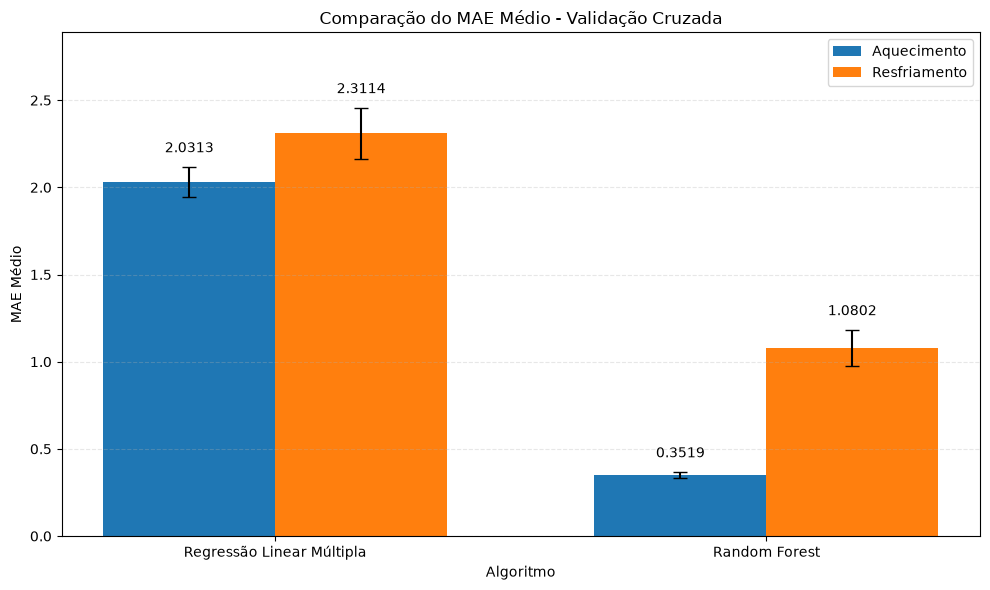

In [59]:

# Comparação gráfica do MAE médio dos quatro modelos

import matplotlib.pyplot as plt
import numpy as np

# Organizar os dados para o gráfico
modelos = ["Regressão Linear Múltipla", "Random Forest"]

mae_aq = [media_mae_cv_aq, media_mae_cv_rf_aq]
mae_res = [media_mae_cv_res, media_mae_cv_rf_res]

desvio_aq = [desvio_mae_cv_aq, desvio_mae_cv_rf_aq]
desvio_res = [desvio_mae_cv_res, desvio_mae_cv_rf_res]

# Definir as posições das barras
x = np.arange(len(modelos))
largura = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

# Barras da Carga de Aquecimento
barras_aq = ax.bar(
    x - largura / 2,
    mae_aq,
    largura,
    yerr=desvio_aq,
    capsize=5,
    label="Aquecimento"
)

# Barras da Carga de Resfriamento
barras_res = ax.bar(
    x + largura / 2,
    mae_res,
    largura,
    yerr=desvio_res,
    capsize=5,
    label="Resfriamento"
)

# Configurar o gráfico
ax.set_title("Comparação do MAE Médio - Validação Cruzada")
ax.set_ylabel("MAE Médio")
ax.set_xlabel("Algoritmo")
ax.set_xticks(x)
ax.set_xticklabels(modelos)
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.3)

# Exibir os valores sobre as barras
ax.bar_label(barras_aq, fmt="%.4f", padding=8)
ax.bar_label(barras_res, fmt="%.4f", padding=8)

# Ajustar os limites e o layout
ax.set_ylim(0, max(mae_aq + mae_res) * 1.25)

plt.tight_layout()
plt.show()


**Interpretação do gráfico de MAE**

O Random Forest Regressor apresentou menores valores médios de MAE para ambas as cargas energéticas.

Para Aquecimento, o MAE foi reduzido de 2,0313 para 0,3519, representando uma redução aproximada de 82,7%. Para Resfriamento, passou de 2,3114 para 1,0802, correspondendo a uma redução de aproximadamente 53,3%.

As barras de erro representam os desvios-padrão obtidos na validação cruzada, permitindo visualizar a variabilidade das métricas entre as cinco divisões.

### 23.3 - Comparação Gráfica do RMSE Médio

Nesta etapa, será realizada uma comparação gráfica da Raiz do Erro Quadrático Médio (RMSE) dos modelos de Regressão Linear Múltipla e Random Forest Regressor para as Cargas de Aquecimento e Resfriamento.

O RMSE é uma métrica que atribui maior peso aos erros de previsão de maior magnitude, permitindo avaliar a sensibilidade dos modelos a previsões mais distantes dos valores reais.

O gráfico apresentará os valores médios obtidos na validação cruzada com cinco divisões, acompanhados dos respectivos desvios-padrão.

Valores menores de RMSE indicam melhor desempenho preditivo, considerando especialmente a influência dos erros mais elevados.

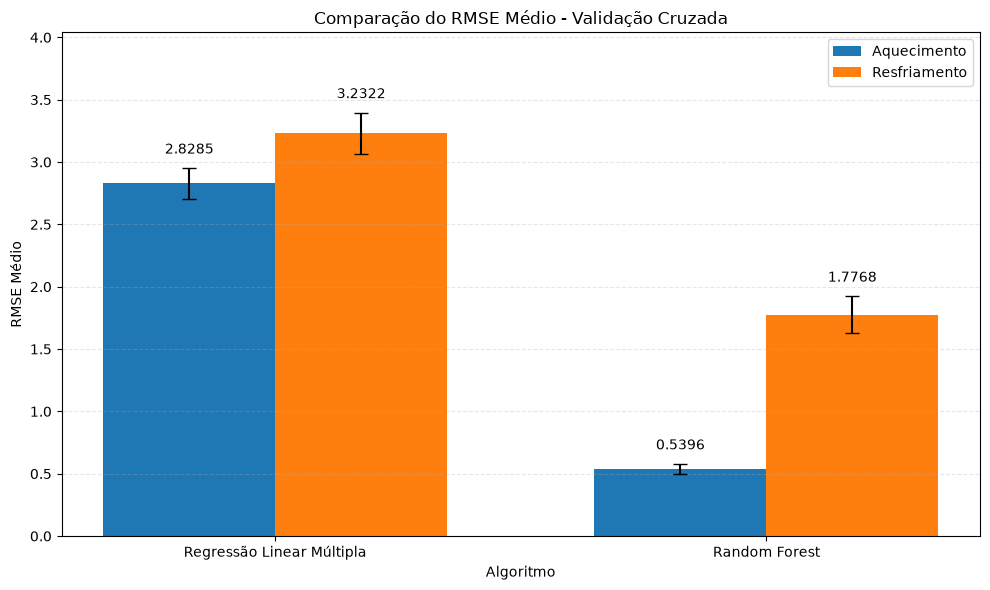

In [60]:

# Comparação gráfica do RMSE médio dos quatro modelos

modelos = ["Regressão Linear Múltipla", "Random Forest"]

rmse_aq = [media_rmse_cv_aq, media_rmse_cv_rf_aq]
rmse_res = [media_rmse_cv_res, media_rmse_cv_rf_res]

desvio_rmse_aq = [desvio_rmse_cv_aq, desvio_rmse_cv_rf_aq]
desvio_rmse_res = [desvio_rmse_cv_res, desvio_rmse_cv_rf_res]

# Definir posições das barras
x = np.arange(len(modelos))
largura = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

# Barras de Aquecimento
barras_aq = ax.bar(
    x - largura / 2,
    rmse_aq,
    largura,
    yerr=desvio_rmse_aq,
    capsize=5,
    label="Aquecimento"
)

# Barras de Resfriamento
barras_res = ax.bar(
    x + largura / 2,
    rmse_res,
    largura,
    yerr=desvio_rmse_res,
    capsize=5,
    label="Resfriamento"
)

# Configuração do gráfico
ax.set_title("Comparação do RMSE Médio - Validação Cruzada")
ax.set_ylabel("RMSE Médio")
ax.set_xlabel("Algoritmo")
ax.set_xticks(x)
ax.set_xticklabels(modelos)
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.3)

# Valores sobre as barras
ax.bar_label(barras_aq, fmt="%.4f", padding=8)
ax.bar_label(barras_res, fmt="%.4f", padding=8)

# Ajustar limites e layout
ax.set_ylim(0, max(rmse_aq + rmse_res) * 1.25)

plt.tight_layout()
plt.show()


**Interpretação do gráfico de RMSE**

O Random Forest Regressor apresentou menores valores médios de RMSE para ambas as cargas energéticas, indicando redução dos erros de previsão, especialmente daqueles de maior magnitude.

Para Aquecimento, o RMSE médio diminuiu de 2,8285 para 0,5396, representando uma redução aproximada de 80,9%. Para Resfriamento, passou de 3,2322 para 1,7768, correspondendo a uma redução aproximada de 45,0%.

A melhoria foi mais expressiva para a Carga de Aquecimento. Os desvios-padrão, representados pelas barras de erro, permitem observar a variabilidade do desempenho entre as cinco divisões da validação cruzada.

### 23.4 - Comparação Gráfica do R² Médio

Nesta etapa, será realizada uma comparação gráfica dos coeficientes de determinação (R²) médios obtidos pelos modelos de Regressão Linear Múltipla e Random Forest Regressor para as Cargas de Aquecimento e Resfriamento.

O R² permite avaliar a proporção da variabilidade da variável-alvo explicada pelo modelo, em comparação com uma previsão de referência baseada na média.

O gráfico apresentará os valores médios obtidos na validação cruzada com cinco divisões, acompanhados dos respectivos desvios-padrão.

Valores de R² mais próximos de 1 indicam maior capacidade preditiva, enquanto desvios-padrão menores indicam maior consistência dos resultados entre as rodadas de validação cruzada.

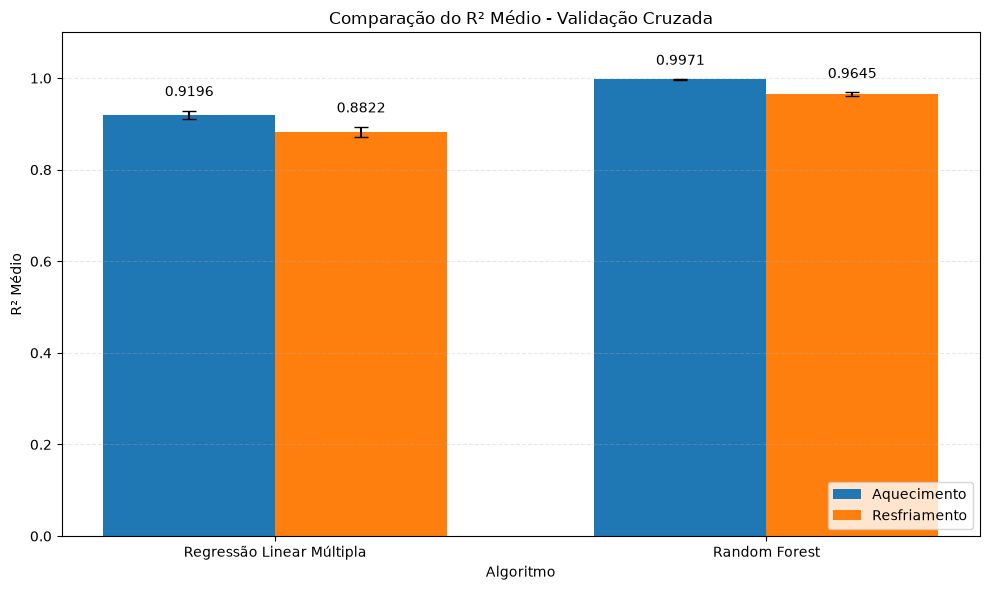

In [61]:

# Comparação gráfica do R² médio dos quatro modelos

modelos = ["Regressão Linear Múltipla", "Random Forest"]

r2_aq = [media_r2_cv_aq, media_r2_cv_rf_aq]
r2_res = [media_r2_cv_res, media_r2_cv_rf_res]

desvio_r2_aq = [desvio_r2_cv_aq, desvio_r2_cv_rf_aq]
desvio_r2_res = [desvio_r2_cv_res, desvio_r2_cv_rf_res]

# Definir as posições das barras
x = np.arange(len(modelos))
largura = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

# Barras da Carga de Aquecimento
barras_aq = ax.bar(
    x - largura / 2,
    r2_aq,
    largura,
    yerr=desvio_r2_aq,
    capsize=5,
    label="Aquecimento"
)

# Barras da Carga de Resfriamento
barras_res = ax.bar(
    x + largura / 2,
    r2_res,
    largura,
    yerr=desvio_r2_res,
    capsize=5,
    label="Resfriamento"
)

# Configurar o gráfico
ax.set_title("Comparação do R² Médio - Validação Cruzada")
ax.set_ylabel("R² Médio")
ax.set_xlabel("Algoritmo")
ax.set_xticks(x)
ax.set_xticklabels(modelos)
ax.legend(loc="lower right")
ax.grid(axis="y", linestyle="--", alpha=0.3)

# Exibir os valores sobre as barras
ax.bar_label(barras_aq, fmt="%.4f", padding=8)
ax.bar_label(barras_res, fmt="%.4f", padding=8)

# Escala do eixo vertical
ax.set_ylim(0, 1.10)

plt.tight_layout()
plt.show()


**Interpretação do gráfico de R²**

O Random Forest Regressor apresentou maiores coeficientes de determinação médios para ambas as cargas energéticas, demonstrando melhor capacidade preditiva em comparação com a Regressão Linear Múltipla.

Para Aquecimento, o R² médio aumentou de 0,9196 para 0,9971. Para Resfriamento, passou de 0,8822 para 0,9645.

Os resultados indicam que o Random Forest apresentou elevada capacidade de explicar a variabilidade das cargas energéticas nos subconjuntos de validação, especialmente para Aquecimento.

Os desvios-padrão relativamente pequenos indicam que os valores de R² apresentaram pouca variação entre as cinco divisões da validação cruzada.

### Conclusão da Comparação Geral dos Modelos

A comparação dos quatro modelos de regressão, utilizando validação cruzada K-Fold com cinco divisões, demonstrou que o algoritmo Random Forest Regressor apresentou desempenho preditivo superior ao da Regressão Linear Múltipla para as duas variáveis-alvo.

Essa superioridade foi observada nas três métricas avaliadas: menores valores de MAE e RMSE e maiores valores de R².

Para a Carga de Aquecimento, o Random Forest apresentou MAE médio de 0,3519, RMSE médio de 0,5396 e R² médio de 0,9971. Para a Carga de Resfriamento, os valores correspondentes foram 1,0802, 1,7768 e 0,9645.

A melhoria proporcionada pelo Random Forest foi particularmente expressiva para a Carga de Aquecimento, que apresentou os menores erros e o maior coeficiente de determinação entre os modelos avaliados.

Os desvios-padrão relativamente pequenos sugerem consistência dos resultados entre as diferentes divisões da validação cruzada.

Conclui-se que, para a base *Energy Efficiency* e nas condições de avaliação utilizadas, o Random Forest Regressor foi o algoritmo com melhor desempenho preditivo para ambas as cargas energéticas.

Na próxima seção, será realizada uma análise dos resíduos dos modelos Random Forest, com o objetivo de investigar a distribuição dos erros e identificar possíveis padrões de subestimação ou superestimação.

## 24 - Análise dos Resíduos dos Modelos Random Forest

A análise dos resíduos tem como objetivo investigar o comportamento dos erros de previsão dos modelos Random Forest Regressor aplicados às Cargas de Aquecimento e Resfriamento.

Embora as métricas MAE, RMSE e R² tenham demonstrado bom desempenho preditivo, a análise dos resíduos permite identificar possíveis padrões sistemáticos, tendências de subestimação ou superestimação e observações com erros de maior magnitude.

Os resíduos serão calculados pela diferença entre os valores reais e os valores previstos pelos modelos, utilizando as 154 observações do conjunto de teste.

### 24.1 - Cálculo dos Resíduos do Random Forest — Carga de Aquecimento

Nesta etapa, serão calculados os resíduos do modelo Random Forest Regressor para a Carga de Aquecimento.

Também serão determinadas a média e o desvio-padrão dos resíduos, permitindo avaliar o viés médio das previsões e a dispersão dos erros.

Resíduos com média próxima de zero indicam ausência de um viés médio expressivo no conjunto avaliado, embora isso não descarte a existência de padrões sistemáticos em determinadas faixas de valores.

In [62]:

# Calcular os resíduos do Random Forest - Aquecimento
residuos_rf_aquecimento = (
    y_aq_teste.to_numpy() - y_aq_previsto_rf
)

# Calcular a média e o desvio-padrão dos resíduos
media_residuos_rf_aq = np.mean(residuos_rf_aquecimento)
desvio_residuos_rf_aq = np.std(residuos_rf_aquecimento)

# Exibir os resultados
print("Resíduos do Random Forest - Carga de Aquecimento")
print("-" * 55)

print(f"Média dos resíduos: {media_residuos_rf_aq:.4f}")
print(f"Desvio-padrão dos resíduos: {desvio_residuos_rf_aq:.4f}")
print(f"Menor resíduo: {np.min(residuos_rf_aquecimento):.4f}")
print(f"Maior resíduo: {np.max(residuos_rf_aquecimento):.4f}")


Resíduos do Random Forest - Carga de Aquecimento
-------------------------------------------------------
Média dos resíduos: -0.0198
Desvio-padrão dos resíduos: 0.5328
Menor resíduo: -1.3608
Maior resíduo: 1.3615


**Interpretação dos resíduos — Carga de Aquecimento**

Os resíduos do modelo Random Forest para Aquecimento apresentaram média de -0,0198 e desvio-padrão de 0,5328.

A média próxima de zero indica um viés médio muito pequeno, com discreta tendência à superestimação. O desvio-padrão evidencia uma dispersão relativamente reduzida dos erros, coerente com o RMSE de 0,5332 obtido no conjunto de teste.

Os resíduos variaram entre -1,3608 e +1,3615, indicando a ocorrência de erros individuais em ambas as direções, apesar do bom desempenho preditivo global.

### 24.2 - Gráfico de Dispersão dos Resíduos — Random Forest para Aquecimento

Nesta etapa, será construído um gráfico de dispersão dos resíduos em função dos valores previstos pelo modelo Random Forest Regressor para a Carga de Aquecimento.

O objetivo é investigar o comportamento dos erros de previsão e identificar possíveis padrões sistemáticos, tendências de subestimação ou superestimação e alterações na dispersão dos resíduos ao longo das diferentes faixas de carga energética.

O eixo horizontal representará os valores previstos pelo modelo, enquanto o eixo vertical apresentará os respectivos resíduos, calculados pela diferença entre os valores reais e os valores previstos.

Uma linha horizontal em zero será utilizada como referência para distinguir resíduos positivos e negativos.

Uma distribuição dos pontos sem padrões sistemáticos evidentes, em torno da linha de referência, é um comportamento desejável. Entretanto, essa característica não garante, isoladamente, a ausência de problemas no modelo.

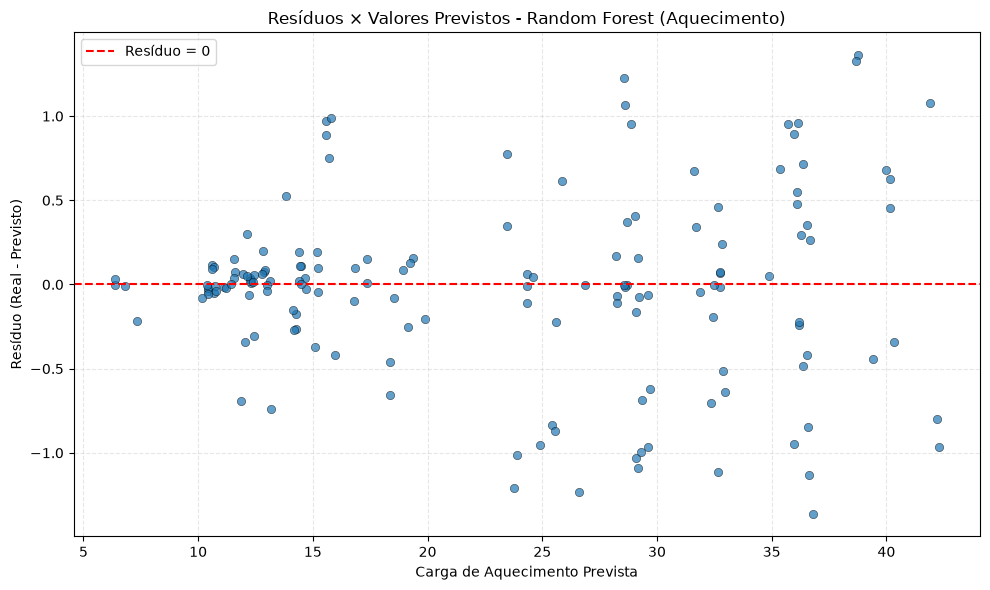

In [63]:

# Gráfico de dispersão dos resíduos - Random Forest Aquecimento

fig, ax = plt.subplots(figsize=(10, 6))

# Dispersão dos resíduos em função dos valores previstos
ax.scatter(
    y_aq_previsto_rf,
    residuos_rf_aquecimento,
    alpha=0.7,
    edgecolors="black",
    linewidths=0.4
)

# Linha horizontal de referência
ax.axhline(
    y=0,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label="Resíduo = 0"
)

# Configurações do gráfico
ax.set_title(
    "Resíduos × Valores Previstos - Random Forest (Aquecimento)"
)
ax.set_xlabel("Carga de Aquecimento Prevista")
ax.set_ylabel("Resíduo (Real - Previsto)")

ax.legend()
ax.grid(alpha=0.3, linestyle="--")

plt.tight_layout()
plt.show()


**Interpretação do gráfico de dispersão — Aquecimento**

O gráfico apresenta resíduos positivos e negativos ao longo das diferentes faixas de Carga de Aquecimento prevista, sem uma tendência claramente crescente ou decrescente da média dos erros.

Nas faixas de cargas mais baixas, aproximadamente entre 10 e 14, observa-se maior concentração dos resíduos próximos de zero. Nas faixas intermediárias e elevadas, a dispersão aumenta, com erros individuais de maior magnitude.

Esse comportamento sugere que a variabilidade dos resíduos pode não ser constante ao longo dos valores previstos, indicando possível heterocedasticidade. Entretanto, essa observação é exploratória e não constitui confirmação estatística.

De modo geral, o modelo apresentou erros reduzidos, embora sua precisão varie entre determinadas faixas de carga energética.

### 24.3 - Histograma dos Resíduos — Random Forest para Aquecimento

Nesta etapa, será analisada a distribuição dos resíduos do modelo Random Forest Regressor para a Carga de Aquecimento por meio de um histograma normalizado.

O objetivo é verificar a concentração dos erros próximos de zero, identificar possíveis assimetrias e observar a presença de resíduos de maior magnitude.

Será adicionada uma curva de distribuição normal teórica, construída a partir da média e do desvio-padrão dos resíduos, exclusivamente como referência visual.

A comparação permitirá avaliar qualitativamente a forma da distribuição dos erros, sem pressupor que a normalidade dos resíduos seja uma condição necessária para o funcionamento do algoritmo Random Forest.

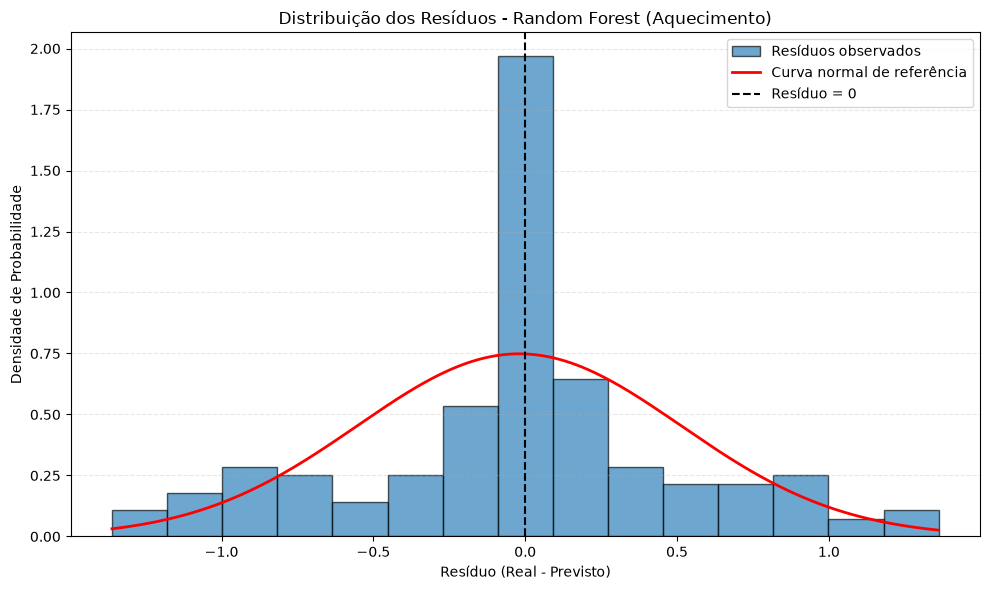

In [64]:

# Histograma dos resíduos - Random Forest Aquecimento

from scipy.stats import norm

fig, ax = plt.subplots(figsize=(10, 6))

# Histograma normalizado
ax.hist(
    residuos_rf_aquecimento,
    bins=15,
    density=True,
    alpha=0.65,
    edgecolor="black",
    label="Resíduos observados"
)

# Valores para construir a curva normal de referência
x_normal = np.linspace(
    residuos_rf_aquecimento.min(),
    residuos_rf_aquecimento.max(),
    300
)

# Curva normal com média e desvio-padrão dos resíduos
y_normal = norm.pdf(
    x_normal,
    loc=media_residuos_rf_aq,
    scale=desvio_residuos_rf_aq
)

ax.plot(
    x_normal,
    y_normal,
    color="red",
    linewidth=2,
    label="Curva normal de referência"
)

# Linha vertical em zero
ax.axvline(
    x=0,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Resíduo = 0"
)

# Configurações
ax.set_title("Distribuição dos Resíduos - Random Forest (Aquecimento)")
ax.set_xlabel("Resíduo (Real - Previsto)")
ax.set_ylabel("Densidade de Probabilidade")

ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()


**Interpretação do histograma — Aquecimento**

O histograma apresenta uma elevada concentração de resíduos próximos de zero, indicando que muitas previsões do Random Forest apresentaram erros de pequena magnitude.

A distribuição possui um pico central mais acentuado do que a curva normal teórica utilizada como referência. Também são observados resíduos positivos e negativos mais afastados, aproximadamente entre -1,36 e +1,36.

Não se observa uma assimetria visual claramente dominante. Entretanto, a distribuição não apresenta uma forma perfeitamente semelhante à normal.

A análise é exploratória, pois a aparência do histograma depende também da quantidade e da largura dos intervalos utilizados. Além disso, a normalidade dos resíduos não é uma exigência para o funcionamento do algoritmo Random Forest.

### 24.4 - Cálculo dos Resíduos do Random Forest — Carga de Resfriamento

Nesta etapa, serão calculados os resíduos do modelo Random Forest Regressor para a Carga de Resfriamento, utilizando as 154 observações do conjunto de teste.

Os resíduos serão determinados pela diferença entre os valores reais e os valores previstos pelo modelo.

Serão calculadas a média, o desvio-padrão e os valores mínimo e máximo dos resíduos, permitindo avaliar o viés médio, a dispersão e os erros extremos das previsões.

Os resultados também permitirão uma comparação com aqueles obtidos anteriormente para a Carga de Aquecimento, contribuindo para a investigação das diferenças de desempenho preditivo entre as duas variáveis-alvo.

In [65]:

# Calcular os resíduos do Random Forest - Resfriamento
residuos_rf_resfriamento = (
    y_res_teste.to_numpy() - y_res_previsto_rf
)

# Calcular a média e o desvio-padrão dos resíduos
media_residuos_rf_res = np.mean(residuos_rf_resfriamento)
desvio_residuos_rf_res = np.std(residuos_rf_resfriamento)

# Exibir os resultados
print("Resíduos do Random Forest - Carga de Resfriamento")
print("-" * 55)

print(f"Média dos resíduos: {media_residuos_rf_res:.4f}")
print(f"Desvio-padrão dos resíduos: {desvio_residuos_rf_res:.4f}")
print(f"Menor resíduo: {np.min(residuos_rf_resfriamento):.4f}")
print(f"Maior resíduo: {np.max(residuos_rf_resfriamento):.4f}")


Resíduos do Random Forest - Carga de Resfriamento
-------------------------------------------------------
Média dos resíduos: 0.0095
Desvio-padrão dos resíduos: 2.0299
Menor resíduo: -7.0479
Maior resíduo: 5.3853


**Interpretação dos resíduos — Carga de Resfriamento**

Os resíduos do modelo Random Forest para Resfriamento apresentaram média de +0,0095 e desvio-padrão de 2,0299.

A média praticamente nula indica um viés médio muito pequeno, com discreta tendência à subestimação. Entretanto, erros positivos e negativos podem se compensar, de modo que uma média próxima de zero não significa ausência de erros individuais expressivos.

Os resíduos variaram entre -7,0479 e +5,3853, evidenciando a ocorrência de superestimativas e subestimativas de maior magnitude.

Em comparação com Aquecimento, o desvio-padrão dos resíduos foi aproximadamente 3,8 vezes maior, indicando maior dispersão dos erros de previsão da Carga de Resfriamento.

### 24.5 - Gráfico de Dispersão dos Resíduos — Random Forest para Resfriamento

Nesta etapa, será construído um gráfico de dispersão dos resíduos em função dos valores previstos pelo modelo Random Forest Regressor para a Carga de Resfriamento.

O objetivo é investigar o comportamento dos erros de previsão, identificando possíveis padrões sistemáticos, tendências de subestimação ou superestimação e diferenças na dispersão dos resíduos entre as faixas de carga energética.

O eixo horizontal representará os valores previstos pelo modelo, enquanto o eixo vertical apresentará os resíduos, calculados pela diferença entre os valores reais e os previstos.

Uma linha horizontal em zero será utilizada como referência.

A análise também permitirá comparar visualmente a distribuição dos resíduos de Resfriamento com aquela observada anteriormente para Aquecimento, investigando possíveis diferenças na magnitude e no comportamento dos erros.

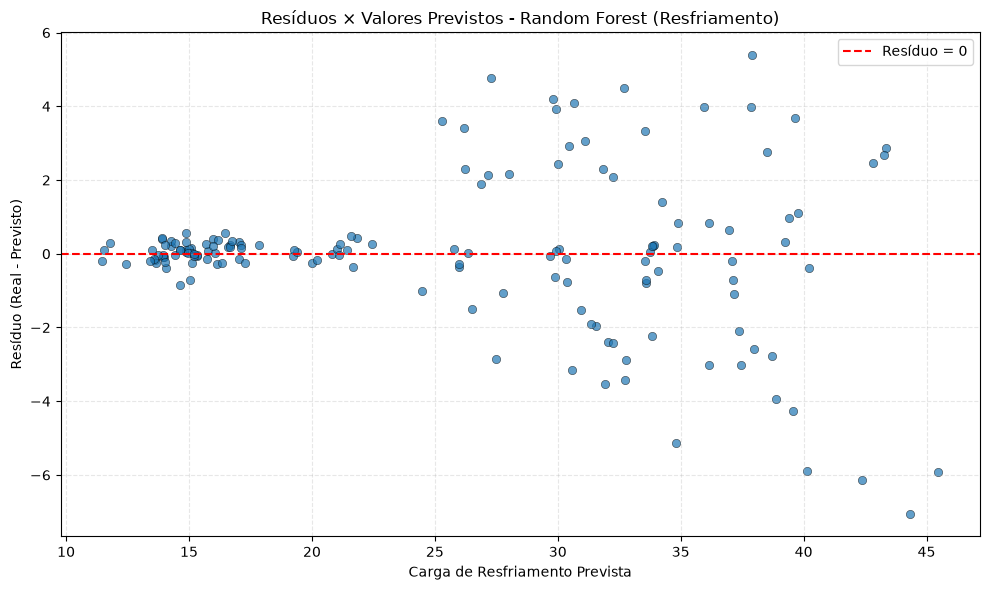

In [66]:

# Gráfico de dispersão dos resíduos - Random Forest Resfriamento

fig, ax = plt.subplots(figsize=(10, 6))

# Dispersão dos resíduos em função dos valores previstos
ax.scatter(
    y_res_previsto_rf,
    residuos_rf_resfriamento,
    alpha=0.7,
    edgecolors="black",
    linewidths=0.4
)

# Linha horizontal de referência
ax.axhline(
    y=0,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label="Resíduo = 0"
)

# Configurações do gráfico
ax.set_title(
    "Resíduos × Valores Previstos - Random Forest (Resfriamento)"
)
ax.set_xlabel("Carga de Resfriamento Prevista")
ax.set_ylabel("Resíduo (Real - Previsto)")

ax.legend()
ax.grid(alpha=0.3, linestyle="--")

plt.tight_layout()
plt.show()


**Interpretação do gráfico de dispersão — Resfriamento**

O gráfico apresenta resíduos positivos e negativos ao longo das diferentes faixas de Carga de Resfriamento prevista, com dispersão mais elevada do que a observada para Aquecimento.

Nas faixas de cargas mais baixas, aproximadamente entre 12 e 22, os resíduos apresentam maior concentração próximos de zero, indicando previsões relativamente precisas para muitas dessas observações.

Nas faixas intermediárias e elevadas, a dispersão aumenta significativamente, com erros individuais negativos próximos de -7 e positivos superiores a +5.

Esse comportamento sugere possível heterocedasticidade, isto é, variação da dispersão dos erros conforme os valores previstos. Entretanto, o gráfico não permite confirmar estatisticamente essa característica.

A maior dispersão dos resíduos de Resfriamento é coerente com os valores superiores de MAE e RMSE obtidos anteriormente para esse modelo.

### 24.6 - Histograma dos Resíduos — Random Forest para Resfriamento

Nesta etapa, será analisada a distribuição dos resíduos do modelo Random Forest Regressor para a Carga de Resfriamento por meio de um histograma normalizado.

O objetivo é verificar a concentração dos erros próximos de zero, identificar possíveis assimetrias e observar a ocorrência de resíduos de maior magnitude.

Será adicionada uma curva de distribuição normal teórica, construída a partir da média e do desvio-padrão dos resíduos, exclusivamente como referência visual.

A análise permitirá comparar a forma da distribuição dos resíduos de Resfriamento com aquela observada anteriormente para Aquecimento, contribuindo para a interpretação das diferenças de desempenho preditivo entre as duas variáveis-alvo.

A normalidade dos resíduos não constitui uma exigência para o funcionamento do algoritmo Random Forest.

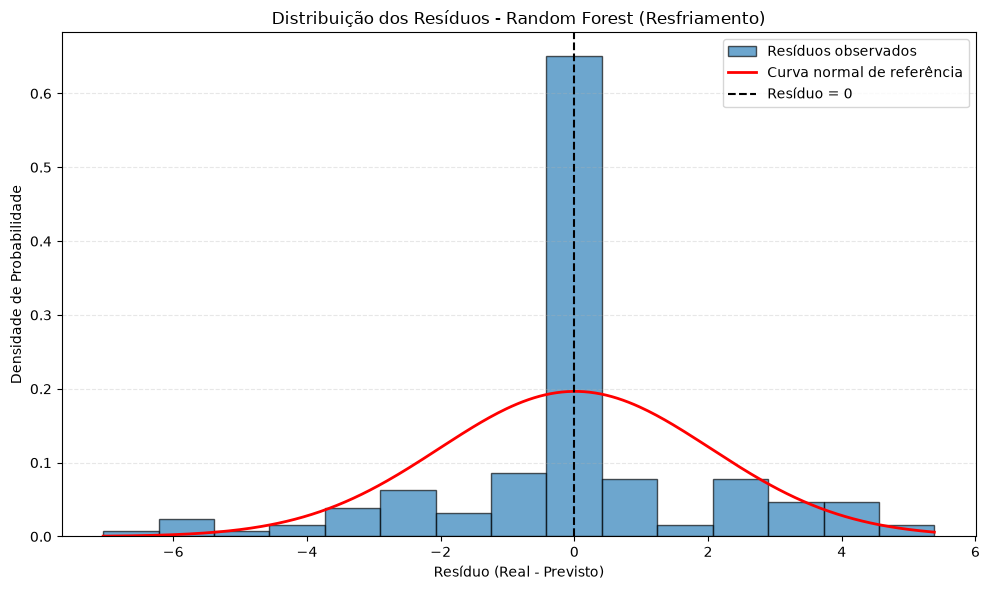

In [67]:

# Histograma dos resíduos - Random Forest Resfriamento

fig, ax = plt.subplots(figsize=(10, 6))

# Histograma normalizado
ax.hist(
    residuos_rf_resfriamento,
    bins=15,
    density=True,
    alpha=0.65,
    edgecolor="black",
    label="Resíduos observados"
)

# Valores para construir a curva normal de referência
x_normal_res = np.linspace(
    residuos_rf_resfriamento.min(),
    residuos_rf_resfriamento.max(),
    300
)

# Curva normal com média e desvio-padrão dos resíduos
y_normal_res = norm.pdf(
    x_normal_res,
    loc=media_residuos_rf_res,
    scale=desvio_residuos_rf_res
)

ax.plot(
    x_normal_res,
    y_normal_res,
    color="red",
    linewidth=2,
    label="Curva normal de referência"
)

# Linha vertical em zero
ax.axvline(
    x=0,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Resíduo = 0"
)

# Configurações
ax.set_title("Distribuição dos Resíduos - Random Forest (Resfriamento)")
ax.set_xlabel("Resíduo (Real - Previsto)")
ax.set_ylabel("Densidade de Probabilidade")

ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()


**Interpretação do histograma — Resfriamento**

O histograma apresenta uma concentração acentuada de resíduos próximos de zero, indicando que muitas previsões tiveram erros de pequena magnitude.

Entretanto, também são observados resíduos mais afastados, aproximadamente entre -7,05 e +5,39, evidenciando a ocorrência de erros individuais expressivos.

A distribuição apresenta um pico central mais acentuado do que a curva normal teórica utilizada como referência. A cauda negativa se estende mais do que a positiva, embora essa observação visual não permita concluir que exista assimetria estatisticamente significativa.

Em comparação com Aquecimento, os resíduos de Resfriamento apresentam maior dispersão, coerente com seu desvio-padrão de 2,0299 e com o desempenho inferior nas métricas de erro.

A ausência de uma distribuição visualmente normal não constitui, por si só, uma limitação para a utilização do algoritmo Random Forest.

### Conclusão da Análise dos Resíduos dos Modelos Random Forest

A análise dos resíduos dos modelos Random Forest Regressor demonstrou diferenças importantes no comportamento dos erros de previsão das Cargas de Aquecimento e Resfriamento.

Ambos os modelos apresentaram médias dos resíduos muito próximas de zero, indicando ausência de viés médio expressivo no conjunto de teste. Entretanto, isso não significa que todos os erros individuais tenham sido pequenos.

O modelo de Aquecimento apresentou menor dispersão dos resíduos, com desvio-padrão de 0,5328 e erros individuais entre -1,3608 e +1,3615.

Para Resfriamento, o desvio-padrão foi de 2,0299, com resíduos entre -7,0479 e +5,3853, evidenciando maior variabilidade dos erros.

Os gráficos de dispersão sugerem que os erros tendem a apresentar maior magnitude em determinadas faixas de carga energética, especialmente para Resfriamento. Esse comportamento pode indicar heterocedasticidade, embora a análise gráfica não permita confirmá-la estatisticamente.

Os histogramas revelaram elevada concentração de resíduos próximos de zero, acompanhada de observações com erros mais expressivos. As distribuições não apresentaram formato visualmente semelhante ao de uma distribuição normal, característica que não impede a utilização do Random Forest.

Conclui-se que ambos os modelos apresentaram bom desempenho preditivo, porém o modelo de Aquecimento demonstrou maior precisão e menor dispersão dos erros em comparação com o modelo de Resfriamento.

Esses resultados complementam as métricas MAE, RMSE e R² apresentadas anteriormente e contribuem para uma avaliação mais abrangente do comportamento preditivo dos modelos.

## 25 - Importância das Variáveis nos Modelos Random Forest

Nesta seção, será investigada a importância preditiva das características arquitetônicas das edificações nos modelos Random Forest Regressor utilizados para estimar as Cargas de Aquecimento e Resfriamento.

Será empregada a técnica de Importância por Permutação (*Permutation Importance*), que avalia a contribuição de cada variável por meio da alteração do desempenho do modelo após o embaralhamento aleatório de seus valores.

A análise será realizada utilizando os modelos previamente treinados e as observações do conjunto de teste.

Como métrica de avaliação, será utilizado o coeficiente de determinação R². Valores positivos mais elevados de importância indicam maiores reduções do desempenho quando a informação da variável é embaralhada.

Os resultados permitirão comparar a importância preditiva das características arquitetônicas com as correlações identificadas anteriormente na análise exploratória dos dados.

É importante destacar que a importância por permutação não estabelece relações de causalidade e pode ser influenciada pela existência de correlações entre as variáveis explicativas.

### 25.1 - Cálculo da Importância das Variáveis — Random Forest para Aquecimento

Nesta etapa, será calculada a importância por permutação das oito características arquitetônicas utilizadas pelo modelo Random Forest Regressor para prever a Carga de Aquecimento.

O procedimento será aplicado ao Pipeline completo, utilizando as 154 observações do conjunto de teste.

Cada variável será embaralhada aleatoriamente dez vezes, permitindo calcular a importância média e o desvio-padrão das alterações no desempenho do modelo.

As variáveis serão posteriormente organizadas em ordem decrescente de importância preditiva.

In [68]:

# Importância das variáveis - Random Forest Aquecimento

from sklearn.inspection import permutation_importance

# Calcular a importância por permutação
importancia_rf_aquecimento = permutation_importance(
    estimator=pipeline_rf_aquecimento,
    X=X_teste,
    y=y_aq_teste,
    scoring="r2",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

# Organizar os resultados em um DataFrame
tabela_importancia_rf_aquecimento = pd.DataFrame({
    "Variável": X_teste.columns,
    "Importância Média": importancia_rf_aquecimento.importances_mean,
    "Desvio-padrão": importancia_rf_aquecimento.importances_std
})

# Ordenar as variáveis por importância decrescente
tabela_importancia_rf_aquecimento = (
    tabela_importancia_rf_aquecimento
    .sort_values(by="Importância Média", ascending=False)
    .reset_index(drop=True)
)

# Exibir os resultados
tabela_importancia_rf_aquecimento.round(4)


,Variável,Importância Média,Desvio-padrão
0,Compacidade Relativa,0.3808,0.0308
1,Área de Envidraçamento,0.1383,0.0142
2,Área de Superfície,0.0701,0.0044
3,Área de Parede,0.0556,0.0066
4,Altura Total,0.0532,0.0046
5,Área de Telhado,0.0522,0.0047
6,Distribuição da Área Envidraçada,0.0100,0.0008
7,Orientação,-0.0002,0.0001


**Interpretação da importância por permutação — Carga de Aquecimento**

A Compacidade Relativa apresentou a maior importância preditiva, com redução média de 0,3808 no R² após o embaralhamento de seus valores, seguida pela Área de Envidraçamento, com importância média de 0,1383.

As variáveis Área de Superfície, Área de Parede, Altura Total e Área de Telhado apresentaram importâncias intermediárias. A Orientação apresentou importância praticamente nula (-0,0002), indicando que seu embaralhamento não provocou alteração relevante no desempenho do modelo.

Esses resultados diferem parcialmente das correlações identificadas na EDA, na qual a Altura Total e a Área de Telhado apresentaram associações lineares expressivas com a Carga de Aquecimento.

Essa diferença ocorre porque a correlação de Pearson mede a associação linear entre duas variáveis, enquanto a importância por permutação mede a alteração do desempenho de um modelo treinado após o embaralhamento de uma característica.

As importâncias também podem ser influenciadas pela correlação entre as características arquitetônicas e não devem ser interpretadas como medidas de causalidade.

### 25.2 - Representação Gráfica da Importância das Variáveis — Random Forest para Aquecimento

Nesta etapa, será construída uma representação gráfica da importância preditiva das características arquitetônicas utilizadas pelo modelo Random Forest Regressor para a Carga de Aquecimento.

As variáveis serão apresentadas em ordem decrescente de importância média, calculada pela técnica de Importância por Permutação (*Permutation Importance*).

Serão utilizadas barras horizontais para facilitar a comparação entre as características arquitetônicas, acompanhadas de barras de erro que representam os desvios-padrão obtidos nas dez repetições do procedimento.

O gráfico permitirá identificar quais variáveis provocaram as maiores reduções do coeficiente de determinação R² quando seus valores foram embaralhados.

A interpretação considerará que a importância preditiva pode ser influenciada pela correlação entre as variáveis e não representa, necessariamente, uma relação causal.

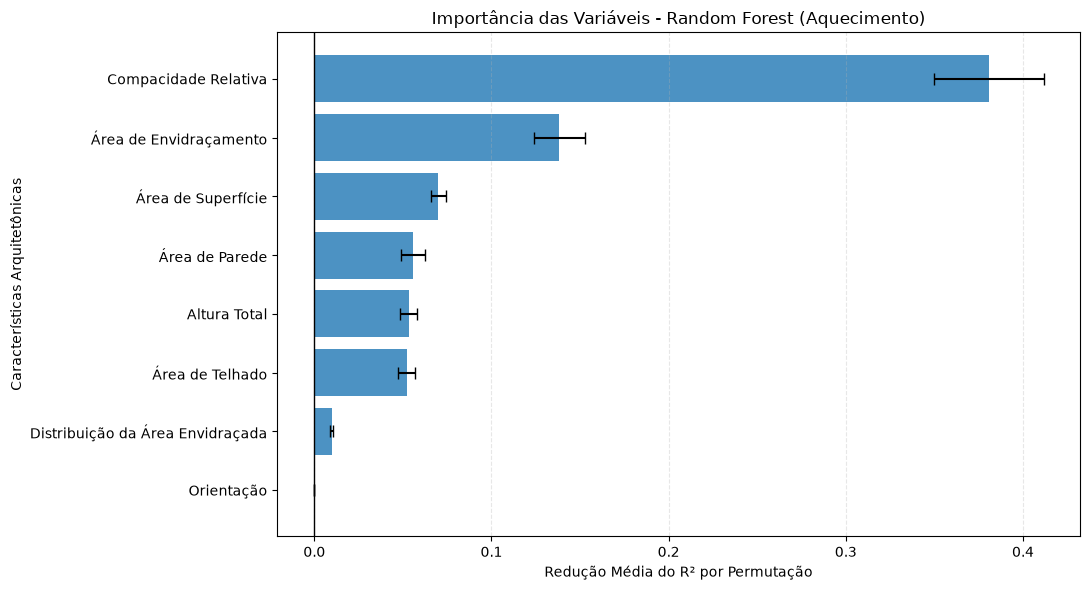

In [69]:

# Gráfico da importância das variáveis - Random Forest Aquecimento

# Ordenar para apresentação no gráfico horizontal
dados_grafico = tabela_importancia_rf_aquecimento.sort_values(
    by="Importância Média",
    ascending=True
)

fig, ax = plt.subplots(figsize=(11, 6))

# Barras horizontais com desvios-padrão
ax.barh(
    dados_grafico["Variável"],
    dados_grafico["Importância Média"],
    xerr=dados_grafico["Desvio-padrão"],
    capsize=4,
    alpha=0.8
)

# Linha de referência
ax.axvline(
    x=0,
    color="black",
    linewidth=1
)

# Configurações do gráfico
ax.set_title(
    "Importância das Variáveis - Random Forest (Aquecimento)"
)
ax.set_xlabel("Redução Média do R² por Permutação")
ax.set_ylabel("Características Arquitetônicas")

ax.grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()


### 25.3 - Cálculo da Importância das Variáveis — Random Forest para Resfriamento

Nesta etapa, será calculada a importância preditiva das oito características arquitetônicas utilizadas pelo modelo Random Forest Regressor para a previsão da Carga de Resfriamento.

Será empregada a técnica de Importância por Permutação (*Permutation Importance*), utilizando as 154 observações do conjunto de teste.

Cada variável será embaralhada aleatoriamente dez vezes, permitindo calcular a redução média do coeficiente de determinação R² e o respectivo desvio-padrão.

Os resultados serão organizados em ordem decrescente de importância, permitindo identificar quais características arquitetônicas apresentam maior contribuição para o desempenho preditivo do modelo.

Posteriormente, os resultados serão comparados com aqueles obtidos para a Carga de Aquecimento, possibilitando investigar semelhanças e diferenças entre as duas variáveis-alvo.

In [70]:

# Importância das variáveis - Random Forest Resfriamento

# Calcular a importância por permutação
importancia_rf_resfriamento = permutation_importance(
    estimator=pipeline_rf_resfriamento,
    X=X_teste,
    y=y_res_teste,
    scoring="r2",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

# Organizar os resultados em um DataFrame
tabela_importancia_rf_resfriamento = pd.DataFrame({
    "Variável": X_teste.columns,
    "Importância Média": importancia_rf_resfriamento.importances_mean,
    "Desvio-padrão": importancia_rf_resfriamento.importances_std
})

# Ordenar por importância decrescente
tabela_importancia_rf_resfriamento = (
    tabela_importancia_rf_resfriamento
    .sort_values(by="Importância Média", ascending=False)
    .reset_index(drop=True)
)

# Exibir os resultados
tabela_importancia_rf_resfriamento.round(4)


,Variável,Importância Média,Desvio-padrão
0,Compacidade Relativa,0.3401,0.0343
1,Altura Total,0.2028,0.0214
2,Área de Envidraçamento,0.0768,0.0090
3,Área de Parede,0.0378,0.0039
4,Área de Telhado,0.0271,0.0048
5,Área de Superfície,0.0211,0.0051
6,Distribuição da Área Envidraçada,0.0023,0.0033
7,Orientação,0.0011,0.0037


**Interpretação da importância por permutação — Resfriamento**

A Compacidade Relativa apresentou a maior importância preditiva, com redução média de 0,3401 no R² após o embaralhamento de seus valores.

A Altura Total apresentou a segunda maior importância (0,2028), seguida pela Área de Envidraçamento (0,0768).

As variáveis Área de Parede, Área de Telhado e Área de Superfície apresentaram importâncias menores. A Distribuição da Área Envidraçada e a Orientação apresentaram valores próximos de zero, indicando pouca alteração do desempenho preditivo quando seus valores foram embaralhados.

Os resultados indicam que o modelo de Resfriamento depende especialmente das informações de Compacidade Relativa e Altura Total. Entretanto, essas importâncias descrevem o comportamento do modelo treinado e não estabelecem relações causais entre as características arquitetônicas e a carga energética.

### 25.4 - Representação Gráfica da Importância das Variáveis — Random Forest para Resfriamento

Nesta etapa, será construída uma representação gráfica da importância preditiva das características arquitetônicas utilizadas pelo modelo Random Forest Regressor para a Carga de Resfriamento.

As variáveis serão apresentadas em ordem decrescente de importância média, calculada por meio da técnica de Importância por Permutação (*Permutation Importance*).

Serão utilizadas barras horizontais para facilitar a comparação entre as características arquitetônicas, acompanhadas de barras de erro que representam os desvios-padrão obtidos nas dez repetições do procedimento.

O gráfico permitirá identificar quais variáveis provocaram as maiores reduções do coeficiente de determinação R² quando seus valores foram embaralhados.

Os resultados serão posteriormente comparados com aqueles obtidos para a Carga de Aquecimento, permitindo investigar semelhanças e diferenças na importância preditiva das características arquitetônicas para as duas variáveis-alvo.

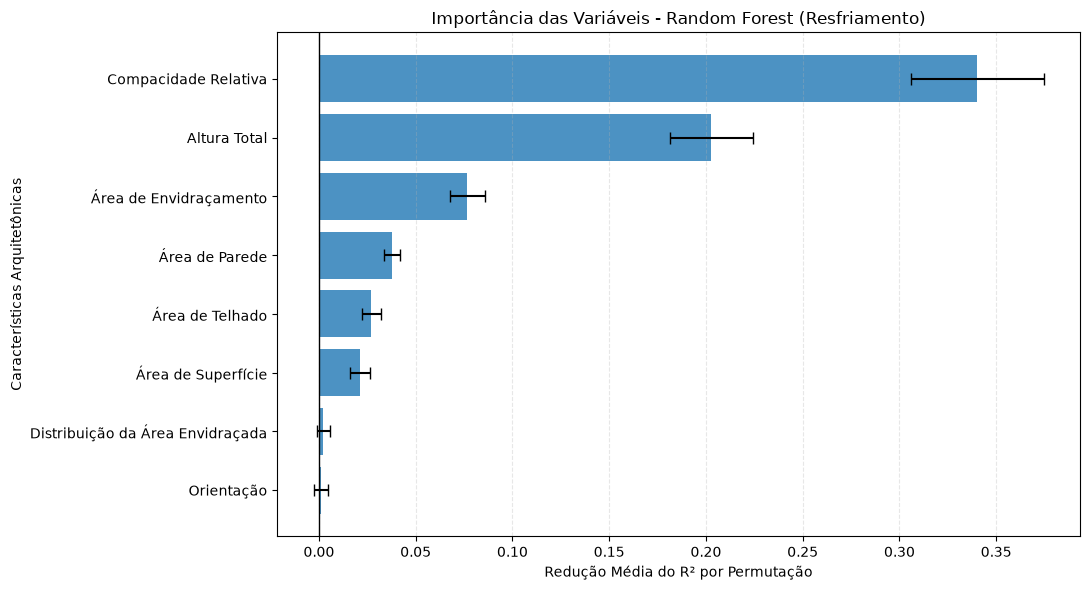

In [71]:

# Gráfico da importância das variáveis - Random Forest Resfriamento

# Ordenar para apresentação no gráfico horizontal
dados_grafico_res = tabela_importancia_rf_resfriamento.sort_values(
    by="Importância Média",
    ascending=True
)

fig, ax = plt.subplots(figsize=(11, 6))

# Barras horizontais com desvios-padrão
ax.barh(
    dados_grafico_res["Variável"],
    dados_grafico_res["Importância Média"],
    xerr=dados_grafico_res["Desvio-padrão"],
    capsize=4,
    alpha=0.8
)

# Linha vertical de referência
ax.axvline(
    x=0,
    color="black",
    linewidth=1
)

# Configurações do gráfico
ax.set_title(
    "Importância das Variáveis - Random Forest (Resfriamento)"
)
ax.set_xlabel("Redução Média do R² por Permutação")
ax.set_ylabel("Características Arquitetônicas")

ax.grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()


### 25.5 - Comparação Gráfica da Importância das Variáveis — Aquecimento × Resfriamento

Nesta etapa, será realizada uma comparação gráfica da importância preditiva das características arquitetônicas utilizadas pelos modelos Random Forest Regressor para as Cargas de Aquecimento e Resfriamento.

Serão utilizadas as importâncias médias calculadas pela técnica de Importância por Permutação, considerando as dez repetições realizadas sobre o conjunto de teste.

O gráfico apresentará barras horizontais agrupadas para cada característica arquitetônica, permitindo comparar diretamente a redução média do coeficiente de determinação R² nos dois modelos.

Também serão representados os respectivos desvios-padrão, permitindo observar a variabilidade das importâncias estimadas.

O objetivo é identificar semelhanças e diferenças na dependência preditiva dos modelos em relação às características arquitetônicas das edificações.

A interpretação considerará que as importâncias por permutação podem ser influenciadas pelas correlações entre as variáveis explicativas e não representam medidas de causalidade.

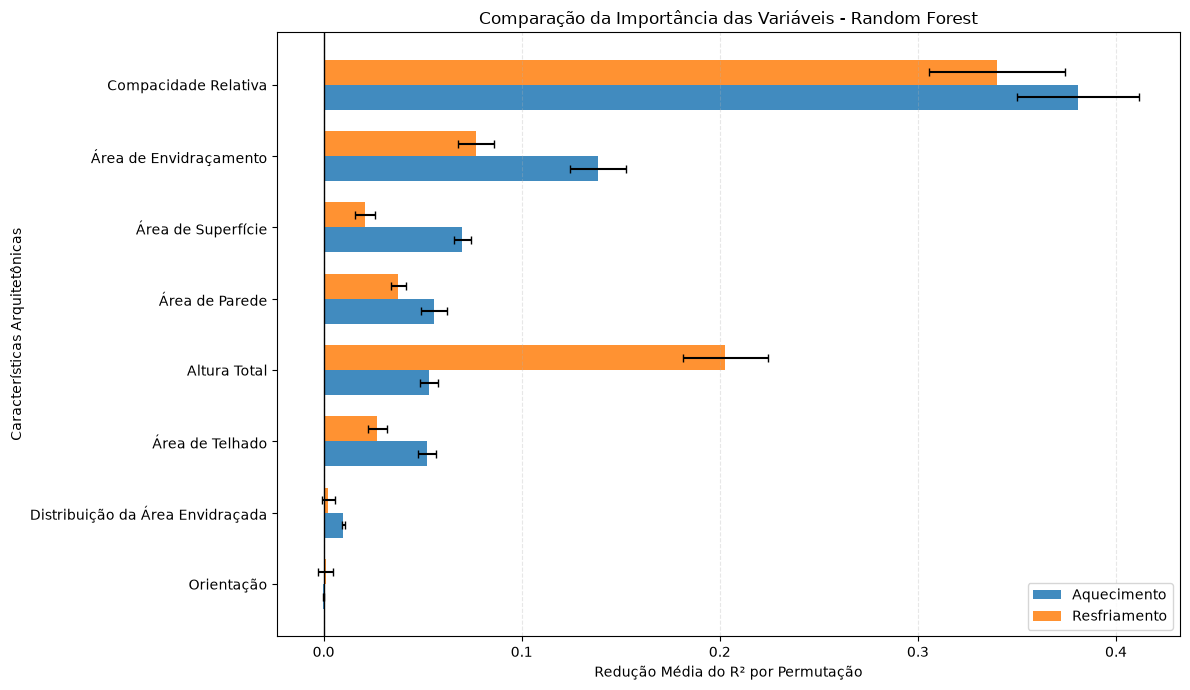

In [72]:

# Comparação da importância das variáveis - Aquecimento x Resfriamento

# Reunir os resultados das duas análises
tabela_importancia_comparativa = pd.DataFrame({
    "Variável": X_teste.columns
})

tabela_importancia_comparativa = (
    tabela_importancia_comparativa
    .merge(
        tabela_importancia_rf_aquecimento.rename(columns={
            "Importância Média": "Aquecimento",
            "Desvio-padrão": "Desvio Aquecimento"
        }),
        on="Variável"
    )
    .merge(
        tabela_importancia_rf_resfriamento.rename(columns={
            "Importância Média": "Resfriamento",
            "Desvio-padrão": "Desvio Resfriamento"
        }),
        on="Variável"
    )
)

# Ordenar pela importância média no modelo de Aquecimento
tabela_importancia_comparativa = (
    tabela_importancia_comparativa
    .sort_values("Aquecimento", ascending=True)
)

# Posições das barras
posicoes_barras = np.arange(len(tabela_importancia_comparativa))
altura = 0.35

fig, ax = plt.subplots(figsize=(12, 7))

# Barras de Aquecimento
ax.barh(
    posicoes_barras - altura / 2,
    tabela_importancia_comparativa["Aquecimento"],
    height=altura,
    xerr=tabela_importancia_comparativa["Desvio Aquecimento"],
    capsize=3,
    label="Aquecimento",
    alpha=0.85
)

# Barras de Resfriamento
ax.barh(
    posicoes_barras + altura / 2,
    tabela_importancia_comparativa["Resfriamento"],
    height=altura,
    xerr=tabela_importancia_comparativa["Desvio Resfriamento"],
    capsize=3,
    label="Resfriamento",
    alpha=0.85
)

# Configurações do gráfico
ax.set_yticks(posicoes_barras)
ax.set_yticklabels(tabela_importancia_comparativa["Variável"])

ax.set_title(
    "Comparação da Importância das Variáveis - Random Forest"
)
ax.set_xlabel("Redução Média do R² por Permutação")
ax.set_ylabel("Características Arquitetônicas")

ax.axvline(x=0, color="black", linewidth=1)
ax.legend(loc="lower right")
ax.grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()


**Conclusão da Comparação da Importância das Variáveis — Aquecimento × Resfriamento**

A análise de importância por permutação demonstrou que a Compacidade Relativa apresentou a maior importância preditiva nos dois modelos Random Forest Regressor, com reduções médias do R² de 0,3808 para Aquecimento e 0,3401 para Resfriamento.

Entretanto, foram identificadas diferenças relevantes entre as demais características arquitetônicas.

A Altura Total apresentou importância consideravelmente maior para Resfriamento (0,2028) do que para Aquecimento (0,0532), indicando maior dependência do modelo de Resfriamento em relação a essa característica.

Por outro lado, a Área de Envidraçamento apresentou importância superior para Aquecimento (0,1383) em comparação com Resfriamento (0,0768).

As variáveis Área de Superfície, Área de Parede e Área de Telhado apresentaram importâncias intermediárias, enquanto a Distribuição da Área Envidraçada e a Orientação apresentaram importâncias relativamente pequenas nos dois modelos.

Esses resultados diferem parcialmente daqueles obtidos na análise exploratória de dados. Isso ocorre porque a correlação de Pearson avalia associações lineares individuais, enquanto a importância por permutação mede a redução do desempenho de um modelo treinado após o embaralhamento de uma característica.

Além disso, a existência de correlações entre algumas variáveis geométricas pode influenciar as importâncias individuais estimadas, uma vez que diferentes características podem fornecer informações parcialmente redundantes.

Conclui-se que, embora os dois modelos compartilhem características preditivas relevantes, eles apresentam diferenças na utilização das informações arquitetônicas para estimar as Cargas de Aquecimento e Resfriamento.

Ressalta-se que os resultados descrevem a dependência preditiva dos modelos treinados e não devem ser interpretados como medidas de causalidade ou de influência física direta das características arquitetônicas sobre as cargas energéticas.

## 26 - Discussão Geral dos Resultados

Esta seção apresenta uma discussão integrada dos resultados obtidos ao longo do projeto, considerando a análise exploratória dos dados, o desempenho dos modelos de Machine Learning, a análise dos resíduos e a importância preditiva das características arquitetônicas.

O objetivo é relacionar as evidências identificadas nas diferentes etapas do estudo, destacando os principais resultados, suas interpretações e as limitações metodológicas.

A discussão busca compreender não apenas qual algoritmo apresentou melhor desempenho, mas também como as características arquitetônicas se relacionam com as cargas energéticas e de que maneira essas informações foram utilizadas pelos modelos preditivos.

### 26.1 - Discussão dos Resultados da Análise Exploratória de Dados

A análise exploratória da base *Energy Efficiency* permitiu identificar associações relevantes entre as características arquitetônicas das edificações simuladas e suas Cargas de Aquecimento e Resfriamento.

A forte correlação positiva entre as duas variáveis-alvo, aproximadamente 0,9759, indica que elas apresentam comportamentos semelhantes nas configurações analisadas. Entretanto, isso não significa que possam ser previstas com a mesma precisão, como demonstraram os resultados posteriores da modelagem.

Entre as características arquitetônicas, a Altura Total e a Área de Telhado apresentaram as associações lineares de maior magnitude com as cargas energéticas, respectivamente positiva e negativa. Por outro lado, Orientação e Distribuição da Área Envidraçada apresentaram correlações lineares próximas de zero.

Esses resultados devem ser interpretados considerando que a correlação de Pearson mede associações lineares individuais e não identifica, isoladamente, relações não lineares, interações entre variáveis ou efeitos causais. Além disso, algumas características geométricas estão correlacionadas entre si, podendo fornecer informações parcialmente redundantes.

Assim, a EDA contribuiu para compreender a estrutura dos dados e fundamentou a comparação entre a Regressão Linear Múltipla e o Random Forest Regressor, permitindo investigar se um algoritmo mais flexível apresentaria vantagens preditivas em relação ao modelo linear.

### 26.2 - Discussão do Desempenho dos Algoritmos de Machine Learning

A comparação entre a Regressão Linear Múltipla e o Random Forest Regressor demonstrou diferenças expressivas no desempenho preditivo para ambas as cargas energéticas.

A Regressão Linear Múltipla apresentou resultados satisfatórios, funcionando como modelo de referência (*baseline*). Entretanto, o Random Forest obteve menores valores de MAE e RMSE e maiores valores de R², tanto no conjunto de teste quanto na validação cruzada.

Na validação cruzada com cinco divisões, o Random Forest alcançou R² médio de 0,9971 para Aquecimento e 0,9645 para Resfriamento, evidenciando elevada capacidade preditiva nas condições avaliadas.

Uma possível explicação para sua superioridade é a capacidade de representar relações não lineares e interações entre características arquitetônicas, sem exigir a especificação prévia dessas relações. Entretanto, os resultados não permitem identificar quais relações foram efetivamente responsáveis pela melhoria.

Também foi observado que a Carga de Aquecimento apresentou maior precisão preditiva do que a Carga de Resfriamento, mesmo com a forte correlação entre as duas variáveis-alvo identificada na EDA. Esse resultado demonstra que a associação entre variáveis não implica necessariamente igual dificuldade de previsão.

Os desvios-padrão relativamente pequenos das métricas na validação cruzada sugerem estabilidade do desempenho entre as cinco divisões do conjunto de treinamento.

Dessa forma, o Random Forest apresentou o melhor desempenho entre os algoritmos e as configurações avaliadas, embora os resultados não permitam afirmar que seja o melhor algoritmo possível para esse problema.

### 26.3 - Discussão dos Resultados da Análise dos Resíduos

A análise dos resíduos complementou a avaliação quantitativa dos modelos, permitindo investigar não apenas a magnitude dos erros, mas também seu comportamento em diferentes faixas de cargas energéticas.

Os resultados demonstraram que o Random Forest apresentou menor dispersão dos resíduos do que a Regressão Linear Múltipla para ambas as variáveis-alvo, especialmente para a Carga de Aquecimento.

Entretanto, a análise gráfica revelou que a precisão das previsões não foi uniforme. Para Resfriamento, foram observados erros individuais de maior magnitude, mesmo com um coeficiente de determinação elevado.

Esse resultado evidencia que boas métricas globais não garantem precisão em todas as observações. Particularmente, o RMSE é sensível a erros de maior magnitude, razão pela qual sua interpretação conjunta com o MAE e a análise dos resíduos é importante.

Os gráficos de dispersão também sugeriram que a variabilidade dos erros pode aumentar em determinadas faixas de cargas energéticas, indicando possível heterocedasticidade. Entretanto, essa interpretação possui caráter exploratório, pois não foram realizados testes estatísticos específicos.

Os histogramas apresentaram concentração acentuada de resíduos próximos de zero, acompanhada de erros individuais mais expressivos. As distribuições não se mostraram visualmente semelhantes à distribuição normal teórica, o que não constitui, por si só, uma limitação para a utilização do Random Forest.

Assim, a análise dos resíduos reforçou a superioridade preditiva do Random Forest nas condições avaliadas, mas também demonstrou a importância de examinar a distribuição dos erros, especialmente quando o objetivo é utilizar modelos em situações nas quais previsões individuais imprecisas podem ter consequências relevantes.

### 26.4 - Discussão da Importância Preditiva das Variáveis

A análise de importância por permutação permitiu investigar quais características arquitetônicas apresentaram maior relevância para o desempenho preditivo dos modelos Random Forest.

A Compacidade Relativa destacou-se como a variável de maior importância nos dois modelos. Entretanto, a Altura Total apresentou maior importância para Resfriamento, enquanto a Área de Envidraçamento apresentou maior importância para Aquecimento.

Essas diferenças são relevantes porque, apesar da forte correlação entre as duas cargas energéticas, os modelos não dependeram das características arquitetônicas de maneira idêntica para realizar suas previsões.

Um resultado importante foi a diferença entre a hierarquia das variáveis identificada na análise de correlação e aquela obtida pela importância por permutação.

Na EDA, a Altura Total e a Área de Telhado apresentaram as associações lineares de maior magnitude com as cargas energéticas. Entretanto, nos modelos Random Forest, a Compacidade Relativa apresentou a maior importância preditiva.

Essa diferença evidencia que correlação linear e importância preditiva são conceitos distintos. A correlação de Pearson avalia a associação linear entre duas variáveis, enquanto a importância por permutação mede a alteração do desempenho de um modelo treinado após o embaralhamento de determinada característica.

Além disso, a existência de correlações entre características geométricas pode influenciar as importâncias estimadas, pois diferentes variáveis podem fornecer informações parcialmente redundantes.

As variáveis Orientação e Distribuição da Área Envidraçada apresentaram baixa importância preditiva nos modelos avaliados. Entretanto, isso não significa que sejam fisicamente irrelevantes para a eficiência energética das edificações.

Portanto, os resultados da importância por permutação devem ser interpretados como medidas de dependência preditiva dos modelos treinados, e não como indicadores diretos de causalidade ou da influência física individual das características arquitetônicas.

### 26.5 - Limitações Metodológicas e Considerações Gerais

Embora os modelos tenham apresentado resultados favoráveis, especialmente o Random Forest Regressor, algumas limitações devem ser consideradas na interpretação e na generalização dos resultados.

**Natureza da base de dados**

A base *Energy Efficiency* é composta por 768 configurações simuladas de edificações, não representando medições energéticas realizadas em edificações reais.

Consequentemente, os resultados não permitem afirmar que os modelos apresentariam o mesmo desempenho em construções reais, sujeitas a condições ambientais, construtivas e operacionais mais diversificadas.

**Quantidade e natureza das variáveis explicativas**

Os modelos utilizaram oito características arquitetônicas. Entretanto, a demanda energética de edificações também pode depender de fatores como condições climáticas, materiais construtivos, sistemas de climatização e padrões de ocupação.

A ausência dessas informações limita a aplicação dos modelos a situações não representadas pelas configurações simuladas.

**Algoritmos e hiperparâmetros**

Foram avaliados apenas dois algoritmos de regressão supervisionada: Regressão Linear Múltipla e Random Forest Regressor.

O Random Forest foi configurado com 100 árvores de decisão, sem a realização de uma busca sistemática de hiperparâmetros.

Portanto, os resultados representam o desempenho das configurações avaliadas, não sendo possível afirmar que correspondam ao melhor desempenho alcançável para esse problema.

**Treinamento, teste e validação cruzada**

A base foi dividida em conjuntos de treinamento e teste, nas proporções de 80% e 20%, respectivamente. A validação cruzada com cinco divisões foi aplicada exclusivamente ao conjunto de treinamento.

Embora esses procedimentos tenham permitido avaliar o desempenho preditivo e sua variabilidade entre diferentes subconjuntos, foi utilizada apenas uma divisão inicial entre treinamento e teste.

Além disso, não foi realizada avaliação independente com uma base externa de edificações ou simulações produzidas em condições diferentes.

**Interpretação dos resultados**

A existência de correlações entre características arquitetônicas pode influenciar tanto os coeficientes da Regressão Linear quanto as importâncias estimadas por permutação.

Adicionalmente, a possível heterocedasticidade identificada nos gráficos de resíduos não foi submetida a testes estatísticos específicos.

Dessa forma, as conclusões relacionadas à importância individual das variáveis e ao comportamento das distribuições dos erros devem ser interpretadas considerando essas limitações.

**Possibilidades de trabalhos futuros**

Como continuidade do estudo, destacam-se a otimização de hiperparâmetros, a avaliação de outros algoritmos de regressão, a inclusão de variáveis ambientais e construtivas e a utilização de bases de dados mais abrangentes.

Também seria relevante investigar a capacidade de generalização dos modelos em configurações arquitetônicas e condições ambientais diferentes daquelas utilizadas no treinamento.

Apesar dessas limitações, a metodologia adotada permitiu desenvolver um estudo de regressão supervisionada abrangendo análise exploratória, preparação dos dados, treinamento, teste, validação cruzada, análise dos resíduos e investigação da importância preditiva das variáveis.

## 27 - Conclusão Geral do Projeto

O presente trabalho teve como objetivo investigar a aplicação de técnicas de Ciência de Dados e Machine Learning na previsão das Cargas de Aquecimento e Resfriamento de edificações, utilizando a base *Energy Efficiency*, disponibilizada pelo UCI Machine Learning Repository.

Para alcançar esse objetivo, foram realizadas a análise exploratória dos dados, a preparação das variáveis, o treinamento e a avaliação de modelos de Regressão Linear Múltipla e Random Forest Regressor, utilizando conjuntos de treinamento e teste e validação cruzada com cinco divisões.

A análise exploratória identificou associações relevantes entre determinadas características arquitetônicas e as cargas energéticas, além de uma forte correlação positiva entre as duas variáveis-alvo.

Na etapa de modelagem, o Random Forest Regressor apresentou desempenho superior à Regressão Linear Múltipla para ambas as cargas energéticas, obtendo menores valores de MAE e RMSE e maiores coeficientes de determinação R².

Na validação cruzada, o Random Forest alcançou R² médio de 0,9971 para Aquecimento e 0,9645 para Resfriamento, demonstrando elevada capacidade preditiva nas condições avaliadas. A melhoria foi particularmente expressiva para Aquecimento, que apresentou os menores erros entre os modelos desenvolvidos.

A análise dos resíduos confirmou a menor dispersão dos erros do Random Forest, mas também revelou que o bom desempenho global não garante precisão uniforme em todas as observações, especialmente para Resfriamento.

A investigação da importância por permutação identificou a Compacidade Relativa como a característica de maior importância preditiva nos dois modelos Random Forest. A comparação com a EDA também demonstrou que a intensidade de uma correlação linear não corresponde necessariamente à importância de uma variável para o desempenho de um modelo preditivo.

Apesar dos resultados favoráveis, o estudo apresenta limitações relacionadas à utilização de dados simulados, ao número restrito de características arquitetônicas e algoritmos avaliados e à ausência de otimização sistemática de hiperparâmetros e validação externa.

Consequentemente, os resultados devem ser interpretados dentro das condições da base de dados e da metodologia adotada, sem pressupor sua generalização direta para edificações reais.

Conclui-se que os objetivos propostos foram alcançados, demonstrando a viabilidade da aplicação de técnicas de Machine Learning para prever as Cargas de Aquecimento e Resfriamento a partir de características arquitetônicas de edificações simuladas.

O trabalho também evidenciou a importância de integrar análise exploratória, comparação entre algoritmos, validação cruzada, análise dos resíduos e interpretação da importância preditiva das variáveis, proporcionando uma avaliação mais abrangente e crítica dos modelos desenvolvidos.

---

## 28 - Referências Bibliográficas

**UCI MACHINE LEARNING REPOSITORY.** *Energy Efficiency*. Conjunto de dados. University of California, Irvine. Disponível em: https://archive.ics.uci.edu/dataset/242/energy+efficiency.

**TSANAS, Athanasios; XIFARA, Angeliki.** Accurate quantitative estimation of energy performance of residential buildings using statistical machine learning tools. *Energy and Buildings*, v. 49, p. 560–567, 2012. Disponível em: https://doi.org/10.1016/j.enbuild.2012.03.003.

**NIKOOFARD, Vahid.** Materiais didáticos da disciplina Introdução à Ciência de Dados: apostilas, notas de aula, exemplos e repositórios de códigos. Universidade do Estado do Rio de Janeiro (UERJ), 2026. Material de aula.

**CARVALHO, André Carlos Ponce de Leon Ferreira de; MENEZES, Angelo Garangau; BONIDIA, Robson Parmezan.** *Ciência de dados: fundamentos e aplicações*. Rio de Janeiro: LTC, 2024.

**SCIKIT-LEARN DEVELOPERS.** *Scikit-learn: Machine Learning in Python*. Documentação oficial. Disponível em: https://scikit-learn.org/stable/.